# EXP_04. ¿La lluvia de octubre aporta sobre la referencia territorial?

**CRISP-DM: preparar, modelar y evaluar.** Una variable prometedora no basta:
importa cómo se obtiene, qué procedimiento la utiliza y dónde mejora sus errores.
La hipótesis procede del análisis de Jared, no de una prueba independiente nueva.

Comparamos cinco recetas con una numérica y región: anomalía porcentual,
diferencia en milímetros o lluvia actual; cinco grupos o nueve municipios;
OLS o Ridge. Son contrastes acotados, no una búsqueda exhaustiva.

**Lector retrospectivo, sin reentrenamiento.** Reconstruimos 788 lluvias y sus
variables desde valores de píxel y áreas **guardadas**. Puntúamos OOF guardadas;
comprobamos decisiones desde scores guardados. No volvemos a intersectar polígonos,
estimar pendientes, calcular scores interiores ni generar las 59 predicciones finales.

Original: **1 de octubre de 2026**. Adaptación: **8 de octubre**. El registro local
fija esta corrida exploratoria; no borra la selección previa entre 148 candidatas
de Jared, ni las rondas anteriores con las mismas etiquetas. No es confirmatorio.

**Recorrido:** área → lluvia → anomalía → recetas → errores → reservas.
Basta este `.ipynb`: sin ZIP, Drive, Git u otro cuaderno. Dos bloques técnicos
plegados; las operaciones científicas permanecen visibles. Colab real se verifica
por separado de las ejecuciones locales.

## 1. Preparación y fuentes identificadas

Colab prepara NumPy, pandas y Matplotlib con el perfil uv; en local no instala.
Si una biblioteca cargada necesita cambiar, solicita reinicio manual.
«Mostrar código» abre soporte e insumos: no hay modelos escondidos.

| Insumo | Qué permite | Qué no demuestra |
| --- | --- | --- |
| 230 áreas parcela×píxel guardadas | Rehacer la media ponderada | Nueva intersección/proyección |
| 116 valores de cuatro GeoTIFF | Leer 29 celdas × cuatro octubres | Lluvia real sin error de medición |
| Catálogo y grupos, etiquetas aparte | Verificar unidad y población | Generalización territorial |
| OOF y scores guardados | Recalcular métricas y comprobar selección | Reentrenamiento |

El recorte de píxeles se deriva **el 8/oct** de los cuatro TIF oficiales, que están
dentro del ZIP climático anidado. Se comprueba identidad con el paquete registrado;
hashes originales y del recorte son distintos. No fingimos que este recorte existía
antes de V2. Los CSV conservan bytes y se leen con precisión `round_trip`.

In [1]:
# @title Preparación de Colab: tres bibliotecas, sin descargar datos { display-mode: "form" }
"""Preparación explícita de Colab y descarga verificada, sin cambiar cálculos científicos.

Este módulo usa la biblioteca estándar hasta que se solicita preparar Colab o descargar
el ZIP. Se incrusta completo en el notebook para no depender de un clon del proyecto.
"""

from __future__ import annotations

import hashlib
import importlib
import importlib.metadata as metadata
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path


REQUERIDOS_AUDITORIA = ("numpy", "pandas", "matplotlib")
MODULOS_DISTRIBUCIONES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "pyshp": "shapefile", "shapely": "shapely", "pyproj": "pyproj", "gdown": "gdown",
    "pillow": "PIL", "python-dateutil": "dateutil", "beautifulsoup4": "bs4",
    "scikit-learn": "sklearn", "pysocks": "socks", "typing-extensions": "typing_extensions",
}


class ReinicioColabRequerido(RuntimeError):
    """Una instalación cambió una biblioteca que ya estaba cargada en la sesión."""

    def __init__(self, cambios: list[str], modulos_cargados: list[str]):
        self.cambios = cambios
        self.modulos_cargados = modulos_cargados
        super().__init__(
            "Las versiones se prepararon, pero ya había módulos cargados que cambiaron: "
            + ", ".join(modulos_cargados)
            + ". En Colab selecciona Entorno de ejecución > Reiniciar sesión y después "
            "Ejecutar todas. No se reinicia ni se mata la sesión automáticamente."
        )


def _perfil_fijado(perfil: str) -> dict[str, str]:
    versiones = {}
    for nombre, version in re.findall(
        r"^([A-Za-z0-9_-]+)==([^\s;]+)", perfil, flags=re.MULTILINE,
    ):
        clave = nombre.lower().replace("_", "-")
        if clave in versiones:
            raise ValueError(f"Paquete repetido en el perfil: {nombre}")
        versiones[clave] = version
    if not versiones:
        raise ValueError("El perfil de uv no contiene versiones fijadas.")
    return versiones


def versiones_requeridas(
    perfil: str, nombres: tuple[str, ...] = REQUERIDOS_AUDITORIA,
) -> dict[str, str]:
    """Lee las versiones de las raíces realmente utilizadas en esta auditoría."""
    fijadas = _perfil_fijado(perfil)
    faltantes = [nombre for nombre in nombres if nombre not in fijadas]
    if faltantes:
        raise ValueError("Faltan paquetes del cuaderno en el perfil uv: " + ", ".join(faltantes))
    return {nombre: fijadas[nombre] for nombre in nombres}


def _version_o_ausente(nombre: str, consultar_version) -> str | None:
    try:
        return consultar_version(nombre)
    except metadata.PackageNotFoundError:
        return None


def _modulo_cargado(nombre: str, modulos) -> bool:
    raiz = MODULOS_DISTRIBUCIONES.get(nombre, nombre.replace("-", "_"))
    return any(clave == raiz or clave.startswith(raiz + ".") for clave in modulos)


def _comprobar_importaciones(versiones: dict[str, str]) -> None:
    """Prueba importaciones y operaciones pequeñas; no entrena ni lee datos del reto."""
    for nombre, esperada in versiones.items():
        modulo = importlib.import_module(MODULOS_DISTRIBUCIONES.get(nombre, nombre))
        version_cargada = getattr(modulo, "__version__", None)
        if version_cargada is not None and str(version_cargada) != esperada:
            raise ReinicioColabRequerido([], [nombre])
    import numpy as np
    import pandas as pd

    if not np.isclose(np.array([1.0, 3.0]).mean(), 2.0):
        raise RuntimeError("No pasó la comprobación mínima de NumPy.")
    if pd.DataFrame({"x": [1, 2]}).shape != (2, 1):
        raise RuntimeError("No pasó la comprobación mínima de pandas.")


def _avisar_incompatibilidad_numba(informar) -> None:
    """Aviso acotado: este notebook no usa ni modifica Numba."""
    try:
        requisitos = metadata.requires("numba") or []
        from packaging.requirements import Requirement

        numpy_version = metadata.version("numpy")
        for texto in requisitos:
            requisito = Requirement(texto)
            if requisito.name.lower() != "numpy":
                continue
            if requisito.marker is not None and not requisito.marker.evaluate():
                continue
            if numpy_version not in requisito.specifier:
                informar(
                    f"Aviso del entorno de Colab: Numba declara {requisito}, pero NumPy es "
                    f"{numpy_version}. Este cuaderno no usa Numba ni lo actualiza. "
                    "La verificación cubre sus bibliotecas, no todos los paquetes de Colab."
                )
    except (metadata.PackageNotFoundError, ImportError):
        return


def preparar_colab(
    perfil: str, *, en_colab: bool, habilitar: bool = True,
    consultar_version=metadata.version, modulos=None, ejecutar=subprocess.check_call,
    informar=print, verificar_importaciones=None,
) -> dict:
    """Instala solo raíces distintas/faltantes en Colab, con dependencias restringidas por uv.

    Las funciones inyectables permiten probar instalación, versiones y reinicio sin red.
    En local no se llama a pip ni se modifica el entorno: lo prepara uv.
    """
    esperadas = versiones_requeridas(perfil)
    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    cambios = [f"{nombre}=={version}" for nombre, version in esperadas.items()
               if instaladas[nombre] != version]
    if not en_colab:
        informar("Entorno local: no se instala nada desde el cuaderno; se utiliza uv.")
        return {"estado": "local_sin_instalar", "cambios": [], "instaladas": instaladas,
                "reinicio_requerido": False}

    informar("Preparación de Colab: Python y paquetes se comprobarán antes de leer datos.")
    informar("Plan: " + (", ".join(cambios) if cambios else "sin instalaciones necesarias"))
    if cambios and not habilitar:
        raise RuntimeError(
            "El perfil difiere y PREPARAR_COLAB está desactivado. Actívalo y vuelve "
            "a ejecutar esta celda, o prepara manualmente las versiones impresas."
        )

    fijadas = _perfil_fijado(perfil)
    modulos = sys.modules if modulos is None else modulos
    cargados_antes = {nombre for nombre in fijadas if _modulo_cargado(nombre, modulos)}
    versiones_antes = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in cargados_antes
    }
    if cambios:
        with tempfile.TemporaryDirectory(prefix="agrocebada-colab-perfil-") as carpeta:
            restricciones = Path(carpeta) / "perfil-uv-constraints.txt"
            restricciones.write_text(perfil, encoding="utf-8")
            comando = [sys.executable, "-m", "pip", "install", "--only-binary=:all:",
                       "--disable-pip-version-check", "--constraint", str(restricciones),
                       *cambios]
            informar("Se instala únicamente el plan; dependencias necesarias limitadas por uv.")
            try:
                ejecutar(comando)
            except (subprocess.CalledProcessError, OSError) as error:
                raise RuntimeError(
                    "No se pudo preparar el perfil binario. No se ejecutará la auditoría "
                    "con otras versiones. Revisa el error de pip y reinicia la sesión "
                    "si la instalación quedó a medias."
                ) from error

        importlib.invalidate_caches()
        cargados_cambiados = sorted(
            nombre for nombre in cargados_antes
            if versiones_antes[nombre] != _version_o_ausente(nombre, consultar_version)
            or any(cambio.startswith(nombre + "==") for cambio in cambios)
        )
        if cargados_cambiados:
            raise ReinicioColabRequerido(cambios, cargados_cambiados)

    instaladas = {
        nombre: _version_o_ausente(nombre, consultar_version) for nombre in esperadas
    }
    divergentes = [nombre for nombre, version in esperadas.items()
                  if instaladas[nombre] != version]
    if divergentes:
        raise RuntimeError("El perfil no coincide tras prepararlo: " + ", ".join(divergentes))
    comprobar = _comprobar_importaciones if verificar_importaciones is None else (
        verificar_importaciones
    )
    comprobar(esperadas)
    # Evita inspeccionar el entorno verdadero en pruebas con proveedores de versiones inventados.
    if consultar_version is metadata.version:
        _avisar_incompatibilidad_numba(informar)
    informar("Perfil requerido e importaciones comprobados; no se garantiza todo el entorno Colab.")
    return {"estado": "colab_instalado" if cambios else "colab_existente", "cambios": cambios,
            "instaladas": instaladas, "reinicio_requerido": False}


def validar_dataset(ruta: Path, sha256_esperado: str, bytes_esperados: int) -> Path:
    """Rechaza tamaño o huella incorrectos antes de que se abra el ZIP."""
    ruta = Path(ruta)
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe el archivo de entrada: {ruta}")
    if ruta.stat().st_size != bytes_esperados:
        raise ValueError(f"Tamaño incorrecto de {ruta.name}: se esperaban {bytes_esperados} bytes.")
    huella = hashlib.sha256()
    with ruta.open("rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            huella.update(bloque)
    if huella.hexdigest() != sha256_esperado:
        raise ValueError(f"SHA-256 incorrecto de {ruta.name}; no se usará este archivo.")
    return ruta


def obtener_dataset(
    destino: Path, *, file_id: str | None = None, sha256_esperado: str,
    bytes_esperados: int, permitir_descarga: bool, descargar=None,
) -> Path:
    """Usa caché validada o descarga explícita a temporal; publica solo bytes verificados.

    Una copia local incorrecta nunca se sustituye silenciosamente. Una descarga rechazada
    queda en cuarentena para diagnóstico; no se cambian permisos, cuentas ni credenciales.
    """
    destino = Path(destino).expanduser()
    if destino.exists():
        return validar_dataset(destino, sha256_esperado, bytes_esperados)
    if not permitir_descarga:
        raise FileNotFoundError(
            "No está el ZIP original. En local, coloca DataSet.zip en data/raw/ o indica "
            "RUTA_DATASET. La descarga solo se habilita explícitamente."
        )
    if file_id is None or not re.fullmatch(r"[A-Za-z0-9_-]{10,}", file_id):
        raise ValueError(
            "Falta el ID de Drive del ZIP original autorizado. Configura ID_DRIVE_DATASET "
            "(no el ID del notebook), o proporciona una copia local verificada."
        )
    if not re.fullmatch(r"[0-9a-f]{64}", sha256_esperado) or bytes_esperados <= 0:
        raise ValueError("Contrato de identidad del dataset inválido.")
    destino.parent.mkdir(parents=True, exist_ok=True)
    descriptor, nombre_temporal = tempfile.mkstemp(
        prefix=destino.name + ".", suffix=".part", dir=destino.parent,
    )
    os.close(descriptor)
    temporal = Path(nombre_temporal)
    try:
        if descargar is None:
            import gdown

            descargar = gdown.download
        resultado = descargar(
            id=file_id, output=str(temporal), quiet=False, use_cookies=False,
        )
        if resultado is None:
            raise RuntimeError("Drive no entregó un archivo descargable.")
        validar_dataset(temporal, sha256_esperado, bytes_esperados)
        # Mismo directorio/sistema de archivos: la creación del enlace publica el
        # archivo completo y falla atómicamente si otra ejecución ganó la carrera.
        # No usamos exists() + replace(), que permitiría sustituir una aparición
        # concurrente entre ambas operaciones.
        try:
            os.link(temporal, destino)
        except FileExistsError:
            validar_dataset(destino, sha256_esperado, bytes_esperados)
        except OSError as error:
            raise RuntimeError(
                "Este destino no permite publicar mediante enlace atómico sin reemplazo. "
                "Usa una carpeta local de la sesión; no se sobrescribirá otro archivo."
            ) from error
        temporal.unlink()
        return destino
    except Exception as error:
        if temporal.exists():
            cuarentena = temporal.with_suffix(".rechazado")
            os.replace(temporal, cuarentena)
            detalle = f" Archivo recibido conservado para revisión en {cuarentena.name}."
        else:
            detalle = ""
        raise RuntimeError(
            "La descarga no quedó publicada como DataSet.zip: comprueba enlace, permisos, "
            "cuota y coincidencia de tamaño/SHA-256." + detalle
        ) from error


In [2]:
PREPARAR_COLAB = True
import importlib.util
import sys
try:
    EN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    EN_COLAB = False
if sys.version_info[:2] != (3, 13):
    raise RuntimeError("Este lector requiere Python 3.13 en local y Colab.")
REQUIREMENTS_COLAB = "affine==3.0.1\n    # via rasterio\nattrs==26.1.0\n    # via\n    #   affine\n    #   rasterio\nbeautifulsoup4==4.15.0\n    # via gdown\ncertifi==2026.7.22\n    # via\n    #   pyproj\n    #   rasterio\n    #   requests\ncharset-normalizer==3.5.2\n    # via requests\nclick==8.5.0\n    # via rasterio\ncloudpickle==3.1.2\n    # via joblib\ncolorama==0.4.6 ; sys_platform == 'win32'\n    # via tqdm\ncontourpy==1.4.0\n    # via matplotlib\ncycler==0.12.1\n    # via matplotlib\nfilelock==4.0.12\n    # via gdown\nfonttools==4.66.1\n    # via matplotlib\ngdown==5.2.2\nidna==3.20\n    # via requests\njoblib==1.6.0\n    # via scikit-learn\nkiwisolver==1.5.1\n    # via matplotlib\nmatplotlib==3.11.2\nnarwhals==2.26.0\n    # via scikit-learn\nnumpy==2.4.4\n    # via\n    #   agrocebada-uv\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   rasterio\n    #   scikit-learn\n    #   scipy\n    #   shapely\npackaging==26.3\n    # via matplotlib\npandas==2.2.3\n    # via agrocebada-uv\npillow==12.3.0\n    # via matplotlib\npyparsing==3.3.3\n    # via\n    #   matplotlib\n    #   rasterio\npyproj==3.8.0\npyshp==3.1.6\npysocks==1.7.1\n    # via requests\npython-dateutil==2.9.0.post0\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.5\n    # via pandas\nrasterio==1.5.2\nrequests==2.34.2\n    # via gdown\nscikit-learn==1.9.1\n    # via agrocebada-uv\nscipy==1.18.0\n    # via\n    #   agrocebada-uv\n    #   scikit-learn\nshapely==2.1.2\nsix==1.17.0\n    # via python-dateutil\nsoupsieve==2.10\n    # via beautifulsoup4\nthreadpoolctl==3.7.0\n    # via scikit-learn\ntqdm==4.70.1\n    # via gdown\ntyping-extensions==4.16.0\n    # via beautifulsoup4\ntzdata==2026.5\n    # via pandas\nurllib3==2.8.0\n    # via requests\n"
VERSIONES = {'numpy': '2.4.4', 'pandas': '2.2.3', 'matplotlib': '3.11.2'}
assert hashlib.sha256(REQUIREMENTS_COLAB.encode()).hexdigest() == '8f18975fe344552700b5efe887bc0ede3128554a73f1457649652b35eb9cd95e'
preparacion = preparar_colab(REQUIREMENTS_COLAB, en_colab=EN_COLAB, habilitar=PREPARAR_COLAB)
print(preparacion["estado"])

Entorno local: no se instala nada desde el cuaderno; se utiliza uv.
local_sin_instalar


In [3]:
import base64
import hashlib
import importlib.metadata as metadata
import io
import json
import platform
import zlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FECHA_EJECUCION_UTC = datetime.now(timezone.utc).isoformat()
assert all(metadata.version(k) == v for k, v in VERSIONES.items())
print("Python:", platform.python_version(), "| Ejecución UTC:", FECHA_EJECUCION_UTC)
display(pd.DataFrame([{"biblioteca": k, "version": v} for k, v in VERSIONES.items()]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Python: 3.13.13 | Ejecución UTC: 2026-10-08T15:04:57.629987+00:00


,biblioteca,version
0,numpy,2.4.4
1,pandas,2.2.3
2,matplotlib,3.11.2


In [4]:
# @title Insumos: tamaño, SHA-256, descompresión limitada y roles { display-mode: "form" }
INSUMOS_INCRUSTADOS = {'oof': {'ruta_local': 'data/exp_04_lluvia_octubre/oof.csv', 'sha256': '796499953794c62eae836c4378121ea0487809c716055a0cfc32617a00a49276', 'bytes': 1386384, 'uso': 'resultados_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'parametros': {'ruta_local': 'data/exp_04_lluvia_octubre/parametros.csv', 'sha256': 'a20c90dd068e9e8d26f768c09fe29a63be1f7d5ce76fa56c54910a57d7cdc70b', 'bytes': 20389, 'uso': 'parametros_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/parametros_exteriores.csv', 'bytes_zlib_base64': 'eNqFnF1v3reRxe/3s2gFcvh+WSywFwUCFMECe2mojpAVIMtG7PTz7+/wn0qWnxkabdNEzjMi5+XMOUPy+fT5t8fnz3d/PH55/Pb08enzy92X56fH3/985Ee/6x9f/vz0+MfTx4e7fz5+e7h7/Prx4fnh7rfH3x9fHv94+O3h7uH5y/89fHh85t/+7fPdy4d/PTw//fYgSx9+/+PPL58/vHz+8K+nr9/0Z/sHXz88vnz74/Hl4dMTf/Pdj78+vfz+/Pjt88t//L19+Md//c9d4j+Xjb+3u799+PLx2126z7PlMVaznNKcudS7bPdprppXX7nMbCnf/ffD89fHu8/PX7HQ7tKbwXxrkH9/ttWrldzbzPkup/uW55yjt5ZWy7nG9syxl9MqffAXLamxmpzvyyjLUl05Ff03NlicHa85ppmV0qy33Jp2bKP0tazXkVMeMzZYHYPdSp3Wc2psufSmLfe++AV1pJrGshIZzH5M2GvPI9m0VdrKe4Vr1GS5zcK+4xVmLyZ5yRy+K1WfH+1u3a88DIOt21qT8McGzTNYxih5LG2x7y0TlDT7GqWw0JVqjQ26QampEZVaZq0knskg21deWm2jtNlig9VLwzLHSHmlNnLraW4fzlYXSZ4SfojMmR+SmlYiDxv7trz2hhO/oFrHo3mSmrFBLyRlWlkllVLNBolDSAa/IFdbtRWzWWJ7fpmQcalSfHMR7qL9NoqjDP6RXMxrxQbdiDRbyufaEnXSd911fglhqssmLsyxQS8iBSdOxaXMTqXtiJCBWOvTSO5cQ4PFjclqdWZVcF3AQL5CXCtOTWnwC0bvsUEPunKdSmxSJHcSp+yszn3mZZmiZNEHg15QyOmOn2oqI7V0+dBmL8qlVFrj72ODblDSTGAhC6XU2thlwk/IpQZWT9BnxAY97Gqtdcp/jUwIchobrruyJmfjz4DdyGB1g0IvmZQZZVIAhry2DyeZ1AlT5ScsOjToFUqzQd0WvJeJzVCh9GUjJTBNnQGQiA2a2/H04ckeSzEBgRLbegImCD1g2HpssHhRnglkJp7goVBsJzYhIjsJPyDRDwa9SsmNuiiVFbbUrFWtkAVTe9RKxbmRueaFhCzEDs1kjEkhX9gFeJObCr+ys8cGsw/W2UhA4H/0xXIwOOjHJrQm/LYOBr2Q4DRCOhPQkEjFa8OESQg0l1p1bK+4YDhqqfRJNl1r3jterdDxMg2+JbAhNlhdztDnYHkkN3BzZTW2xqRZranIR/a6D110uraMwPB/VO4FrnQqkEwI1uKQdJ91AdKwpFRJ6loVEoMlKSAJ0gW1i8G1+1WS6eMde4MgjGYChqQSpudlqwZZjA26VQIEZCCZTyYWtsEaQyPTVEjE0g72qo/+LYvCmJhS3SHBB6AFZZONlhwCzXDLBPjrZfVR4ao1X0SYZpwqjIbfleIYj6CbjI17gB6V1jeLy6NMfkg7IJViaB1+SKCrnfYJvaLqZrmAC7+mi9ekk8HiGhx5glvivJjeW4aAwT5rgibNHneT4cbE+DQsc7AisJWOPO9pBID2gLsT9x6LielDF/9hhTTzTCnTLdkyME13mruPkoqxwezyOCswXhgMFoZ1pTUFSPWAaNZLi7F6ukEZbIzUyGQK+2y7I7PeqswuSArYUmzQx65OGVN6oq/CAQWFNCdlpogJLSs2WN0o1yFQHW0RjLTRmkrupEtWJ6ReIoPLb/FZTDWRcX0gHy6DdDuWC9ggzIrFBoNKIQlZYjXIZp5XlFEEGdpKHVM9sUGfd43d7Hbb+wsbhKzYAikF14cte5XSRVLReDBAYnuVHhxzKQURGaDGig268mRKLE5hFR2vboNUMeiqXkhYppM261XH//Lny9PHpy9Pn18tpgmSQpakYtGHVMvduK/w91byrkuw933xsdM3k9kxCSXEibgL2WOiIRgcGZgBdVPajf+9vfpmzzx7NKZuuznDtVDNGGxoU3EutKMq/XtVllVxbxaLt2nNKVgSLBBkpI1ojaUUylk4OzYcxSart0jqzsg4zS6kuZsWKQ7CT6GaCNJ39ffOYvYjM1bSZIHUE1uin8iRQsOZKx2HP/1BV3wXmexHpmgZbM7mwptjatv0eDo27JU0KrlHscl+bOBEhLVpgNGplKU1brEGHoEfHZ0ab9uLTda8QaFlNfyvao1dsUIwU0+W+rtJkKmLvln0Q2P6qKBsdeW0dt2knolKWQjIEma4uaHJSZ8yiZIypqg7u1ZXGQVfUkgQoMiP5kaGYEPqlsJdNHZIWqSoRdICpXHTu9C827b5ocGN7Ju6QxQgxZU+qCmTFid7kDG5xdt2QyNWAichvhCevC2yYBKfei9FqRnmuPmhoaFSH+p5kCfUo6qGYqeENMsA5GxFayx+1QgUJJq3tIeEbvjhJ4scB5kgGTZjk37VoOqLwgJ9hZNp2ywVIUQVTfAovavDd9sufmggcln6DoptoojaNomDrgKRoADQtNhi8XMcCltprGKjJLZ2vQTB4lRqQgc/VteP+BAa3/k8O0Xhao3AuWkgi2TQNCJaY/WrhojwMdYy5b58pU+v0gw0M8JVS7TI6kdGSh5hmyTpUftjV/Yi0ENMVGX6I/p8Z9H8dkgbTKQljAQia0qfRmcAyltbSNhqLV6kXzVNUNGGVCAoLkeK4Q9NmzLLpBqjyq5+1WgSBmihzDsNOqlqRFBI+4nwx8WjRmtsfmgMIY3GrwSHgPQN4wWxL+mapHDiomlBaErFX6QkySfhJ/RJS4JNoI7wWIc1+qFZkpGElFRvC4q2TQ5NLRV+DdxqlJHNDw1JQ7T3+UCtl0WNupWPABzkebXYYkQDqBKp3yVBJIs4Vq1GrYt+WEJi0YOqWVmqAJwg5O3KcZitegMslzVaiy26vUZb04kKmKbpxEZIcLHJiSZN0sJ+2AM8I+M0mcZf4MJGH9O4mxqC9aPi2mHXPp4VzaQhkoVKrKZdD+IM29O4o6plxGt0I5N1xiBePyaluPrGMyqGukYar24xUxl+ZLqSUAOPIsUmL6pg6D9dA6i0Dvb8PoNyqYit1IpmbLusp86IVC2I99ks2vMI2JmWgwTms5vdq2I0iefnEtWq0Niiy5yHsHUCCtCKQTvcrQteUAaYWSDqc6zYpNtp1A+qjkIWfa+1i+dmgXDXcJAWNOcPAPnqyRnUjNFeyEraP0Rn1wzATbjWztObocx3i5x+bHQgh+4HeCGOUJ3NxZP0UhMTJHQrYnzTj43NSRtoVjasdcWmSS8mja41uBhh/syg0YDcRfPjAsvtFweoZWmesBrEFDyPLfpoRmhaoWLAXtNRkGoGFQa4Q/HhfTGarYCeodjJupJ0QALkXialGHFmFue4gbPyZjISNUPnBgj3cpUhKyPjAU2E3EgWL9EPjEkSCxz3UH8zcaQ/JMN0DL3Q81HyrEhuJlEoNa0OBd+IqwOyXqH3Wafm7eBHNzImza4pHBq2rd25NBqAgWNP5xvtNsN/PQ4CKm0K1Q71ZNMpXezeHwTQeu7Tj0Z9FkAdAv8siFTvPRwF5H8brG8Gzccfcc8JZ4QwpnkpBn8YcK3ycuavx3GAOI8ZimGNrV0P44Ds2HQCFKv/fz58fXx+enl8byQaARi05KK2dFX6VjwCyDchCWYApsavfqCbFnnPe4IZwG1Q/CEAhAKgGPB3CHLex9zhFODWf/EYwDRt1GQeDtHiMQAW81+0+dfzHIDVKZ334aWGuOEcIP/oSwvQjL6/xCYAxAFlafEg4NaZwSQAEJ86585zstZ50QB/EnBl+Lut+7OAJFFU9ngTZaQz2ngY4BS3Pw4gBKgvqLIWu6RF4nmAU4vBREBIQeYglKAods3R/InAbcYHIwF1nNaQ8IAanGD3nGAk4Gy+BAMboI0eTqThvvyTxVMBZ/PBXEAaE8AB1nFi3XgZzAWyYzIaDGTdW0ImgJibSPuDgV1GP+zc5WtwP4lrHX6gsinKeDLg7DyYDcAEitgqRQiv2jaD2cBt2P3hANkj0QVcILGV/PFw4G2Z39k0v0nSyqDjOgSnT4wRjwecVIoGBJA0PIfrdOpfczwgyD+Wezwg0M0Tmlqt8IMaDwhuo94iSq2uS7hh6bppEE8IbgPkjwhUgEVCWycPlM08zAgcZ0ZTAvoOELIJO6LEZjwluK2hFgAdAG+62kOG0zjziOcETsa3oIxoZdKxtshvE/6GowLHaI8G02plSkgFf4uKYFiQHZPhtADtA9AT7DmbxeOC22TqEc5R5U1ytxHjjXPBvMBbZsCx+ahYtkk713hecJuePRrl4Ldtse09hvOC2zUGA4MmgmQSjDY3/QgGBp7BYP4JQ0WGry7mPg4Tg9tdj4ApdF3RpH9RKkvTwHhm4BRlMDUAI2qXcBq6j9t3eIKpgWs0mhuot0n5kdbXGMsfG7wyxFd/BnMDOALwMTQ0oLtdRMGfG9z6cwYgV7XRvv8KIYrnBm8br28m/YOdKbpK84a79b9GMP7k4DaRotGB7g+BjQkkmrp+F44O8q1F//xgoZo6LFtdETjO8ezgdpXB8KCi8ipFSMx1k7sehgdOS4/GB2mB6VUEXjme4wFCvl2mHx+rInFL14zY7IgHCLdZtCKFqsuMmswrImt3tWCC4HnTH4hm9dhKatJ80ADxCOH9Mn/55WaE8OnTrvJWdAkBkTYbhYlMqfqhSahq5KyO5Ff5NpkdkxUeDXORSd3LJdfLPb6lTwJEeoGQ0g1/ra8WzVtksbVbbm74tFiRRd32loTVjcc8i992t8lyY1KbnF1X7iFsC3bxKvlupf42Ub1VjaXLXiS26AQhwWreFwd1JXbpanG4qOwGQ1diJCOVGihwaqVqngDVyhr9D0pzhsHIfjDwP33FJFOaLj/huqFzDpUgVqmZ4oPZNmlufPeFvCkesHu1oqFLWk31qG7rC55tsHiOFM8hBGr4JiCr92T3HivrrhU/Xr543ha90ODFQTJLoIilrSFHLro2yY6wEhcYoSPNjw10H1AFXYkxtmSy6C4xaZRFXQHH0JHmxgY1qvcPKmRkvW6c48jGsrtYMG3x7Yba7cbNjY0mYkC35skUC/hS7mHpui2OINHVhzkP+y7uvud+BwGxMt2IxeH3uptQ91MLjf/7CtPc3OgQWZ3Jo5L3gdbOSVQYpSyqrsO4GUenONFhSeiarrNvqR2aYP+xnN+byG4Wtqpbqrq/DwBSfPiOGpHQI0Gl6eONFicactQsGirlvKdYry9vXJApHk5RrBRG32C69rW288ZcnKL/JHFfmoe11f4Clb7MpDp6+6EWvl9U9bxNlhaT0sc1oEA6rqk6ztYKbE5V+NxXNMb0PPNmwm0KEvA6k0CQ5nHVeNZrhgHwDmXBiLOo+kDUNnxpnpVpOWkjkVjpaE0cM2teFhVk9XO9lv0ahtzSvc6Rd0gLdd8kJa2322njvxfZXCCamn7WJV27NM7QIjOOyLocDAjrUkBsMbslrqn+bqSss9eyMwRzWX+ku56HttN8HBpIB0AMl+mKdt0Nu28yZPpN61BLzW/YWaccutFDMdJ2jg27+bGg6dHt9ZgQ/DZiqVhkpWGXUiAePepc3W8KepOy9l18lWmeqvn93mdAy2gKtYXb7G4ssKWHG3uYTALWuuGWhpM0YqQ5zDWi6HYPhAraBa/Bx0atFdI0T47rQQ8QiunOZdX1A1t7UYtwFNF6jdJzmCDdiYUAn5rgkyLI9KZ2XNVwnU+RDr2U1MxwzjbKXhWkRgd3VXNoG1E4h4dKG+8pginuBfco9QRsw4f8TBoVXXsBdfV07mzChfw18Mge/gCw5ZXaBiaqC69VT8c0itTcsN8cZL0Ka0xM17uQnf3uR5PxrEeLrAuKorE0yAjGLn+CtA16ma0wNYmDqToEqbezND1FXBUhUCruucu2aH4T6QvurzObwtLWKYemn9m64kV/bZQwYiJt6NOlZbVamuWcFiuL6XPPWbo69r4pyPbyVlSgoFVNEWZLJca+5cMM3ag0vWSAxes4eu99tYUggFroXn/1NfQ26UUDHIAD612djqTzpQtwIuRnAI+bOUfFs1zI10u23qCFdUv+3Tw1vwQiF/m8BwshSCy/EqZkhknuD7L4dXjnBnj5mG+aqusYloIaksdVd2KHzrM1OEqpB/r217/97w+a+R8fHj5++/Ph+Vrdgv4j/sD5qvcLpcalfpnKJ1Pg1q6OrofaPqOqb6YsMPWfF4/F2ZqBwKeXjtbXvc4BdMEdRTX1qtzPv8t2OdjeMjLDHpvp9UHpdxPFonkRQYYzlWnzZLuGLpj3XaiiNyaj6AsJ4mKWqXwODExLD9CWqDe1dwxMPgRmij1XneSRLppd2DEwOQyMVoVu7E1DG91xzrP+ZIOnOCBG9qqGRBTUPmN+qpJTvx4Nr9fW9/6k/TJdT+mDXtRMkR5KwUGJMF0hl0NTJ9010K10j4DItB3DosfGCy/q7k/VlPrkSzuGhXRTSqdOXPQ+wOtv+c2UHUzp+BL+8Ne4e+ZjslgYFm1Q82bARa2oaqh2jLAdw2AXRd2SNOvBC+Y16F04j18iQVpj3CrHOPB5ABA9Qi3DUudxxyWMw86Wkht8UBPe3PZ0d4JlpKC+PkDPp6rlGBDKsV50tQnZtXQEQzIenVnOsKUukEzPC+nOQP7OoL6fB+eyj5/GyZn1sEpD6pS5pSNkKZXjMushLhN+Na832gCpTquOcannuKwM36p6zds1USM3s+IBf29N1X0jdL4zbEdo3QfecGQIXXpV2NEaT9WyD7Y1GDF9EcY8lnA9Fksr+wmFnvwtZHppykJSe+074m03+xCz2rmVbK2NnoVsQWrOraQdMUvXKMu+/jd1jNZ/YuqEWTokpMVXvR6dfdkx6dq5lUyNYIZuVkCxJOSoPI3CUFS64qp5oksEL9NnDBMp1NeeLI3twUOcYPvWRINd6wCox+DQw7jIdqaOQW7EtpRe19fc6DGWztFMXbblcTJ94mK6xNE0n9FQtlQ7xqkfuViF0TXpZj3PlzeUmHWoAPexAwlx9MCxfExH7/p2kd510fMnyzxiGDQCWNSNNcq7n9NpHOMCBxHETpqpxnBp7ZXm/RRi6gwnm8U7HscC6rZvkRZdUNVT1eOOxxHGCEvRNaii7ESb/cTUKQ4634OH6TtQ6ILlJ5ZODHgO3UXS8B5mbTPU7LI0j6hVuy4XoGP3Ic1xSfNYC6CALqDRy6FG029J9c3UqRZMXz21v3VFYriiWEHXqbOPWXWNRKfYcWbMn+gS3UyeUJqlbyWBpsubOnAmKjq/zaWdbB+j0lHsUO2kgx+9VzsVxzo3E31blsQSKUx7jofel6lTg6dk9dVA+4kIOs9sdwXavp4m6uIX3oh3vM6RQkk03UcTJ2bzKmGYrek6Jr1Ul9djtrQOxTL3vTvd+Gf3g+5VfuLMI2jVrkMtPcLVN1j4Sf7/JViLHw=='}, 'seleccion': {'ruta_local': 'data/exp_04_lluvia_octubre/seleccion.csv', 'sha256': '87acad6306fbd98a128f6a1cae620ae286bde126884fe47aebbf73e11479e6b8', 'bytes': 41406, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/seleccion_interna.csv', 'bytes_zlib_base64': 'eNqVnVnrbDeW5d/7s1wSzcNj01BvBU1RUI/G1b5ku3H5JnZmff5eP0VIOnFii/wHaTundXQVGva8tv7rxy/ff/vx7Y/vf/v+91//z68/fv/2t99+/f7Xf3z/9vNvf/u/P3/747/+/P7Tr7///fsfv/7449vvP/38//7x59+///nTL9//+v3373/8/MuPP/W//vfPv/36y898/tNf//jH33789PuPn/771z///uPb99++//XXX378j3/rP/3v//Xv35z+9Z8///n9t19///7N/SWV1mLwoYTWW8tN/2/89i8///bn9+sH7i/OD3DpoadUcs+1ptBP6AUOxbWcXMk1Jxvs/+Ie4JaLqykGF3NO9QB2Ex1TTi34lnqs5QSe6Nxjqy4VzT2E8Bj73//4xwXtr2uSUyg1+Nq75tRijQKk+/h+LkqOIXX9zF6Tjy32ckJPcCsuxtpi0bJ0G/xYFIFj616LXaKP3ucD2D3Rvobsas9axBLcY+j7z5yLkmMMvfvqa0zBtdisscPLqrigczJ+Y3YllDwAb1/Mo9Kjc9n30nv1MadyQj/AobcUdQZ0tmKuB/DzqPRQtfM+RB3ZHmI8gJ+b33W2c8ix+Fg5Xif0grvYU0nRaZeae8zkdRHjy6r4rqXWcUk91VCrt8aP66x4l6PzQVuqw6WjcEJPcGgha3zNKJZgg59nRWDPB4W1yfUEdhOtETnjQYtYvTd/5jorPlTn9QN1o5vzJVljp5dV0S0rYxFr1Pny1jKmfYGSz05bU0NJmou3h58XKPngqmuaj9YvNBs8L1AUomvnJa9czuEAXhcIYJYYzK07X0/oJ1yXs6aku1+y1t0Z59C/ylrdoBaihApnJuk0vsstfxG2OiC5xdglJnKr0Z/QC5wkKLzObHS52+B5g5rEoERFabVXVw4jrxukPffaesnxVGrOb+LTX4WttEhxYF3KPiVz7FdpG3NJrreSQpXC8Ia09RdpqzPiavPMvvYU8wn9BHOZtd7IDP1cG/w8LBKaOq7eVa87FMZ6W+C5+5q3i/qR0lgtGdLWX6WtxpY+kTrRbw3SXtbYr9I2SrGFVFtHB1TrMPotbXPo2k8J5+ylK3JsJ/QEJxTV0Ob5gJ2Loj/fF+nPqAuaYzyA3UI7yfpepZQ5AW/X3l9kre5b04/UrW9FOiJla+ybsOWIRCfRn7LT4R0q7e2LeYGaNqnX6iSZdTfiAL9OZopaoFgfsimcLmc6DPy8PgLXyBVKkkKh1wPYTTR6rVXpoaQ/xZ/Q8/6gX3Xng5OwrUPWvsFfZG2S4aYzIjmUpVG0sdaNW8I2oTuDJHOVLJIILSf0AvtSpcR1XFo5gJ/LIrDLtTV9I7HokiEnlqwFXPUrZXhU6a2UDiPPVdGF10w0qPSDDFBDvIWbXasrL1Gonce2TcbND1dRK+tKsrzr5qBZTuCJlU3bdaocduhh5ClpdVhDkwDXfxA2H8Bz70NyMUmw6WjpduY3mRJeJG0YJodzMuN0K8xZv0pah+nmZGMVmXHOG2crXCStjgnjenkFsj9TOKEnuBSBoqxsKXwbO00VGW1Vmla2kAS0ddnCRdDK0qvSrl37XmWe1RP6CXcNYw8ZW5p3ob/d+nATtBq1yXZCW/nQY7OO1ha0moGM5lxC1Re5xBP6CXaSP03mMpotHIZ+rorusfZHy1JQa7EfwM+fmeqAysCWQaklP6EnPPlaszRQ0RUKhg4Pb5IWe0L3OMgBSeMo5vv4F7NWwr5on2Q86+fmekI/wBFl34tusqys1mzwPCv6mdqawuQl3/oBvAxVHT7pzSKL3ElonNDrrHTNQ65YxEMcm5lvq5JuFyhIoEghSxPKYjVXfYtaie+aucySnjIo+gk9wZp18LKfdNgtnzZsUSuwHEJptooETe0AnsKz4m7KUqnSbuGpIO4/8yJWsseG0wHQnXPGROJN1OKE62/5nc6ZSiJeRG2TBY8H7FuRrE35hJ5guanaVCSFq4ehl1qWHKyyDbr8wsO4a0mittBhH0hOpNOPvKgfGdXaICcfNbfnRb6uYLzbtJiozUt26mpo999Nm3iNIMgFl7fsauRWlHhCTwdo7KOsw/CMZhjg5QDpB0qGa9t1jVw5gKdBhq6SOAxVelam5wk94VicWpOg2cfc2pu1F++itslW0RpKsQytZY0fLnEVwB4PSP/mywk9wbprSbNoOr0u2OAVV+lRjoYMW5awpwN4rUplP4vHsu7R/JV7TVg/baLcu2oHSeJN0kpbSiBnGTZYqpabFy+SVorYyf6QCpJU1qSMk7gELVjtjVxCifIw1sQYea6J1J/Efa2RWxniAbxM96JTxfXJOgL5BJ5oLUnjg4RMcd2Cv9q0moB2s0toFeeCN5dxC1opZe26jDesRMmKE3qCq+Sak3bDm0g2+ClTpMErnoYsJiclVA/gp5hIaBLdYycPNfR+RE941UpzKbSCciny28lKt/iBl69Z5NJIaSE7jaOStqTVRDpiVpIi4zidwE+sdFqQwCo6iLUfRn4eFYG1gJIShBpqjwfwVLIat3MCmxzDpxK8/8itkcuIYuq/S6JUK8CcXiWtrGWZnlpC3YgYk6v2F8v7kfUjL6UUogf68oSeYPn3EvhNOxtKs8HT+0kIW61HdfVp1Vjg6f5oY3R7h9osPtcTesK9PHu2x0lKRF+MRQy3qGQKUuK6QBJFMZu/8xI9SLHIVBVU5qGzd39HDxhP9wbXWp7+YegZPki4a754l3UQcj6AZ/ggyKfXJPAjgm/9hJ7Wnq69blyswLOzjtbNqC2yZnViJCVcjzm+uxLpImodapCIly6df/xQE73B+IT6h8RKt8HzAgksY0XWcpNoGbaKf5v4uj9aFIIq+Fa6GO0w8r5BkuDy7qrUlm6F+RvTTQElWSi6DRL+4XDMd7CWpSNCIrlY4szqvM59xWoHlsyOx8Zqh5HnUdHpLpKdcnx1Zk7TWEdFVrhWBL9NJzEc0RNeyzA7NZHSHpL5Bs9vslZWggvcaU2+JfuLfVbw2wmWyHbXbTqhJzgSs5FF6VPv3QavsyIrQr9Dykqr4w8jr8Misy1z9wOhhOe9v+5OfpG2BJerfmUlJh3NVbllxuQoyRZDvBD7TPYXy1nGp5YPrlMwgsIn9AQHXAhpABkrMdjg6SynXsF1mQfxkQOywNP7jRV/UDezSWidZr2dZVlMzemgVCm6UpOxiLfMmK5xkr+pBZVktJzlfJG2utDksORHVHw3f0IvMD478Tfpt2qD11nBApIhHJ02dngdFngJlqIR+xC3uv3tzfvNV2HrUG6kOTqZC2/+xnh3lnscfkfTVllWWb5KW01GflDsMhDl3RzRE+xxq3UvdRydt8FzVaR99FflqsWHfLPA83diA5Nc9JJe3vLc8ou4lV2tw4hXG8qcyesi3kII2JOSEIl1cTlb429p66TcZFDKKJKh4CyPLG9xK3BoGp+Ahiy0aoPnqsRCpqOULkc12eudrmdFN8JHLoX0xBG9V8XJP82oE5ff0wDlHkHAlaFcQB6zBKjxM8slhCDlKYlYUC0hVut3lh1CIKhfCcHKQ5UcbzZ4G3GSbbKcHPa15UWWSxBBgp7cvAyhrhMQzV+5TThtpBuZ8161keY8bpYtg4N1Y1qGQCwXyxYzNYyUK9UZ/V1olW3YDqxMG8KwshCjPfKszCAh6nJ1xHXNmFe5GLZFArln+ctyOkLI5YSecLkdnrC0rBDXrUxkuefFirwggjc66uTGrHW8WLZYqbKGZHwE8tcn9ATLoUmjKELX5zD0NFckv2Ubdi2f7RiWq2GbcH5waqKMpmQdlYuoJe3bSKEW0u7OvA2vojaMpIQ0P45WM1dxS1pJLOYsCaFfEEI6oRdYDpaMm6Gyog2eayKBqf0h5pAoGTiA3UITB8KUjGTpjBN7EbSBKpsoq0mOuESoOetXSYvQrFpwnRWUkLlFV7tWO64TIAdO/kENJ/QCR2wQkhPZiiGUq2HbKQwhLi4BnQ8jb8OWWMMjQdIfifz7UXmtQZA326g8ydp9YyL1Jmp1ugg7REJOutSHL6ZUkYWdca4zwQFTetYtagVOcuA4VTX1eAA/xQreTJKHUjpZ1N4PYDfR2nU8a5lOdd7j66rUq6yNhIyEI8kpxylbY7/atdINXUJFSlbO/sPJiu9fLLtW10buhCwEyVAzG1kvdq3cAikej2HT2gE7zVpdHvmEUoRy+coJO83UzIQrsUYKZ97vT30xaqvk5agNKomElzX2TdJKD1aHzxSj5XfUl/qDQkgSt6Ck1o/oCZaKIt2WkHAH8CpAkGqQFSlXRUfK1wN43oc2nDUNL0s4tdPQ2y1ssk3LSInKM/TGEt4jCMMY99jL0onmDl3SYkWrXciK4KX0I3qCiZF5HVnZn8HGzqxYQWd2aYgigWtF4Oo1K6a73jNxL/R3yyf0hOsHOiS4pCFmsLEor8HaXmTuaUo+EFTNxbpul6xY6fhi1MHFp6sc3oaf+R8CTBKGaRRn+G6PPPM/pTfdsZHF964esCsnpvWQSavdLzoz/oSeSTGHAzF2MdlSs93rD3AjK1lr/YQQDF3YrlkxYqmJPL5MoiN2QqkHq3jtKcQD+LImur2S9XKUoiV92jUrJq8E4zeQovHtfefbS1KsyheowmrVdRmiNfarRdvkiSOb/aOO2KiCaheLVtpYE5dD2HTEH/aviZ5gTB/S8s0uImvbpG1BqqEMf6k/jTcLvJN/0gqFSh/iwCfwQuukcLqkT2T/hrcajnYTs6GQnde5lSrMsVona8tZipI9W0Nda7C8iLblLOlQeY0c3cqq2+ApUio/MeDfESYtB/CUEVX+o9d1qBKFqb7d4fYSp9V65FGSLBFe7Mtzs2cL8cuOh6c/KWT7i7UoMVAPUWQ3k89vJ/QCU9NAYVDLVlFtu1Yf6HjXIoVSSLgZP/MiZaPujB95BcdlPgy8FkVypzsusM5K9eY87jW1flhhgRBCCcX+Yi2KlkRGUPRUIAXLY2/bnqXEI/ZE+EVGfj1MZi5KJiMrvSlRER+WhAVe2qRxrqUaKD+p1lG52LPaFw2vaRd8PKsQvN/jtJRRV7xe39Eo71KoX+K0Xh5yIdMRSR1YirPvOC3pYW2kzGRS+Va5bt9x2mElSb1mSTZv5jj7JU47bCUq+yk7KZZK7tdALUmLoGWs1JD18m7q9Zs9KyOfrB+atqXUo7WO/pIpbBlXkxxgMrVb3/YsYG4llrU3Axl9G7SAKfPSpCXg2nuKs18MWmxN3Z8oX1Bqy9L2/WrRkgobwV+dKvns5kRuWbHiZNlQThAo7jc39BKnJVWskyKTDDaAP6EnWAex1kjpTLISbv0Sp03SajLDYxiZ8XgAr8hr03oXFgdBmozNv8Zp+Y2RIi9qVK1ytn4XthLlVa6mzAPZe9Z97ldhi+NIVbBMbP2EI3qBpU20JO2Z/zGwS6xIdku56b61FHM5gNcF0h3jwGqt2/TAXxflKmwzwjZq2UmJWSSNfrNpZbkVfGRpFi6QeVS2TSutGckwDNM21xN4YkedeSJIX20RtGxa2aY6e9Sc4iuFE3hG06h/ko51XjbL9DVfF+Vi0xZ2UKsyIjzhnp3713/9jCr2xF+YYlHHVda4Dkq410ku8MJSJuUkEFM7TGTzxBh5TN73mG3spomNqoacnKysu/+1wDt0manUExz2yqszOMCfsMSeH6yQgZPKbJDcSgmP0qp0H3wGDBwySrdX66L70MxxZ8BA1p3swRpIycSQbaxbYKkFl8solWsn8EK3HLFLKX55VKfc0Z/ww54f7CSYxHAZZRCJlNIBPHNg8v91d6m5bHdl9sTu1Lp+WSPrUJA5NnZlSzUwarhW2XfxBJ5oLbXcjNwoA+vptdxtgL/ADLvhd/SRojgpBMnVUu8JrQWeWI8/5LSVMu+yiV2xxyyTQaap1EFq0YauyKPrY+2ocH2UZVvgVXxRNAV9JD86pWCAv8AIu3+wloM0YKzMWTNKB+yEUiWouXjqQeyJ+M3Yktcvp7LIuyjdxq6AMx5cJFgGGywdwHvxahZYujHDObpv9mdUsOcH2xKhrkgeg25YKyUfwAvrKcOPVDbmbmKXHRIgRWYqUaQ17ElsM0Qz0B+v29J6jQfsSgDKvtJ/6/LIa4l3UfoZBez5wa6W1UkqmFko5p4P4ImFGCMBSeFzSSZ2VkCSqJYsHcVQD+aagd30WTmGg+2GlX0Cr3JJj5NSSeu0R1gyva7HJ+Sv5wdrPVrS6LKacTxCSQfwwsqtiqQt/VuK+Imd69Fgozh4A0n6ttvY+QtbjA+qt3yxmZa7/cK9HI0gGokZuGXFGyN/wvt6frDDAXKRSc7pZEunlwN4YnFQY4H1le8VYU/soq2MZK+MdtdDLs3GLiYCfA4G9c4/+EcWeLkyco6rx5smB/VSDzawnzC+nh+sMNojKlqomJEEbgfwxLbmEzoDcqgJnTE0CS9JXshhFH8nGzuDYl3esfwYmQcjsHMAL3SgmCZBey451rv0+Ijq9cRvUq3OUpJOpuAg5xN4YcP4GyPZdRO7KLW6KHD15Ta0B2/cwM5osvxEDOlaSTgGfwAvdAqU3DrI483nu/D4jOX1/GCpljb4tA12jc51PYAnlnIU6UVJmZ67iZ2qBfkcibAn52P3NnbxcGiIQNZLJsijVNkCTzQWHpXtkhw59bfb8hnB6/nBstPrmMvoLyDBVw/ghZURS/CWnGcysdNQ1+mIpIsp/4jpgF25Om3gKCvy3MN2AE+0buqo2i+P5Pj7dfmE2vX84BJbJaEGRZNb6Q9gv6KlhITpK/AoxX7HrsiqJK4XTmJPKuOAXcK0jYhDGNUNdxLYAi9hKsFbhu3t8aNe6toG+BNS1/ODTYrUwYMJLc8Wzv0B7J8TwVHGMXP8XhPrVzCrUFOfiH0kZ09i3ReJdE1UziqVTaEdwKsAn5TI8PjkjbwbY1+hc93gO22lv2DmaaV9Le8TuXK5hB3O4cMFLiZ28dsQedSDM3cXbezKWlG7LvceznQ5TGIrF/iSstMj4UuXk4H+hMr1/GDbYjDn5NF6YtKpHMATm+Ood6aOLXYTu2wxySQ8PjdaiFQbu8wrUgSVWD4qrh3Ai7E04uZaCoa/sVAG+Askrht+Lkf2gy6nW+PRttZPXNIULBWJRMecjyb0uRqkCQrUGcze3KuNff6+TD0a2V76BeXDuEuW6iiRW+0k+7o13y+Qt14WY4tSqhxxVoe53r03Tt4SpcISx01e5lj0LZrYRRymcs2xEjJLY7Gxmzcsuy3IntdqRPOyXESpZJFEo84/hZ8xWdP4hLf1/GBKD5jAlR4EDdqcO4EndpCjncamc4GJfUoPCskd5lUsui7Nhj7FQabGt2i2nmi8qwfwInhJR2hPMJKxDO9n/0uErRt+aRaYvDQdyo2A17vlcaFreeKNpfZOQWE2tNCFreUbZHgqKPA8g7exK1WrHR+cCqoy75TBBV5pqUG+GWy6WoI15S+QtV7W45L+T4ViDqwVaE/dHHzqFngJndqWgJ8RTOzULSmNbg+5ECjP9qQ3TxgGGGtCpiGXA3g3tdDRpM5YNzfVZqA/oWk9P9i5f6Fo2sV99IbHla6pf9kQsgW7TglsbhO7Mv+RQw0HmXqobGNX2ppUkSQHFvIjqGmBF1oiRj+xQiruydjvTwhazw92JiqO4kHXENW5HcALG2mv4CgnKMXE7vw21ete8muw12zsTm8jaeAL0BjPH8ALLSuJ2mVifzHmu+vyGTXr+cFOMUQ47Vx0uV0hHcALOzicWhOJ7GpiV45BVxX3sFE72IKNXVkDudeSjzI1Kes0JF66phgob4dXQtMOY+TPSFnPD3bUtMOYikTRqJI8gBcWlAynXt8K6p7YFTWl56BOdZdsLd0ed9NJJBPSOM7yutKb8f3Kx5KvRypbSrfIO+rGyJ/QsZ4fbDYWvAB6eUk8OUNav5CxZDSN3nmO1GYwsfN85E4mnswj8r3Z2FW0Sp8Q+Ymyb2qoh4HXAaGAIGayqomg3vvqfULEen6wzofcd6IOWm3JUxcO4IVlTeiE1B4tNN6x83xUKXByAYm+YN2exDof+sMpF6MOQL/2MPAOfcADC5DGIdSXu2v7JQrWDb9LYyoW+KhyS6m+B2XztVa1ylDplJblZzuzd+wqjJGDWEYDBY9ytrG7LoYxXRzESJcO4N0aSEdOxqzjGhhe0Wfkq+cHm5GmQ5FpvUhPlhoO4IX1BUZ/odzBnsnioxE/1gQCys53G3sp56CbFh3BcD/fdzC9sOcdHgbZbnl177P4jHf1/GA7+9JYGBMdj7HGA3hi5fbBeoA8b+SCy9XZp02fZDtcRMO/Li++PukZ/RPakO/pAL62XiPYJRniJ/PvsnifMa6eHywWGuHQMkpUda5LOoAnlhaOpcllluVuDzw5aK7R6UxWlgwQ56qNnRanhB3h3krcrd/6Oi3s6iJAHX0il15p0WeM/AWu1cvol8DpyAgUeQTUGfRi7MwOnCa4apAsC1rRhC6iL5VMAfqMo5uAjV3uqlyoStVOwo/JB/AKk0CAI3NcaHRkoT9gWT3xKxCEHeTllPhMsKQcwAurO5sRTNqeamL96rkjqSHbuAfOabexqx2j9joTr/cEo9IBvNAS/qnDuND+3YoMB/gL/Kobfi0HNX1yheGnoomMtd4dXitx0DSy/1KfycT6FbxKxGtyg8V8ws4Nh7JHrI2argNy9fzR76KiU1eLhmJv6M9oVc8PVr8aWei9j+oJ57MR+buQqsDmRnKmwNatJtbvhjKFyrXB18v2JFazGursyFsFrM32plleGFUj0BYbjQh6tuT5lwhVL6Nvw7TCFhyce8iXRs7lwqaqNIGkmDzSa864Vxc2le42tfuj02kzStCuZCrojV5/OB2Easr1AJ7ogOU42CNNTkYw0P+US/WyGNdsvqcTNtWKstl8NIdeEWQpTd1riNkxFhO6AsgUnfo4yAlH7Dz9xGApCU6j/CsewKu7E8FBXWzkkY/eQH+BRPWyHNfCKKkeR08gjDZDhNVrYVTtOnYSdY1aYxu7CqN0QXT0ZajDzCs2djFVG6X08gDc6CJ/AG+6AycTnQJFxwB/gT71shxXm9RRE1ioTlqMhPvgyyZ1dOsmWUUTo2Jid522NAVxR0GrUQlXrzbpKDGi8LEUygQP4NUQGvlMYS+sL6M85TPm1PODlc93o5If0kJ4dtd9OUsX4lSn7Ds8Sv40fjDHnel8SGc60w4HPhu38EqbwlQb1SyNmKZhsbXXtq06ep0OBjB/jKLUz1hTzw82aYqAMFedTgMuHMALSx03xHSdVHvgRZmiV4hk0wjd2sMuIz14grywtkZnjHvBwitfKhT6Q5HB0HJ7axL/nC/1Mvi1gyCkE2q4R2YkGEfv0kAwEYGFMMcF8CZ2v8tA2sAR3q8uRBu7a788bYcIO0oL9QN4MVKhMxRquUqP5pQ/oUo9P9jN0wONMPqoyC/1BF5YSXP4vDJtejOxu3V6QHM34jtWnu9KlGKreaKi43S2wyQuzRACzGWCNOjD9r7fn7Cknh/sVgi9J2w3udiSgPUAXlhoGI3XNVqwsasRgqwCusgnHK1kT2JrFxlriZ6OMrDyEbzRkmFUg/YI4+C+Hp/xo54f7BxUKyMwodses6FBr+woUt1IVBr3VKMg9EqOoitngZLCX9Eed8WAGl3YAws9WEMH8NK2FaujyMxs0bU3Y+IzZtTzg3U+8J0gQiNVvRGqufCioGMSYE0opJTtgf2qLSblX+TeD+6FjV2FyLy188gStXhrqr+wqyGEp5c9eWxKdoox8iecqOcHO+UixSmnCI0eaj1gF1SngtxSX1ziO3ZlXOgOKn1bKUHz2cZuiiB1XAQxokvmubtmoLJMjgqxjdZozb8fjy+QoW74LU3rKLJLdDkqRjCqX6XpaBgCPQFejI1d0rTI7ySbo7uYfbCxSz7C7SeEV3hDxx/A6yyRmfQjioZVa6A/4UE9P9hvC+Dk0/mFR3dcOIAnNuG1R8qBiolc7wpgxoLM1P7Zo66AWB3PfcTAezg91AN4oumg7nWiO63wXtOT//Y//+NLDKg7/hIfzH48FcHtuqdgN3qCk1Y6IMxoimKDd4QwjJdN8ohBHrArQoi69bxWwbMv9YRepDCJc7JQ0A4fgew3+BdoUK+Lcs1BybF0NJCjeUG/Vb5u9ALTi0DOiQR7CTZ4ZaEozR55RPmU5TDyihQmmGYVXr+jFOGEnnDJ9qobQM8aqd1uwT8hQ80vLq1GG/n0lCjyupNYNnqCZdpQd0Gn3ngYevOhPK8ZkSJJvRxG3m3eAuktyUza4N05Lxu9+FM6ULxWQBO5HF7TSw/0J49lzS+WthntVGFpwWa5pzM2eoGhdzpoC8lelZ2T0iY+WnDKaI53I2CBd59ZItWCZwpN+gm97BfCuLr4kDhayMaqfPBY1vzg4tNQ1eqGGs7NXMJ0cWoIVctRl/rLd099gpdXo7MyXg9CwsR0AG+3xtFTZJRI1JZP6PUAUhqFVrKQSovGRL5EkLouygtBCosEN7JHpFB7l1pXhlTGiqcPKFS7e7xqgldghEAVFW1uPDt3AO9SW55Lkpc++lfnE3oFUkZgyfHgj/RVteBfIEq9rsq1GFWnljJ8WrV3bwi5K1OK18YqjT2wB8MBvKKJdOuNGI6Yd+0AXuFEUiAwpmgHnPIJvQpS4yjA5N2UkCyx/yW61OuqXGpS8VVpk0wHk2jJuAtfCvuAMiD8pyXh3sCzLJWtxHfqlYe18gE861J119Mgq5Izy/2EXhqLmuUA/akFd/cSH/BPSFPzi00E8bgigS54qdfX17I2eGNHTtz5lA8DLyIIUKpfdJsfJX8WeL/eQ2Qzjjx2unO3NnoVwpfRVK8QI3YxWfBPqFPzi82d0gnvnUsnny62E3qDyQlgAueYbfCMp8m/0C/kzvnn40oW2C10pLowwG3INyd3gxd/yuG+yxSPvO5piJWvMKiuw4errPVkg7X0cJiSYQqFi6ilRlBLTQe0XmKwwX5ZE4nM7SCm+H4YeZ0UcpQBWmyXTd5O4Bl07eOpu8ytkzGcLfgXWFSva+KvWYphMTUITO1et7jRE5xYZp6pcT15G7zzFIQNxwH3qR6wu6NmKH70Jc3vDMWNXh2LqiRD56FGn5KJ/gKT6nVNLnK2EXPVrClPqDlYp3DLWd1K3YMQabbUcrTBU87ykmIbXajlIfQT2C2p7OG08IJl7S6f0IsBQLiFQ+5HOa8F/wKf6nVVLjEDeQ+llqFP2kMX5vfhF7e9thFmq6PM1cYubrtMt/EqC2/3xAN2hQEILdBiFIpICyf0KuOl6s3xYhdJiGrBP+FUzS+27gkUzI1gmK7nEb3ARNjGkyK+Bxu8tc9gUMg9pX3oYeRdjEcwoOL+yCZL/oRecJKvI2/Mu1DvJuonzKqJvzwepukgK8p4Hfd9Li/cqgKDv/KKlA6ht8Gr3irzCkJGfL7RUBb20ieRXq3UTuS3ouKNXhVXUrC6nn00KmjmrD+hV80vlklbKH6kT3NFAvUTeoF5e1rr3cpbj8cJXpUkPDBZ6eg63P0DeJWSdOrPeB+ApmnlhF5wPPXHG3yUXb8ZqB+RrOYHm2UFcbZQLkahSLUmc6FZETripUlSzr7Z4EW04imOOlq1+HQaeTOtpHw8QbLGax6noZekRTrowBZCgbGYg3/yVNb8YtfD90TvWLxUYsYn9AKTFcvUqfZkY1dBPC9u0gSD969qOIB3kTs9/nimIPic4wl9qYmX2V461UHVFBJfoFzdP1iUq0iPRHhw3GhvntvNuSKtLvNNN8PFWm3s5FwN3hA1wdajwgs8WVeQuFDeGMrRH9ETPkroaX0prems2M5HxKv5wSbW8N4USVHvkhlQvVKvKs2Z5NFq/JZqscGr9pk3Jwhe0+2x5QN4qVnyQrADPX3z0gm9zDdNQjPhqMjHCxb8k7ey5heXt7LktWljcZhSKyf0AmMtO4oKYjsMvZ5ZYMXTqPGjqvIAXs8s4IVjwBHPiMHYy2uRK+3ERqsEaJ/OW2N/gYT1Ov610XUjBSsD2FM/mu3hV6NryuZ4qygSP442eDW6LhiRbD4BhHIAr0bXCd4FCQa68pyG3mnBhGBO0A36W9HJA/4FKtbrqlwitXTx4hVvTVz3yHBprlysVqXnaSrG+xk12+CVOSY3TrEw1UxW+OCFjdV4kI426lgUJZ7Q264ldM3Lnr49XhF6g39CyJpf3BhZoRJw8iGf0Avsxou0jvNSbfDmZBGW8uMZj5YO2KVS/HgJsmsKwdVsHPAXUlaQUwp/PGHsG2N/iZV1Hf/KyqLaYRRDyt+jf7k9/Kq5qCPgHTi63tK0F14WEh/JqeUr70+CLfAK6sO/oCM/FkU7DX1hMpKgDg4SbU/m4F/gZr2uyrZreTWy8gQ5vcPeiik2+gkmniEB5ykKC8UGTxPODemWiDnEYAnmF3qWXCoe++EtdJl98YRebHJKtAPva/FsuYX+AkHrdVEu1QZEjWsckjkMHmZ+H30KlRHN7VQn8NBtsMFTqLgYR1PxkaKt/gCeW08DG4pLsDxDayf0ikmO9lZ+dJjLLVrwTx7Kml/sXAeGm6MOgsb4R/QEE3wnJyFDtTUbvHIdGf5Bo41tL6EewPtdz8GH06TxUPub3fn6TpasPSqlC66Ns9JFn3G15hebzEfzxKJ5+NEh9IReYEfEZLzf4qoNXnS+JCeSmgxufjiBV0wgVJQhNc6ScP2EXnAWPQRyCzXV90X8jLE1v9hvLcivpTZFfuSTYGuiFxjrGruC0i4bvB4WoPKqjjZPJfd0AC/aVuSMO5pb1rdO9Bu94EQmeNUmJz97gbyuyheIW/cPll1b6AjLQwta+14MrXxlbpVRjw+ljmvkbfC0azVkbDRkItkRwwE8LdVx/Cgu1222vI5X8laJmrXXhHlhy5kT+eSlrPnFiqxQ1ssrWYH+Bd2f0BMcRrSbJGrtwQbPyEoOo7MiGx9cPIy8IitUyvJAGtVVbzydjV59GLlwkD+lnuezTa87/89JXHf8WhMt4eibgXeYLDPryuLSKSHWGBE/LWcbvN5lz3EwIGhp9fbO8QIvNtLojUbQhufMwgm93mWnnKCNxsfmyB/wuOYHe0nqIGJEnioqPlvbs8sP6EkjTTseuzQDQlcqF+Wsch+YOfUTB/Duv/mQKjRqMINHr3yuUdnKm7i8nOEN+GeErvnFpZUNLy/KMpTB9/aAwkZPcC3jeVH/bMhiYFcvG179pLUbHY1P01hxFUlLul6HRlldrCf0an5DJoJlHN3L30NHH7G65gfzqEjNV2ptK6y/R0Q13iezbNpGWF/uD8Xh2fKULryuNt5PziNW7107gZ9bX1kJaRPa7Zdq5QteqV2UbemEZBqtmH7BB9yuCV8OYeDl9JE7J9uR7cGnQ0jfSU9kj0OYDuDpEMpmL73S2oHdOYHXC7fEMejooVOVrbTIK8MLfdxhWeIAWXGjjyhe84Nd54UvQKtUkimx2cOvOq/AtiBttUXBxq4yL+qfaHNfHLm0A3gFD1ocGeUCS86dht6F57Gxj3WEUlu34B8QveYHu1EpBoeupxvhLFOipN2plI0nrNckQYu3watV6aOdUQzjtZp2AC/6lnaRaKf0mlzTI3o1KyVfFB6PuFti+Utsr+uivLC9EA48+EHxd7TW/Mr3ooszdNgI5z4fwGtRCL+NBuE0ufYH8F4UquVis+gMGzzRhWxY4+lkSlnNiXyB8vW6KP6yKLwm0kYrZSo432sbLpyvTvkqqSIItzklGzwXhV5TusWevhL5/k7WAu8+tXk0BealsUcmz0Qv1lwJBEWhVtS3Nt4P+AcvZc0PLgR8/MxGuwMfQzuhJxiTKYwi2dq6DV4UfPrLDSNZ6tYqYm0vgdpOng2jjGD6Eb3ffuVw+1KhctT0JiM+43/NLzZlocCycxwVdPMJPcG18DLIiNj4A3iTFuJIV2tf6Yx+AK9yUDhD1ANmOU1WXd2NBMaD35hNnQBCNFblCyyw+wf7keCUKvHRzpNm2TxYmwaW0yhNowUfaTobvB4JjoQMtEW07az5AF6vBFcezcYUf74Lb4JXDQePvVd8zfGe7zv8S1Sw66JcqWCDsAKBXnNCh74LrQsXLNBljmg0VkK14rQXMthot0hBRuf9jXwYefNbAr1lHS+gU4N3Qq8SKBjJmJLcuWqhP+GDzS/2qhDHomFBo9F9OqEX2I1XuRupywN4rUqizJzAeCiWR/1CCSu8JiNhKIuPt3BO6HWwaBiiM67DElp9t/M/I4XNLzYrjO7hlCrRHTyWE3qBeTBkCOe3Zg8TvIhhMMho5EzIq53Ai+sVebtbei2M1ocn9GrGBzHDc056MbIWH1HD5gf7oEiBy/mV40Oi3dz7i6ClbBj55mMKvdvgzbWNvPo7urn5Eg/gTQ8bHavbuJ9WXv7GDysU9jtqtny1/OQvEcReV+VST0uHMYLudHaO3pQTu55WVybzCFHn8VLL2LuQxNpjPahAoLI/HsD7kc6KicKDwnQTOaFn7G00tqMkcLRvvBqH/x+o3l2+'}, 'rb_seleccion': {'ruta_local': 'data/exp_04_lluvia_octubre/rb_seleccion.csv', 'sha256': '0084b6b027154b85cfc8d4fa85efbe2c45e8fdef3b6b3e556f7184583c04bd48', 'bytes': 6159, 'uso': 'scores_guardados', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/seleccion_R_B.csv', 'bytes_zlib_base64': 'eNp9mNuuXrcNhO/7FEWuDUMSKZF6lqIogsBoDQROkMP79xuJy3EuvLbjINH+f/E0HA7126dfP/3x+afPv3z58OvPnz/9989PH378+df//fjh959++e3T7//5/OWPT799+eX3f7QP/PnY299/+ocf/tU+xvCcbTczz7b3h3+2j9Mt1upzrz1zjqkzj7XXnJGRPaKO3KP1kbZHZt4jrnIbzld39v3vH7Ddsf0YW837MO+5+GR0fWeZzVy+LWKNFteDZdOnpdvEwBzXq1xjpeNWt+3znkVbu43RV5gtP/bG92PlCuvL+5r4cG/N1cdqbQ5vtm9g07Dpw8eKvbuvczZmX3gf22ZUAjgz/mk4uWLZONbt+9anbz4YuD+cPJ3gu88xODVybfskkSy30QYVMN9h98j2jO1J3GTqek6G2uT2HTtarmPdv299OXUauZJoceBY5/sTn9a2brcaGArzZVRyDms3drNtbSv7s+PZPaM+vTvmcbMb1vsbygCXTQxFENi418bCxPaBWzZv3YGHW1PaR+Q+sftO7wE0naolhanD6auBBkqw8ljXn5tnnLLwvUfv+5oCjzb77B7Uu900+8xBVkAD0La4OQUJSSeAMKBeuR/JKbBOIe9G+oYxvIyuolrOvNcSQmsxcoAS+qXgvIcvn9Qer8qlIOd8ak0F6/W53ig+UdKLto55e0J1X4A0W+9zrqoMsQLpEMr1u3sJuJ9JE+NXAZoULmt4Yavtsj87jdQnaKTUFap/075h+BKTLJAwj4tgCgME6Ywe4OPe3fEaWILk1isHYgXiF4wb4KqzTh+2FCwiVMbxBiJLgliJE6AvL2LIGIUK0Q6oueZ76wuM927wUrummmLjNwS9WlWWroc6yB0BjIxjvr9UlsZfnrhK99q9AozRRBBC6221J/qtNlvZIZWodgE7oNUiB+RaNMvVBC8QpK15zL8AC0Ym8eQgqOuT/K4IAqoafo/mgqn4X/pqiFnrDI7jmJvF9EWxKkMTXinmONa/4mrQrWIXSE+lvF/Y0DreU1UqfsMaEDC8aarg7llnu9PIMcQVxedjLpC1aTU8s2vshasmrETHiZfJ+R0TjY7Ym87qY9MgN6uRzWliLPE7K0xBDYOrho6K1GyoegZygLfGEjT9xNqCYOFemKB5fQFvp7KaYGr5KLQQmlEwMDS8kOaiauYl9DJrTlEOOEwEuoHbPMZeUIVDEB6g7Jl2uUElDDGbxuQzlEi6xiqoYSpWDRm//GRq3Eb3OpvCSDPKt2+oL6BiwDfhJ8Jpw7ygWiM4YxBgv1olTNNnUxRdfYOPrilPCTQTe3nJKKY1YapM2PaYfxmJS0yPm5q0414LphX/hNqS8VrEpCkbGlKEHMXVNBR0SksyfEu5THDPpZAXmuQQir3hTPVBe9g43FFUyX8SQVIA2KrfaQOQk2kIozyCAB6gS3CCKYK5uGdJs+ACbUo6Zd7f+EyjnwbaDELES5WPywBCA8MbBy6ibNNlShRY7TUp4WyY0IQ+JmnxHj7TNCSwHfHlr3RGheXpkiqofmYUpnqUaW3P/KW+cAVDvh2d6CX0SBq2Bl+A26wOk7vojS70+XHgBXvwqFSiQA5RjgflnWmHosDmvoUmS4iBecQXCuCGiiUmT1CR1mqi9kRioJ2CURnzxv/XpNzJSGawT4Zyq7FsnfGxRKAMlP1QCnaSKQpp1eTaROjwD8asP9xNvyNnyQiceEN9IzSAYRAMmjmI7zZ5g8qswerMxfKI3FPqwNzE0VXk3eh8WBP63s3rDM6GepAQFEwcM98HZyqt50uPxMboosVAwQDwxZ3SmDBRNML9Kv4Yo8xsKbLlzxmFQKLA6To/5l+QtiQqUSW0efaru2lxk94eW1f3J1JR1x6ihfGIYUEfKAxoEmjWGetBp3u548qU+arIGO4OwyC++sOS4AnH0dwzGdGP7KcNENp0mQjsYi+ludFybA1I3fu5djTagA5QL3nM2zcqCZwA4yUZNvesthZ3Ius228wuH2AfkUqyamDiAqAxX+EYWFTpWXVmKhPiDWnmfuz5W7ipWqFTYOPS+Yg+2kU+DCpRKgX4MMxBL+E9qDZ9CU6ZQkt9zqT6mQTw0Vkz1oHaV2whqIExodKONRZBuhYoRhXT5aodKe8NfaA3YC6vM76GWIJIaMPi1XV6zcW1Yvxj7/vYQtfTigMy4uJHsTMCVIOOOEBjFYulqdyNzRaJn3WozUaNqb3IryjlUIOTCs/TnMeB8dCIuJZkYgAZUNrurFWsY9R1e3UI1D20LyA/yel4YKutGsgBh5KlXAYhAZaUL9fY27xEFk1phSENcsUC1dKqGtocosQ2YpB8M8fV2zVD6RhGnWYmfpYAd1CB9MndxIzjmH+BVoqTGZkIkbtE0RcSWU76yXgpMD0TsH24drZRfK3yw+jUGRbIQhatB7Vog0PvYDveOEwesmoybZkbNRjVNsTkpil05RdVYPhSxK70z5rLKAy0NgWFaZ+1EnHLEKetQxi89r/ukLA09QMu9BLQrIeKJVZEFHJhL/1PRQYu0AN0V9RWTevCXwBrlSgkXYRI/6JnWUnsGHuVZfCV2pFI16OLgK4GpUtrl95B+dJnEJKmdS1fKMCU/GAzJDavM718sANCSWdaxRvKKNZ52GHgxENW9ANSWHK0qTNK6eozrH0knD2mtArqgSrzL8C964xWOTwaelo55r9dK9HPCC6Etd5T1vMuk9ox9cDxbKysNVuqWm9MvVgMmcHPPqWJWv/a3QFMqpF9C3P5Aiw4f5zlEUXx1zsAHDjj7LAI7BuZnEfypmg7SxqAB5NQRR+jN8sl0CxCJ1nsIXHMvw1H6WS9jHQ9sTw7nF7CkDaMq3p/Q04DK/4u7R+XPpPWdklTEeUjS5dWJmkLGiD6sf4GNDYKIjU9qLSCNFoe3OIDK2RpbRgate1nyRvVfAbdw+faxui/OlsaK+MMZpr9WH8Dmknl4sTSW9NNM0MiSb+LQREMNZkJWwpOy+ejCtVcTdpYhDifdVR8JKaDguYx/zeg8WuYCukD75UQQepoA9LODOKKKuEuvQzAFYyv8gH9EXrTME3w+TyCnXbYopojRPa7DOMO01MJFFbduiHApZcactDqTYOaN+0fehv4KkKRcIgnFyPY83zCVxGALJt8tfdj/g1pjF5KCvOhW3Y9IJjeWE/BtJwXWShyTSuAXa8K8yg+JDbSYvp+HiW1tjAlQUbe6F/lvp4TXI2KkKitEj/4Mm70RwJDFE1jRsTea8Kyj7AmpPTj1xrRb4wSvV+Rw/Bj/W1yMpu3Hq8m0ux5vJHanOftChiW4JPM04MOlLSrHkxx6pt6jgURz5nCGef9gbFyzL9tmhAflZKCGqO0JVMUHcGmxmYSoxQJghOUI4n1PFm7lmYnUo7OZyjdrUAJL4aigk1Q/z/lvsTh'}, 'metricas_control': {'ruta_local': 'data/exp_04_lluvia_octubre/metricas_control.csv', 'sha256': '3537a702ad15c846ea03cf2f1aed6f5c8283efbb802bea8a1e14a0db4e12cb76', 'bytes': 781, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/metricas_globales.csv', 'bytes_zlib_base64': 'eNptkttq1WAQhe/zLLHM+XDZShFLo7JV7N2maL2qbtH3B9ekCN1FSEiYzP9lrZn14/Tt4fG0/jz+uv/99eHx/g9eT6fv62H7eL1ul9frQZY3t++vLm9X1pqbVrooN5Pg0uLs8g7U0rXbRIlRyWJbX9EFsZNJ0zRxhogu2+d3z1HOnJ7EohWRIoNSBctYLXA1foJaqFeYt2ZrsGsu29u75yBDo7kYnkJVuYOMkykZ5TkePqCgpgKm2Zhb4M/PBIm6K2QplYl1DScIKsO4kjXxaThcBQysVhDQuhyOV+fOWoirzVXEiHYQZpVeHRpQa747k+kseKfxp8uNHz+8/nTmLXtkpxQkFHcOSppZSi1LoKt6UEWwa9VOWAbXctMvUU6i7cIYrYSS7VMS8rIIqaISmsmFNcETGzVjiZXL4T8obaytlTAGwYl9dZU2GTDKxBBtZ0Xjs0rFLMRsWNv2MgWRM9x2Z418SkFgXBRYFCTHvxRgwSAWtZvvqMPll3OWKiEgRjY5MXmShRxKMVE2QdvO0pigNgnaOnz5CxB0pEc='}, 'regla_control': {'ruta_local': 'data/exp_04_lluvia_octubre/regla_control.csv', 'sha256': '4cbe7241e090082b5a786d626482a7966c24e04f40ca5de0c848ca3d185df5fd', 'bytes': 680, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/regla_avance.csv', 'bytes_zlib_base64': 'eNqNkN1KA0EMhe/3WRbJ32SSyyIVLKxIrejdsrSLFNquttbnd2a7Wi+6VMgkmTNn+Ei23arddOW8epr2qa7uX8tqMs2nrp4fTuK23XX7+uPY/jwPSlev347Npjfu2/dD/cednb122d58NbtlWy+b3Wq9aj67Yhbqx9tFCTcSXRU8kgmaocesOZsEklQJzKImjckRyViiEVo0zxoHdkEWTZH+YLnYH9tTQsiR22LmAysAsQfCZCdlkDGUEAQTVTIDI9CLqLtmc2iHTCWcumJ+ZrETmzNwDKTiYzC2KAzoAjEGRLkKw4T7hVVVZiFGjRE5egjIOrpDDhpcQR0lLULxKgtKPbPmk5cexgyBo4BgLjQ+GAiRIUB0SNP9Azbci28foqyd'}, 'contrastes_control': {'ruta_local': 'data/exp_04_lluvia_octubre/contrastes_control.csv', 'sha256': '66a7aa4b87fdb960e4b84d314054726d41d04df24c28c98a573100c835eb69dc', 'bytes': 2706, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/contrastes.csv', 'bytes_zlib_base64': 'eNp1VtuKG0cQfd+vEH5KYGy6qrpueXOCCTFsCJuE5E3I8sQItNIiaU3i38on5Mdyenok1lobLctM90xX1alzTs39/v243Q/vVsdxOG0e9gNuT6vl3e2vb+bL29dvhsP4cFzej7v9oe88ub9s42Je2i83Hx5X2ydHLfHE8n6ze7a0+vvmrS5/+eG34fb3n3HOX+Nh3K03q+FleVWES1qR1Fo9C0dOq8U4iDNDWYsmOQ9U5r/prZqeXthEajCTTKsctZIpm6mTFK6XuD/9eR2XKkVlR/TCxTxqX2VNjyjVSDJc4/OwLClByKpQcCWdk1WzUoKwwcThl7A/6nXUKpGsEhUpVinFezXU6i1eIimE61WxahHqNapTRM0ZIkkXNsSUynjJ4+Ztfg3kkmLkwLnWgroB6DCBbFZFgJhIBKt6i9h+HQoTdMcQ1JTIOkAFrTC8CMBqcTW9RP0c4vZoaM10AF0UbakAs62id+5KSKWi6QSkBx7qcD6ejYtoMurE+SLtHcpaIySQCiDCQ+egzwFmIg3OmqBAVvUOMKE5Tq4KoHCA5RWbpIpSIrNIIOU0MwTXhoYbIEdrb+6+jq8HcKQELQlBzetUaiMnOuYuRV3EYkjUyv10pEOZpRYVtMR6R4qCtV4KEglPNL1eoj7Dl1pYq9HgFcTopRZOc0tU2v4UjBto8GHeRJFuTMYMFpqJDhNm1l5XVQLJlOUc8zm8lIbzQf7G1ahhM+gVRGGuBpoBqivVgN5Ebc8hNPR+BqCdQepFDFlyeot6e3sNL72CLqgW4Ij/kLyML4t2sBgicubmBGCGlRxs+vVSwe4gl2yE52Cb3uFGXNxXQwGKY89Rn8Pr2SqKMAgMfeXZmArEUMCjpKTSAERTc+a7CbqKvoODkjaRAGqBSrFmEtBh2BzwC9iSQ+YJWuBsAp06tlXJmt+pYQuUuXIk9L6C14xu1ibn2ZFADIZNmYBhFhOL7l7/cQ3uhJPWQNsAZdM5su04NWKhZ/AYQhDYI02/l/KKYJmZAK8RDUEv/YCFgTzYcPDaqPNoivoc3EQDWp2lSRtm2NNGEYF6WGB5CMpwjCGG6Gyv4Amehwtkhc9O4IJOJCwBoifjwHPEL6ALJIME7oWWNifo8GF0QJilNbnR067QpUYR+HxtRdkMLpBlJEkKTwVxi5ztaLb91YfD48Nqvfnv3913i/vH3Wa9edjsj4uPx8V6s1vvF21/f5wKYG/sEpCmGXx3O9hXYxIGX4C8LkM35Qk21+b6zuJomFpnmBPq0UB5sALNs3znrA7jh8ft6rD51FNa/LM4jttx3W82u9N42J2ZwNFamnAfiIlmz4CzYTgDNVxhFeOHnkAERWAmQR4GZ4EDqkv3vurWJIrCoLk2izvv785JPRzG47g7zUmt3h3328fTqoF0GLer0+ZjTwp6lWCMAm+dhyHOSUGClaBLgcmpYJBemAIA8XhplUiSWJ2sFb6MyzaxYFZwkgtVelovttvHj5vVYrU+4aumZfF+PGKhZ/fNYRzvH7arT/thsdsvVu830/q3L2bc0A0IB5RGX1RmBSFtDAKMXi2Tq8L4JwVNoGU2t6yTPUAr3jPH14GAUk3/YCO+JW7ult9Pol3vd6fDftshqW0cwnRVMYfh3hMLwEpCBxwvo/jELL+McvAYswSibOPGYCSTM6GrGEncWgX1wM16MGj1STCMCXzdQOqtTEjNZmsEjJipjH2Ylj1hqGAFnyluqLzZR1uEVgIYQWL4yGuz4uZ/g1mCvg=='}, 'sensibilidad_control': {'ruta_local': 'data/exp_04_lluvia_octubre/sensibilidad_control.csv', 'sha256': '61ad7707c9ebcda161f2b42bb35f5811b5a920fbbae6bb6d77d55f403fdacfd8', 'bytes': 780, 'uso': 'control_posterior', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/sensibilidad_solo_evaluacion_sin_127_171.csv', 'bytes_zlib_base64': 'eNptkstu1EAQRff+FhPV+7GcoCgiigEZEOxGEYRVYBD8v8TtzgYDi7HGrfapuo9vly+PT5f1+/nHw8/Pj08Pv/D3cvm67tu7m3U73ay7LLf3b65P9ytrjB+tdFXqRBLikl0u4jhL7RI2dgrLTqv1BV0Ru5ana4R6cIYu24fXf6IszMsa1yKEvHCkbOW4zUXZxDboUR5JLCzOpLxsrz4dKC6WYZb4kDxlUESaHZD0BCh57EhcxtpdbSSuvdz6AZOZGmxK0qWZY7IaEWS4QBMe1WObyIBqCSiuxKBlP18fVQ1bqqscEyFlgLTMo4O6k8gopiyIGZfYhMSclzs/v335/sBSwiSjhrdNQmMBpdKSIA1TxiSdARCNvdQ5xZDLctf/sOBreEuBI1XTFEVqIKVFlij3OIseIB7pIoxkW/b/sCCSzATRiqdOFjLDi8M9T2uZGiHZeraiAj76YG3bXyUIIrQkpdGpfG6Bs8Bh7Jnwe646WgCUWgpiYpqo/fTxyAqJHoELIXeeXWCoA9eMobH5mYVAktA8I3S3bfkNuOijxQ=='}, 'metricas_escenarios_control': {'ruta_local': 'data/exp_04_lluvia_octubre/metricas_escenarios_control.csv', 'sha256': '231d4d0d9440c691efb2812e7a151e6a46f49858af836262dc1968d5c63093d0', 'bytes': 3011, 'uso': 'control_posterior_diagnostico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/analisis_posterior/v2_20261001T163957_551917Z/metricas_por_escenario.csv', 'bytes_zlib_base64': 'eNq9Vl1PXFUUfe+v4LEmI9nfH4/UNEZT1IwafSOkoCFpuQ2gv991zh0oJVM7iRFCYDgz7HX22mutfS9v315en99cLZv3y8Xlu2VzfbYsf2y2pz+/3pyevN5s5cXdcnF+e/Ty5vLPq9u7m/OL5avNt29+fHXyZsNatKHjcjMJLi3OLu/AWbp2mygxTrLYNl/TMbGTSdP4EGeY+b7ip7/+cF/ZmdOTWLQiUmRUVkVpY7XAd2s6zkK9whx/tQa75t663/1+X9day1wMv4Wqikdd42RKxvGoFrNuUFOharMxN+/lwh9uK+quuLNSmVjXqBqEFsK4kjXx1qjKgMTFsyoIQLqv7Pbs1UcWWoirzVXEiGZd0JxeHRpoxXx0EDI+WeCJBhd7y37vZz9988sDD9mjxZTCBYs7R2VpZim1LMGtq0flIlBj1U4YK9feyv24spNouzCGJKFkk2AhL4uQKiqhMcywJhDARs1QR+0d3PZJZW3ooZVAoaDA1ESlDa0ZZWIANktH422VijFas8+UPj19rLbIMad2Z41c1RagmgIKQEPBO7VBOQAoajf/XOXtyW8fS6sSdGlkQ54m66XhBikmyibcfJbWGHZpEnysw1/cLu+Wo/d/XV+9vfpwtRz9DYDl6OWH5fbuEq69eeRFn160TnIMFS8Kkxx6S4PbvFyE58/YeREaFNEktEcQ15ehVmf6zkHohZRVDJ6J6UxhSbgTrg8mXZXjaRAOuhfcCaI4AGX6dEWBa0ACGwwwUmCdiAljtkDuYeA5ETQ8VAEHCJoWOYA2vwdxdgy90xEqUHnOMICyFJlmMRC6dLVXslUAlgVSyy+DrCZeUQilykoMdwQpa+QkWApyHDssNgnThlBIwWJGtx+A8uDpHWfQvw8/ZyrRVCxMgL4SUylCntZIkIAK4fKAyWFIzPAAoP4UCP9dDSFUBmixFYjGBiBUNY85sEDsSSOYcCkWOkAB2yc4Ti3uGSP4cwYzVBcdBY/CN2UTBneBzcW7QDVS8iCc6f4HRQ9vIkiUkcorDGO3NbQVjSWwWhTDc7xsaKYNSXEQzpoFOyBsQQf5IEmw1WacIy0xGogOa7Gnm3CDkfuNL3CL1p7iXP9LGiht+BgooIFs7DpMf1we4YBUB5jNn8IjCjAvaGb4FDsOgpGDkEYYPAcM0kAHbYkMycJqDaxZJMy0JIJT8dAxIjsDDxQ4QzjAnAKr4iEDWVGH8eY7lIZTkMZIFESOzOHAhsGMRwJskoDahk0pkqSxIl1HjMJqB8GMQJg4EDRiRxg5n0KpYyEguBwrHQ8FODFlH6yNz40tMdeZhBwmg10kTCg4ZNgPaxs5iuyZUW1m6AlryXGm06d4IAFtCCRDl6l9GFDfA/3fQtg+JxJi4XmARi78R6R/ACWEAb0='}, 'regla_escenarios_control': {'ruta_local': 'data/exp_04_lluvia_octubre/regla_escenarios_control.csv', 'sha256': 'bdec34ab9d338f173aedccf7590a24268dcea943278c061295b9d9f04a112697', 'bytes': 1332, 'uso': 'control_posterior_diagnostico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/analisis_posterior/v2_20261001T163957_551917Z/regla_por_escenario.csv', 'bytes_zlib_base64': 'eNqVlN1q3DAQhe/7FHuZginzp9HMZSgptOBStintnTG7Jhi868Xe7fN37IRNKXaagGzhkeTvaOZIzbhrjvXQ9sWh3zddX2zL73fzqyo//yrK27vpqcofX4uhOY3VPHJojv0wj8+xacJjqK/ah0vdzdN3l8Opa4e2robmoavfnft9PW5u4qMdz0O9798XX1L17eN9AR8kuyp4JhM0Q89TzNkkkURPYBGNGJMjkrFkI7RsPsU4sQuyaDTnnAqEqd0Pl2YR6k/QBMSeCGMdKYOsMYUgmaiSGRiBLjKpgOJT3Y2LyO0zkp3YnCHWkIqvMdmyMKAL5JwQZXmfQX2JWZYTEjFrzsjZU0LW1dRy0uQK6iiRFsVFJBT6InJ7+3NmMkPiLCA4dbS+TRAiQ4DsEHtdYeITc+y7fnO4HNtde2r7ze8g95ubUz+em3Dw8LehLJKWJjPlzADzbsQyuiYUJwAknmkUEyJBCAYph645hpRDBXGsg6hWYdfi/l+BXxWEfnPnwKopyboCsCnxYWhJ+hT7V4G+XsH2WUECp5SyThmN96qCSLRaWCMqYLImgN4gYHZeVHoufziZUTWt8zGFLeJoqGd3WBZAV+e9RsCjD8UThAsiw/E7jdtlVQF71D9ugRxnUnVRAF5t+AdD+lUa'}, 'registro_previo': {'ruta_local': 'data/exp_04_lluvia_octubre/registro_previo.json', 'sha256': '4f532e06eb3e3786a84749950c8472fef43b02403e2d17bef910098b3255ca0a', 'bytes': 2840, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/registro_previo_v2.json', 'bytes_zlib_base64': 'eNp1VtuO3MYRfddXNPYpRlbjvl8WsQFBUAAJWcVYXxIgCIjq6uoVFS5Jk5yJZMNf5U/wj7k4nNlV4hF2sOT05ZyuU6eq5+dnQlxNdN/OywRlaPYLXt2IKy21f67kc6m+U/7GpBundlIHF8yfpbyR8up63UcfRpraB+qXYd30gxZdtz+0IAqJAZd9nuhGvHHNNy+/uxZv0va8e3re3h4fdy/+seH1sOwn6OgnWOHutlMNou0XmvpBjBMd2kGAoHkBgcM0tQV24m8g3rXjb78uNLczLxoOLfW0nqHjpR/GbpgA299+7TeA4+newERF/GkZRtXcd0OGTnAUEwllo0DoCyMvMAvq2nveKqAfHhreju3YjLg0hel7xp+FMlHQ0v64J17/hfi4ok9DX3gK1nO3w0QzDzLBj/t2HB43PrTzw8pw3rsTbweOjA+5p7yG19d2eoBlmPjIfStm6rpBLPQwcjyM9uEoym5Tbts0Nyvl3BRqVnVoWmW0Rowwz1SuhRb/halv+/uZNRVhF+x83k7zftyzrmsif+ahNbsH6Pas3NAz5JYDmHnaeCmvtyVMyQr11Mxt38D7/bwQL3ia34bmhhN1TyeM4YghH9dMdF51DOmoF6/QTvL8L9ebP9+3XQcbDM/963/ZrzYkuZPq/HZ6OT/k+bli/vuIuQwdTdBjC6wVp56/rrSKnst4Ir1nSjjwGjra8fbbV+Iv4vb1PznJty/4/Stx+/1bsdmH5mv2TQGx79l0vfj6KxG/VFJMNHKGNxE3rQ80zdvXR6XHj8u7oV9JzE7pnTkFdNXvH8aPx3LcuafREVZ3bavlzp+H5/90xNldx9Uu7dTj+DsYqTvBqJ1+hPnIpfJ+g4k7efWoNm/Qzn9yumlYBhy6gX1V275d2sOweyjrzogpASYoVulco7bB6KKsjtGhisoEr5311ZDSSfNX5zU6BNJOl4z16SyPFPy2+fDE4LTGGgs5MjKnUAIDaquVC14G7RGLdB5LsLVWUiiNJMaOIMF6qzGdGT5pVc1B7zZZY7I1acKqFPhCRiE6D1Kh51BszC5EG4mKNaaQLJWSTdklxtUuSSqP4O8J9wtMT8iKdJS26gDkXIzVYq2KQvXGcmd1qQSsMmQdWCtHzKwyaKuQdOXFIT0JQyNMjNz28/5hmJ8YsvRJg8cKJkcnvdNeVczJex+QKBafbayuYMnAcegqTYjrwuq18Q7PDFx4S3NRHSulzZGMSSlisNGWaiWCyqh8UDJb8nxmTj1Www7g+DxJQyyeckUVODOcj/5/JD+148qClNCxrEXaEFLwBhFsYGM5jEZ64ygCWVsgcPJ5KkULiYD9pjL7KpxZuKza2uKxX33Z77Gjodluo1M4RZaoKmXH5qlQcqIUgRk8oHc5Rgkxmlwyf7yjgBw3ycynC6xdMO4iUUe4rA3r2ADvC3Tn7IAlm43LJloKLmd2kNGgFUmuh5htDVlCJs+OSpY4b1GiQmdWJot0kYyvn/Wi+MS/Kmvtqq25cI1FY3PCKImtpq3jYnOBQ9ZU2G5s9ehYZagqekPJsIvhIsvREJcEdCnJ7KKt8vinIEKpjB6rMllXQDAVdFDJF6cIGD+z7deqCQqyp8+z/SEwSLkaHXRSiorhxGfOhPW5ppADqWKyo2pk1FxjpIADdN7UQt5XZIP7z1N9LmGVISQF9gZpIog65cymIHDA/s7IleqsZN5sLGuutAoBQqLglTUxlYuMpcX1CXypNQf+D5nvieb0y2iH8+HoS50LMRgEqTMXWOU3rp7kSmJtEWtALkQVmRQT+hS1llyVElJ1aOFyrH9ga1QKZ0ayGD3r5yRGHRMqU6vMEakgY7LZ2ao5GK6WULQH51jRDBItccllay8y3r369vvbV2+bH17dvf7r65cvXr7++9tTD68aakRtq1PZe7aJl+yXDMeP0iakhGQCN1rIhp2ivGW9ub/ylQJAl21a9nwJNvz7iAfX6/fElbknJr5sauSWnSnajOBVKlx53PasISYMIUTFF1eo3KiyNLoSdxerJJv2eA0+++XZ7/L3SSo='}, 'registro_ejecucion': {'ruta_local': 'data/exp_04_lluvia_octubre/registro_ejecucion.json', 'sha256': '53fdde33ffc03e512ce98fa74d2a6a862b245ccc537a236f37d903b9bc336759', 'bytes': 3212, 'uso': 'registro_historico', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/ejecuciones/v2_20261001T163957_551917Z/registro_ejecucion.json', 'bytes_zlib_base64': 'eNqNVttuI8cRfd+vEPQaL1HV99abDQRGDCcBgsTIG1HdXa2dDcWhOaSQzcLfkQ/Kj+UMxSEpy/YaIAFypvrU7dSp/vzu7u5+2A51GNfHQ71/uLs3ZMJ7pvfEf+fwYPODj6tMJnP4A9ED0f1X85m9Pg7TYT+ud3t9HkYc/IzHeCH7+mF4nh/83Gb9bFYfp3F7AoDl9EGMD7Oh694apaDFqo0pSHLR5eyp4ofp2p0tZBxZNY1j0Z6ZKKdijfdVSBbEs0Npv5EMr8hEH+05GRz86ZTQpI/HbRsnnOK08oltSslEImPsyaAP219GdfTAYeWSs5xuS1THLZLf6HQtzrff//Wbr79fP0/r/bhtwniTVilxTI4zfLHxRt9z+Orn5j98yfTP//jL74Y9234Z80//fIWJ0lmTPXsyzGycDzA2r41/+KLh39bfzIZ/NL8v2LP5CdetbA4uWY4R4GE2czdmstl9kGk9PB7lpeqezm/78VHWu82AHusEOo5Fzq0mujAALJ2OOxgcbuisz7I5CsZji4PD9qD7rcwHbaAF/JVJkUk3w1ZhcrWQj8fpgJf7oT3qGeXk3tLFZq+Llf4b74dxf0rB+GuAF0Kth6bbw9CHek7j84LRda/bOqAKZ+7MvZ5b862fwS7eTuU6+7uJh+mVxa/E9Lqs03z+gFBOk3GH4lZtw9OACMfp7n//hfndUvr5r73O3LPup1PZrinsPh0+QCIAZVdsVnYZ7e3xaffp5GHlr093AgZNL9a0Chdl+ddGZX9C4VVe8Y3i7HRzhuGVucB8QtQfX2DS6kYUnsbDWcvquEf35O4iMS+igwh+POpB11cxq5qrd7k0cjHmGGyt4mKq2ddkKVivSdS5JjG2iFc5OckqbApD/ji+4D7pYY+agjOK2Nqx6nZ9TeuwP+rJrA1Lx+cW7aXONJznBaU98WP+f5pIZ5iSd5E91IvILbNzP8kGiU3XDBYhf5km3SBjsGxVp+dTeqngM3/ZWV9tzEpke+XojHbLNThhnwymPjpqGGYTyKfcGjdfQ15qDjIjpzlkRLiAl2wMZZ+lRF+jaT3Wrq5GkoYNZEklRKnWpWpUfCi9qLVYHojJVVf8DTiQZ+YuyCFIFHElxd5KDqT46ZplR6iJCc0x+tW6cdWgVUmwITAM6JjXEnKrC3LTzQFV2WHN6UYWdG4Adb4Eh4iJo5XoSq4GpSjoQSL1vZQca9HCpkl2GnpkrUaCY73Efen64wYStbmGb72NEslIY9DIBRWytZvOoi10PDLJKlwkMkUlCSs7oVacsqklhrcO9sfduP7OLw5S5l6yeFc4io0UOltsYNZkTQeCLUBVEbSjcWkzoaUEKtaiTt6bNw6ejvOtYjeMiwfUsSImG1puWOs1MtroJVptqE5OhDlwMRgDrhQkyMmQ2NBzt05joTcezqKy4LuayVMJnHzBFcKJsQwYNexbb6mqFpSr1QZCBq7FiS81dFfQAOn0Fh+TN+vaDT1tiK5Td8310GpuiD11SrieCBhlqGYL7oNnFiZJQ8aqwh4kzEqdG/fGxX/G7YVDuPlET764ljiIR8MNWNQ5kaUIZqJShSUYG1WiF6yOnJ3rFQGRmB6umriX2cF4q9qLE5mDpNYoJM2amgENQ6qUu5oswRblHjGnGkPHgM1CxoRhgFI1jGG5ONlD4+t5541jX/Aj9nMGbyALrmJBC/iDtuNSxwZlJpdioozeQxO8UO3VmgDGEUEIzZWnkNmNrOVZIBLXBheNBt2iTJRMAXdSaMHgRoDi5BAwb0quO6rim86XR5DUNhCidd/bFXs6PkFOr4W6RN+5KeoiUEJlC7XxqH2WnDzbDv72mH1y3hYTMgayMqNFtqLjrVW6jDGuAPqixNiiCzhidiXgHgsJhvh45J5AJEkeg6umOiyG3iChMLLq/SwQ8JVsJYeBS2/Bz9eRywgjIGkBO6aXBgljk3oQrqIBk6QmhdIgByElhymOoqV0MJjZQcNDuXGwnYYyzFuhradxM66vN5x526/ZxDVHvkgrpipGijVrqbjQBe6mOFOK9R33aEajsiGIEwIpJcC2eY8u2d6kYjJP6/bdT+/+D62Jf/A='}, 'pesos': {'ruta_local': 'data/exp_04_lluvia_octubre/pesos.csv', 'sha256': '711d13346235bf6c558f60de49532646656278f034adb51409197dc9c7f2be14', 'bytes': 37250, 'uso': 'areas_guardadas', 'origen': '/home/netfoor/Documents/ObsidianVault/agrocebada/fortino-pruebas/v2-lluvia-octubre-validacion-comun-30sep/verificacion/pesos_parcela_pixel.csv', 'bytes_zlib_base64': 'eNqVnd3OZLexns9zLZ8X+FskD4ME2NhAEOcOhIEsBwJkKbCdk1x93qcWiz0jzSf00t6w5ZnqajZZrHrrl//533/4X3/9H//5H3/9n3/9+PvPv3z5+PG3Xz6+/POnLz/8o/zwf//9j9x+/fj7P7/8+OPPv/36w48//fK3L+dv//dPv/3tp3/9/OOX3xF89RffMvrhbz/9+q+f/66/EJdfnPzXf//zt832ly///vYP/s9P//rth19/++c/vvzy8//78rff/st//Y//9kNe9lHbRxkfs1vOVzNLSf9ShvWPdKVUVs+rzZpLKtVmhm70a5r+vFi1klvQlbKy6T/bWCPZZljG6GP2NnIqH39Z8+qjrTXHNBv6zEdel/Enq7eZSylzfGRfWWrto3ZWZkMfy13/2DL+h3+hltOqVrFqyrZa6/XDZqpXmTnn0XrLI5evKPPKUyzS0AI3y5VTX6nV2lv/bG3lXtuoQx9csbaS9tpmrVmfs6aFaAkl712bo7TUcm4t1bmSE8581aEt9B2MbRNh7SWvOvU7tFfBcaU5+7JZ13q0NP30D/2Pev/0LCL9aB3MtFFNJ90vSxxd1f6KV235p7/kvIlrW7Vo29oY2axA3Erjc03fmofZV8S/58wqa7lXWVaTAC2Wue5l9jybJGF8lKtqq2rPfE2uXSzTPEuviaWbfnvVro7R6tRGpnVvln5p44MlWbLZJ4RLO4F0NZtN1Icw55pMX7h01Cs4au8lxKuubp+td469XgmsRF/81v3PsJZ00HP0WwZm9dXWjzKt9UvUujsSxzy22Ol7U5H865q0ru1qUFq7kqRvDYlDPoRztSzW+tdWR3qxHJK0xj0avtyyhUAbUCzl7y13S0FbLgX1Y4p+XSXNlnLpC+HnO6s2LPWmo8t5pqx900ZWbYiubi267V0/bxNWXTFtJZ/twzbH3HT1e5PE9E/X9vuj35enl702E0eJQ26SeFuSo316Wn3vMzf/V2kFCGe9dIet9tr7Eq9DKEGoaZluew+GKfuNqnOf8vtLS7FtdfQuBaFD0wasqS+9jyoX3UnpoanvWzrYCeW4jKPv4igNVb+irF2nzxXXVwXPzqZmnex6tricY3HWRKQzmtNqFlXaiytFmlA3s2lPErdTlEVS37TDfXRpdh3foZQg658lYt2x4Dmkw9Zos5f5cOus7dVpz5pdza/4RGvsDdH1LNIUwzKimMygtKLlaSlZ8q+/fFG2tvLS0qqfibOUwGnP+5olPxQ5qYK9OH3xXP2SJFfJc5WY+1fKWPQiK9eWNHmSroVQ+3BJjbNxErlDl/gT6c2yUCzBUOqau6If83DfZEdQI/lDSmumeclsTOtSxOO+qfq1Oi/dvCbx14oXhGto34pujTZmbl0PIbd5TH1AMrdujuOSlpY8pJHnfaZ1r03WU8p+fq5F9EtZmP5fctRNCkmylZPsq/m2SYow9XNpJSvL7IuOyyc50p/VlfXfQTdk0OrUp8fUb3d+7ZJdkVxK95bx6cr2rmmf2IFY2Wy+MlSw9MfFHdARdDHchk/2IIFA9MmpoykQ1qZzMSk+6WRschDKxE0puFrRy8FRum0hrFrPp7r3d2tLkiv9MGkGbbYUl+zXa7WF1epUV9XdkNrVZ/UFt2GTxpV+leEQYxkQrVa6WMqiy15oBat9RadNFYZIuuiyIJuh/kiWrAhI1f7ZYsdGWVKVsqjcSd3/0cpMq0wJpXjfd6Xns1j96TVqko5lPVvrAnKSbknjhwrcLBFKPi9tqSzz0MHvS+WEk7utQ9YmBUNdY+mdDrZ5d7FxjcdeGhhTml67NbTVI200pT1rEv0uWJVc++tO605e3E3tZBXBoRP40X3RxZCk5WBYusBRd3l9uDQZtb00kwK9MOhV+rlIZ2wjn4ZwJupQeqV1tBra+9JuSJPrroytY5yySeNom0xmWLu5eRZulLZV1vjZ6tI+0/Ix+pwFK9+khTi325DKfM5Wcm1TOlAfFd3SbeEeTlDhGj0IpxSjbHMFiLVgqB8rvcUOj/UZsPqjANoUwJHgFe2U7Oyqr8VWX68Ul9S+1iJsoOtc79VmGS++Sb9bikMrh3ClS2pDXw/QL3YIW5dCszWEWoKhvlNQU9te66cocGxwPUG3jR8PrltcaeNchEruc09jKyKdpiTNtGP6mHTNquc0pYUL6lFgX44VlKVI5QrKCEJomflQSlUJdws26vTr2Dz1lfpajE+d76qiMMp9n7t2Txbr0iEvwT0srivmtFYG4EnugdYVullkhGBXpE5zkMmHAuJISUpbO7tkV3bl3avQ27unHgK59rbJUyxNbmd1JCrBvI9OKlnyr0PqWZhTFwfCIZHRWuWiSHQ3rICwyQyCBWXmc9scuWbCqfpMfqC/pV61RTIQcpKkJeZ4rbbc8AFYJQmSKsMM3gLpmzrlHwhImXatQ6dfdKGppSLx2oJwyLfSaeKCyQoEQ0CmBFeS8r76FmzLWE8Z2iTrm+615mMZF0jzkp5dC/QuW3JrZfm7BraSPpeDIikToW6FdCHiJw8k9LzueJJdzIKEule6PjfHKQ9WALMRDHgmjdzA+65IvZVLe22SPUn99u8kVBMvaFT9k1HQopSo6TCFseSxSkkdMKn99ttvbJyQzeEpt0EKVtfv7VOXjeLEtUOSoCIg/Fqun3rVH4uzPCOTLrGDorO2Rxd0cgjyV8AOuRZ0wMRES8eHhwelpLlLuLSXBQ23eQIZJWvEA94+eRkMTh19IM0mBbx9Ptvbq0WsdulsZW+5vDsoIYutGwG4Xzg2wmCiFNrRMlDBSHCth3LijgpVcRBWNk9Ze8FOE1bO9dnhy8bt1Qn/G0hJnxq6u3GPAdxSQzIDQmEZzJmRto4L1VE03YIQRaHtw3QImgRDPBfJjbayPFza9KADELwvcdJ10b4IFNUjl/pyoTJpOgyAAAyUQ3JZ5CctYaHaD6Ew2AL9Le5+D5YymzL6BQv1GdL94znrUDyapf8FYqjztdzqqFyilLVcyZVgP4jfN4grrNNrRaLZAP1ILOEUuQP6P0MjBmEjCmFEmwZREmeoCy7ILoiX/2Sxf7CPApPafcIj+hstp32zWLn8Rfj0EsgSCVGOuERExIiuyGAIPOInF/f2i4dJpOCQnKBMrktRVDKk6/Cs5uKc2vvmXMRCiHVphzrAcG2E2UIUBBpQigILcl0kQFsUAE7TtVYD2oIxucRahFa7uCzNDqUwvTxGjIoM5+HZcOckYfKR3peFJctH6Ev2DJc97jzrdVnQOcp6yYmRjXHoqN25hqt+Xe4EKu/9p7+k7pS6/7r4un5C/d0J5XPquKuws7CRHcJqukZEPPAo7X1pkKpMbBCWkRCthUepXXBFYJycJE/3qhOOmxsEAdkG6kmIJIkdQZ2RL0O/6vfLbiU7lJINwL6giZCkbZ4SIy1CGsq2f/GdBa/t7xIRs/vyFkK4SD4e7dT9fy3YsYqWpC+RywEy0j7vOM9snQULRXU+5eEPfduFqy5doWWNoJOCGk2f7xK4tYJh0V2VN4Le+3S1v4scSBoIQyR52YSRskTslgZiKr5YQ1VdTX9rXHCJ5Y6LSmNKrUmfCNdryRBKj+lOSb7mRNUeQm2MnDzZJgDqZpgAeylrbfXdxUZkre6Dl9EX+rz6QElIT27XVjd4CUBJ7QpBzdacUDj9IsjmsrrPHULpRRfTSkA3OEo9aIMXuODdYw9cEkKpz0tRStrlKAjstu0uylOQUyF3VjBTB0mYWqdm+g04G4KstvEdhCgFaTMZXd2AzXER6ta1L88WlonhzPt2S9RlM6VPCHYHlpN1wA4J7uhyyABOCE3niQ0i+JzzV4QcvO6aVhwMiTkLg+mjzR7uGUmje2l4U9zPXnGN5txWSDsgCy4PrZNMkJ5EeXvwOwGhZAbsEBJokWQ2cEXZHMfoUibCL0IiD9c21pE1MPyFIDb8/5A1oS1Mqy6kFii/FcIhfjrLSril73CvCDtuV5PynBzzzdGumR3xSa09lbWR9tokSfKfLxJXUjnAA/9KfVq7gQIj6q/NFJ22QN8gg7jIEI1NB0yxBuaQmpVu3gzlzhHbFOp/uG0S3tg2+QYyaY3vl5Jp60axoF/gGMoMVFKdcDZ9BchW16a9CGUKISXqJ8XmHIUsxJAcSLL6VNzm64pWGRxcPQMP1Bw3jzikBHxKj02HHMPwB9woT51zPVc0adO1P8I6wz07OJocJDkfpBKfXgX96n2kUqKE1eSVCDuliGdnLJTkphmqYRUn7KhnGXjdGiLwh1AnWmXdC0DbgmPTKhrRtGLvWzS5d4SOdWbSskJn87VatxFSsg2lKdMPwGkb4BDkWEQ9tVIdtSCs7JNcFUEFbbdu5o4d3JSC7x7mFRLL/bBEdeKi9AcmjaCb3AvglRasS7fz0+0cfOaY5GXLfmqLN9qVIMqkarWTgJDuDIQ6+IxrS2KhWD+EkgTy1PoN0k3BsYPoibTk9mBzPW7IRVgywmL7Wq1vrjy6RKSTXLgRptoOQtV6fK8qCWrJCJRCFcJI+kOyhKkeSmmtKQ1lBIoE42+e+s6C/RWb/mB3pdqIMvaJlOk67Gt1a6Mk906mfgrE67Zrq4DNHrAg21HEHN+QKAuEuGW6w7WiHrbaEqHuPMpLkLMRUd0cCRTr9rYQ3bbBecMFEGb7E00599qKboFuMkF6T+Lv+ITUPPHkDrRyu2hQgma0baYbpy1+UYJ3Ms6vPi+x3Dx1JwF+OpP8bHW55L06eXpFKrACGXVxR2AGXSwiaNxvUQzo+rxWJcqQ0IebDA0rG9NJd8qz2fySuzm4m9v6vbGydBFPJaiYiUCATV5rXX7KUjA4jLL9CMfJalbcBhmiRNQRGXBKkrxsowCVBPNQyiWSFptoM9nP4Jl1LJIQgjKfrvcPUklIVQpvUPtQw71t59zR0sLHJOJ0iWboHaJEuBmCt9LlmG9RyiibzB/pYRzFV5QIoQeIGx87PHWvXEut8lAqdUJ7L+/gNFGG1D3ldn8nlgb/TresEg+sUA6BEC6eye0s5UWprxX8kmnXxSTpePNEgw0ZMt3xd/cykOyK+6zDmTiES1Zy6Su3e9VR7Uv3n4QwxR5QSq3g43lNT1stKEvCQMmRKwSmR/CUUyEpoWbg6d5J2+2TdbRVKJFJlKNsbUOYWW55QTox0dhVbLNnrmVOsN2HUDsmQyHNKq1kNViSWNOvpQLg4eLmUYVS6DovcqyDcPc2zobbljF/kj5SWhDK9pGEkjVZUk/jEArLLh0twii7ujnqZ04qVepTVehRBl+bcGfuwgPu0iX8pw3v5WfL+5XSaZ6cgFBg21MhxMZ1YodQAEfATAwWa7s5GnGG2lBV4+HaWuxbA5NJTU8UtcDPjphk8pKTWGSlYmlAJ4VBcRRH2u8am5uO7ZHt1/qwdzfD1QkkiLqk+nBpMob3XRWcMOGtRiFTB/jvr3SfyQGY3HV9OYSrXKS3DD9Tf30IM34LhUtCIC046gpVYilr513fvqnafE/7tw9ZUyMVNnWl5HZX24BWZrdJpS4yCPJGC4SsLXWK3jyDeghJputc8VEFNG6O0kDaQB2DFnnHQ/faPB0LeP807b/KWVvRSclBqRyXFhOB71EJtgJttC3NCdslfJEEbLkzEaaHsHnmSGJGRP+wrE3eE4mbp2vLe23y/WV25RMtsqT45lF3Iy0huCFrRMBFqFSU8tVNok9+X4dQX5S6qA0nuEtplBdPfHcvHXu4OktRE1a1hIt0wrBX7EJKZlAmSE69UcZG1YdwIIUQNtx67aoPp5QJNkCsdLEFx0JVGQ5qfVoSlvteWybvCyKkCqm3LXCAD8oWDL+zAeIhrHYRR9BJeQzjUGYv0TFKUib+82apTSWiKEzzcHH7WLU4KvyobTEPVqUwlrJCXSfmeTm5Fq1DKQhHiRUbpWucDyVRpQR27ousevB051oXrb67OGr/ZPpKpUKEPUnrm+VKCoXdBUGX7iaFTY06TOCFydOjjrbhPv/0F51/dZSfcDZIBFRUAZRyzIhjau+04ENZPXnUZXCkPMu7UnjnR7IDtkzqRhYykllx+rJMwkryLdYg8z526oKd0bWUHeNsxfSj+1V1Q7saEdZyCKk3EfWgMrBtjnlSnteoZegPD3/OvZsFGHpR8zUoS5RujcugbRKQkYnVLZAHCKWAQSNHAABIIcSilORmsrMJD+nwLGQ7hTfkkzy70xQTbG04pMrABVXqQvZ9Y2IBKtk6aYzcvQDGIBz5mvJYyJvP7VmLrpCUQXyXfLgSDDGQOF1U/z5UhuO1cTJHmUgylWiYi70dkneTbyYUbH4Kohx2kRWQyTcAyaGUAZly8LF7xQ5PIWfKlWUz68PVtSiQHUjyRVJULobHWHbqnqw0SRKv89XPIKwjLCoe1C/qD8chXFSckA2iUDA4Dt1sT56m+ehKEykb1IrpK3bZk6/2Tk7jB+Nzm7u+5B3H5WEkXDddHGIzflGhpPaoedk0uUCnnBTSgMbAZIcQlrrTlIieG/1OctrjLJMoANF5w5bsW3P0OZHyflFuRM5D2uR2ySUeXGfsWJVuXxASjSZTKBGsuzKpuX/FWsnrywUIhhQpYbTbY22e5lGP1AoPIolSzBji+ypQvdOoORvUL1Iau5IvTDdZarpF+XqlVC8LLQDse7CrVNdPYKQ9vMvzmBkdmfxlo7SokaTbF6ZnKsMmJftgHjnIeERCUwvkrKt68pY3JeUVcgvEoh+ewt/Vwz7t4bb1eiy0jOpFymhSrEgE/DZtqDZuuH7lMJSeKLt2hEgcB5jDT4dyoscbIjDT4dnJ+EszyvI/Wx15t32ouqpSb5KUmZHIQKy6SnMM8KbAlk4CQrmzYOecyDfsew+hTfcgkwPDw5EqBByuqL57W9VU2zvnZUs6g9pR0jL5FiC5Nkf1+pH8J4R9Ugesk5Lvc1yCQYklMViqokjybY6CbZlKc13jp5dhxb5lt0T9TsjWtTMlRBG5DcWjMk7WMFhL6yWmZOOQTfPIH5mUMg6/Rh3wpD7g4a6NsXeNujl3Aj2qM6I2lrovWYrkRy3VRdlX7ZdnuWrCsJyKA6GqgXnW9wQ7Umj6o0yV+sMtOwsj0kvMszaMpweXblPa5ejAD+1Expnei3GBoIHc2sARhLTVLDp9iBOMzVEegye/uXIPTzO0rtRB6jJqq9Br4pW39zHhLUnMitdPebgIAQLzUVwpuDcPoRyjQQlPQiMHx05Vgjn8eYqj7voqeae0elykrAiOryiPRV4ylZbyx6RbJBvANYFBHacctU4iKQhxPDtC5Ed9OOoYpJBX+RypfL/0a8UF1RfKjl0spKBNtzqldYeoFECKazcgtC7tMal7F7jfJwqhAL9RZ4G3a8ERQMjx1/nUWo1QbFQW6aCAbZUiQGkVSsvv8tGKuMtj89IIUeo30ChDPhqw7pT472Qv9Bt0U4MSnp1qLflup87rLTBPvYjUfMGASvxbfy3Yz5likKr72DBCqwWsKpRiUz9Bkk6KgmgPHXSkV2g0s3oIuyw/RkxwSOrj8OtEcQiYv3vMglVk6eUQCKRMSqr3WnsPiKqv8yoh/Klm+oYdmxeEI7BIoxkCS2weWDzJuxJjTuESQ1kArolqT2LPh6c2ljTo02iC/NWDoYhx0NUkD7tRgHBnMqcXHRn5YSPG7YRUfkntlrv/LQhxLqXWaZcjd7E5Uuye8OXG09tcY+dk1Eu9DJ92krTcqDjhchgyZYRqCY/hNOtHSLF5neIu5oAwUQmrvZB1JjR6WMqX0g+08hRHnevsfUQXpWKdMrTdiuRK2YsLs1e+gD0lZkWEOjIK2Xd0sOHpUvQHmDBKjDZHcp4S/lrtKYo6bgf3opZLWyEgNLgh91EtUtik+4z/Fk4R4fDOm0LPEgGhQ9ipFdDnKf7MwbG5UdTOjfbE7cBGFioOiBaX8Vpt3opR6AwEp7s1y618ZMeGF24AtCRt7k1AKRTg/UAUzMrZc0piRvS1GJ1hh1I8E1pJImp5PfE7aLTUnRvFff28S+RSnrG/UsIkzinPbvMYj4TwgArRK4Wo6Yen6oVSu7t5VPofyg6iEvoSbqSVZPOktMLTe+NplCvZwTSyJxcFl3J4jTThDo+Q2tA1bR5zSQ5qVqFJiWpcmehx6ABlHr7TP30zpAOKNgJcpIcAuta40Jk02wUcNWp0dlhVOpDYYKZcE8zApZE0dkwb5VdSrOMQCiIkAk5aGu3Am6N+gSd6+3zfynRycPIaC8W44vrtavsHAUcA8DK6ulbdWgU8TS8YOUz9jO6ENi5KcyXkzUt5ghD45hFYz2dujlJomboGHFZWm/dOphuQf3+1JP0kpSQEu6xACjNzAq8StUs3gXpBknwfi7BkubcFazqa2+WCnHnajmgicS+n1D5K50jlF8GPGZRwZP00/ekavX/p8dakbVDIuqvS09+sVpIgtY2pk6Q3IdISve1d7kHOXiYrS17ZDPzgi8rajpGOjBmEAydKX4P9K5vlEkDhj3AC3xcFQRy5uMsbySRx0Zed2t5c6SEvp8oUaqVjJUUgAyQD7bkJ6XER6g8uCSq4aZYISUCYBxmYde9McGyUebGI9fC624mASWuRKSwkXTE6EQGT6A3ylz352VF3KW2gqyKxpRHf6kkWU31CqoLqJm8eu1nquutk+vH83vavUjnZAF3pi9LExP60vR10K8mAy++i2nJRJE2I6MLuLczPqdyHkPjsIFRMYfdhSbCJnHKbT+HFMeGyt0YCmKLQwo5s0eL6aDdIitDqN6HksCQXpMSqzX4oqbdIBDWxi4fnAJRnZLQ8xeRhZPSrcU1xyiVuaW0jo1M2qkLJoyRPvstfuWv3MSfUttoh1J80moQQv7U5Eiglr11zfipzJVxA2uIEq/H25AqsKOGjWr/SBkqElUJDfadW56lRMq8s2V6Ug5QAhZnUrwZP2mukcyhRf1/bJMK5+r2S8kr1ZOmvBd8tQQjaVej8rpS+R2FfJiShQ7Tk5XoLQi0YYCgBnTnCY3e3uXQ9cSijOnFzlOdKaxmA/X2EgZNS6GfFX9aO7bhmjjYWEmImVx0/gIhX5LDJwxPALeTFCnR0yWUPKhUcxBV0haLxRpcQFc2bIUFnqilX9GK83yhikRglNZwJhCzgfQ7fnyY9pLFWqSByKKKb5WKOBY3jPUoEsgNQ86DKooJ3M6Sj270ygfqHuqaHIjSKTQjM0b3V4r5QLT/c9ZOfKIcmMVRhekWmOHlO/EwRyF54hHNgkNphyf5qD3XNH7oLrRwPW4d+NS8f6l4gfbcb+biW6TC34Qk4odh1mtsoSVsvQm0xWUsqfcZm2PFxphc25IdLW+N4C12O00W/a6ajI4UTQOmR8BE2t7ksYP3WpbV4/UmLbuc7G76S557w/G+G2Q9amjM9hLKpHKBNNBUEBg4lab5PCihKLb7wG6dDCFrIT2DFOzkk4y3qZaBMQGv64eUq2OZJ3pKvzn92cT8JHp7xJ0LuQjpe2E1Lw4xOGXLzsk0MCSKVSMlzW/WS6gG3oaNKUAr9r8JgG/2OOfLmadTnMabh8dbV/Iqk02en3yzkoc3ZZXf0L+I2C11JjdWyY+6VtoSxvHFlaxvvdCxeaESTNGm7m6f30lFxksdTAzLyy3uW0bhIdlMLVXNkbsiDVXcUifs6YS1e0yExArf0Q0jMtnFXqZE5HMG64N5hT6sE8oGmgsoXvpr0bMGohrFflCmQ2pTlI20mStJP9JNSWWj9RQnUSo69U6+Hpe6wNOuIITzvK7l8QiJ0111LmGD6YJsaaY/BHe0FuMfYggHlap588yxNuHdOyUcz85/o0To8M9XA5JkfF3+cwIOUL9WlugtGa1vUyBKvZP7EZLjEAKtTfsLkBJlO2oJ3YA5CvmBRMM5BHo7G8hqRvafHGv4RuqgTLZAZIKofscBMf1hN3m+XaMpE9vrFPJjZvQDvRQjS0t4TDpWt3Rxl8ySPMjj56V0tJydXpVdxwSuX61QFepE8Tski1aZNhbJPOa7EL6n2DIUIpa7Dwt72SUn75ilbD7IfTDR5qITbV/aBWVOkhnRQ0ajOv9BKQI6VZlsn1DlfFOowWaPsxYlwgFH0I3BFbB6O6F85TKU+DSi0kwGWAnAflbb4RUFJ5ChRIkyGYcxZE7KiVH5QL8foG+1UPoSyD4Bs/TTsVbCUONA7Xoc9VXLrVW6UyeG0u8jYjr9ldhf8J87b85FUd1cmxjHh4q7zCEqwf5YGn9jb4Em1glFzTLvYs607JSdepiOLOcgpCzvveiMkm12rlHksJpOJUN+g9Y5EO2WO5Dzz3Yg/+yi0ydC0zdErG9YrXvC+2/gKmUtiLlqXiCtTbrrtpRQX/UFLVoGKQQLhsk/EJWmhs9ZOiTwhC3kZ+HXUdh6edXj6fKCFHobMz3UlRkmram90cduOYtF6VsgCJFpGtAUQyie8bm8Go9tehEueGkXKw3vMb45EZISlfBDBQ88swNzKPh1GJkjAP3kJ5G6qIA4zGKtC0kE7zdyiy/tPyYvlSJU5pRdCMV5AXzQOzyFTKD+096cedzpmvxC0u+iLk/Bb3unWxjAQQZ7CcDsmmkGoTaA3lbkrdBi/CF08C2OVCBRujpUk7HxSDxP5uXNbSWFdRJAZ9BEFxkxTku2sd2M7na4QUk9A6P52XddXlImxj0y1a4QNbpaVfnOKkezpZc3h22Qg+OWZVK2i1RSZEOBEB+EBOo04spSW12oRIGAKYzmUpPwLOjoPbzPdPDstHIkk/1MPIpwbyn6aJIS+0URr2UaQWAaatxh4RGi8Q8nQuEah5MineA1CUBv91pOBg4dlA3iixB+n+I/H6oOi7oaIwgiPKIHG3EuhNYrTwZUELASDKJ8Fc6RDBx6QNszcYqqzb4beXFbna0zW2/vW19k3HdFFZQbjZNIBc95ahpUioVakFKAklU6/ON2QATRFWBL1fgRJmZZzWFJEtshmPvVY+3wlBjO9ei7kyWVr5/twWF3DCx0ZQX3giHdjMZMmOmYgdANB1wCBvMORgT9yKkHQD69DQHTpD4GbRuEIE7qyxeycwSgzn/2hDyeDUCBYe0bkmGK6eQhRN5Mpot3L1zZH6UJGK/JVD+XtRBUx2xeCTiFOfYXGGHtEmzYFGFJ/EA7K2hksRe9SKS/KQviJ8iofMxYss1fhSRKfZgbtHCq3Xz9zMWwmndEi3pFDRoLA6yLPC6WcgkYlNF0dkd90SlJyOCCTWMFmSfIXD1sy9zQeGzcVbN0ZjZAQ/hazg4pXlmSfw0KzN0OY0HHszvIpQ6/MFfE4goxEbIjfbI6JZj7QwVPH5ph8KaV1MT+WNlkLB3kRMCJNSDn9wEEW8hV/WgR7e01sEKVOv5FfqXhfIxgW8v/Ahcd2q5+iNGnTxiSfyZdY2UFAkmbkyqZbzEJY2TCpxJTwCKJoArruEUMuj0B+MGT1GTe3P+1UOJUPhGjIREp5UZrU21b32FfKfjEPWhRRL/qqrkQ3hQ85+5ZwMX6GFFZ+scQFL4wXe6jfRihfSraJHBMdZxSghRBJrhl3Ru/GoKmRIbbpojiGVa6XPygykFRnf6s+fnPM6BqGHoz11DDU9fIcWqblgUZa2k+iDJIsHr6VEFT3QnrJd5UjNahuIUBYDyHFJoumRezZ3CwT83c7ib/HNZr1FfYalAIwu0DihYHaxohoqnfHMhAW7U5Ba7+YREAoky7ZQwl2pr2DTijLwZOZQT6UZ5T3g//V633pW2Ite3xJPjlnpmLlSx6wIdKEh3YtJm2y9K6ChmaBbo3Li0dLBa6vQ9d8bp60AYM8gyHjt2R9qKJ9P8/IbyPQir4n7rEnKudYLOVSwhbLW1E4wr1YarDJIPvUQIYie4OHQOhiZtEi3nQIdd4Sk5F3faBz5PA5m5L748rhGFhH2KMymZPsFsHzaBEDdg+mc3rIM0MooWxUQDBzoGwjQ26H8cY+1TkzPTk40v/WuW394Vy11Y4SLG3q8Crd2sylmqHcUBiUzlPzQmGRD9UBMTBHhdKyQ9iwvcUrq/jNmyMKgtFL9WmFlUWqe5gnLN0ILApEyp4oyYEIamJJSdp/UL/SaQKhXDzlPA8dga/C+CVhqXEYTopbwNXraWNHO9FERsfRL0ThH2W1ESM0T06lzPgh7JqRWp8MhZILlMeLbPlcRIar1MOueuUXFvCpcr5HNJDLIbmW2z1EtR6cUjwZqr81og+0cfPvlwRlkNSj03y9KAd5+Y7Djd9286RNMjH3Ko9PofF3pgiYB7oWks9g5nXWe2LGnaFZdNdDtE4keDL4tBOdI3g4P7ybUn73xJtuHl4KSgp9+X0M9Qf13TzJnwFgU6/v6xlpU0YgUTWYfQzijunZKy8v90pKcuGj1nVGdy1PQw06RjuxDCi7gMq457/0U6hBmNLQ3V71S+dk8KT0ianm60GNGNMkHLZ1BsDLkH2zXkrDdRQX8kiWKgLtpBor60QmGcIDnbFFlWGfTICqh9B7HSeTAOVPboYM8fSa11ketJoxSmIScLzH+KdtccaBPY3JFlQmiAtVCoFm8Af4dVoHoyWcEmDP5Eb9fqaTHsoqCe64MoNRpYenTyReXlj4MIMQcfBBuRejse/nIXbGOJE0b+Qm6GNwKsZeez13o8J9BOFgRJ5RUsel2+wa81GWT1d8CmTT8U0o4PMhfNmf4tjbtkMvXLrJRE5zwlkuBkxg76Pak2E8TEajMbkw0iw4cr4077X5NCfU26trJhnDfn2mQhvp9MI0qjFkbmlsaHcvTDZqIzqDC2tL+UXJNBzilXLaSz48hQkYDv88Cp5PiIPGoYuHOPiCvKLonUM1n7LG4HvIhvAp6GPoCvUXmWWvYWV2TyqHnZd+4+c/9YVbYGxagrzytboiPGlvb8Mi5q1Lz+zlLMrRLkqyOxNw+lzjRclAr+TtBszVCZ64mwwHtqdO3Tqlz9QGT50AMCSdmqM6fDJY9U6ETqlIxpgJjxM4ANaMFyFZIqrsvID1cCzMoW+MXn4Ksl9tWtqDy+tvGaMTCYHOjCRPQ+EMe/SFqMaVfdAAdQ95fkU5gFw0EzNodrOkUp0sZn6cryrHG6bBT6o++7RgcYy3BCqvQzBPm7deSPMxU6ygt3UwNKzUF6FOjwKVpL/JwZGIPZNU1nwcGmrHO9H2XK4maSM6s1N4KIW4B+UnOKMQMiuW/l4A/6mb88G0Wh5z+mRBenCkwkaOk4cx37ZrheJ5weLsdRsWdi3HqGJ0GA2ihP+FZsPnmOKBMyRoTDK0Q8fTI8krzRjZHy3JvXl4jaEmTGYKhrhgEwH4EyP8h7IkwTg6niqFbFJrK7Y2QANt57IJVJ9SkR+9UgwD5FWLQkUrta+DiMZFro8hJxixQ1h9CnzFZSiH4fC3V4iwPtXPdrrRK9P/3DyQ8CkxMJ1ZKcmfWWj3uzlkWJfMFW1xsokxYtUJgQJkv0iMH45eO0dd5OOk+Ol+099T0eEjA3Qq68xrWD78gKZy2ggW76QUuejMs+veh1lelEz8bD5Aq9MtefMEGA9Bn9yfOif9FE0lHl1qvP5RJd57XA5hB1lW7i/D94RLjGtw+YBw5outeZ6syczpwwwz1/XFEV+VqSGPg24lDpWJmEayiAQjj/G8Xg3yCjgW0RiH7a8G6S5X8oJMugiQCqUUD340GMsOT+aB6UBmHk+zgOtV60AxBwMJmcAwTq0DXQwYBXq2PZCRmRmd6efilRXqqQ+h6cAxvJmY5+FY/QLkPxvn/Ill41Gejz1yq18M4yNuQEg7RnNRyKplDH/wxglpAUg0y/KS2VeERubB+x6N5IhzrLyGJrxDMviTx7n6nojLfQJ+RxRhxLthJJEvSstpiS9139QCpJveT7gI+DI1k5Qord+IIvHJQ0g8t3sgTN8cHCl15VGs8DveftKs6Th9zBCuj1wRFAAd62fCIqHVRsEKVpUJpPQQ3oOJSZxzpIfQimwzs/cJhNwMi0fhSDnsjp6+hY0YEHO42LU99tgYgTVOfIP6VV9aITRBUYI0pedoo7yNOXS584SHj3CHsBnDptm+Uk9XNEMBaRqlKL0ztAeOmRe+qNik2eXp2vq9bZI3nLfLBy4x+LJE9o+4GaX4DDVEwzOpXgyufD8k0aiYD0p6gjNv6tTm86JvltJ6xLtS+lzavr82Aqm+tkHNwlXJessytXgkR34m4wG6P15EAn4Q2LgoSM3e+rb396bzVlVmZUoNboZcFVrK2ujPVrbWPlHC3+TfZa6rz8wL149GNcIDDAyXxgBEDd6A4iWo5Oojvyhpze+86SHt2JznxGmjqUJ/tBP1759pm3t19J1K29M4nL3JIWLedEwWitooUlnQUQKVmHnK3PQ+Dh1VDLxNRB3Yi+H0Yew1Zo2+sTThEkbwFKb3JhpZ2ngt1ueqMc+Hyj/e6qMGKhosrdM2Tpa70I3NVi4aw6oPbSWWEXWYFPndZTY+B3C14OlmolK+Uz5d7+8UHtPrdVFpSpNMC/JGLXrayx1AQbekXvyW471JqTpGE6ESeRkHHEVz3vQ3FFJznRuEjIX2uGulh+rmWH1SCBpwJy/fWGwUyZV97mMJll+gP6kMDxhvpevWQUd4B9sNQjO6RhNjSXpMSIKQkeuMz+XJwbU5Fp8TNMbpxHtbJnn6Za8NsKt7QBaOB0PiG1FuFJTRRCQz/4H7xls3jFNgMFzkayi2Zd5Q89G+2vXNkHcRJxM2d77mgXpe297iKssEVVqVBFcOisIyZWaZNQIm+iDNupXJ3jIvuN6n5oqRYJVaIHK9ZTOUhpk+GabvqMrb5hZXjVd0Pow5plfxBhWvrd2bASapzPsYPBUjhC7CZZdPxfbhtvFUAtiXIgmiFIzJCo5efNvI6t3CZnvXpIsmMZ3v3gz+tpIJYmSbEFL5ZrXjY1V/j6UwFYMEWpTeVsq8KuGThK/R/T0x+rWXty7p3rQXpTy/5KG+SX3s5okbPX04fm9vbmW6yI3S8Irdnwxb3cdeHctgDDKzFwjd6Da0QCjW6Zpn6hZVdbIQXPKmG09bG4P/ok/D/PkKpnUld082Q2OKCpUptt8a+Y5EfoJlaFjbF3nRP0lHJEZuxPugVDtwZjSjL57M4a2T5kOgU3JT/SKkN9mnBtOQfDgSC0nElR7e49bCJsswsBuZSoty7kAfsGa+I0XTqBhC7ReN+x7YG6m/CHlMRqiHcS4tGOZV6MCPOVfvmmTmK7Aw421c4AmlF/QT9T0DEU8Rt4IXcng/ADq5hp1BdaQRzt5CByjEGA8qhTZDnyGIq7sj+N+7Kt9XMCPwX5X+9OFoOrNM6DqSmNg2jC191eTdhfMYcsVQRUoJI/7tjVmJsv9Gh+gIhliYAQBc+aHuww+6lwYLAZl8jxmbLVJvPOpY/VUyHkfDZ9WVZ6Qpfa4MpW2HME8H+CQQqLI8HJltzsN0T6FprG1Sm3rh2vTqQyH2SeEpuoOFt8ixTMZSe5bUB/us7XlD2AD7lFUzCGtznP4ac/H50A+vQR7hbTDRislPJGBwMHIMbqFwi76p5uWPHz7El/eI6S3F25hByLi3TrZNwopbcnMEsPigr/rQ1CbkYtxro0cGG0uNC4Vx+yu1tElFrpv3DCHRf16lWdRHzJDLhRfFuN1FBKWMzZEcBy+8MVTtGURJhOLH7QrJ6aVyhmJMKfcAzuCV4Q+kEXswLz+QY3353A/Bxl4iKWf0DPNyFWFUsMThiWdER196CqBa38pN6nUwTZyKWnJv+/5RwMgNpDGqcKY8LUaq1xg/smKyBZWGzItYwHca+jY/wvU4msRt31RuNBFRSX4/QMqzvfZaqhvbIjUmiAu6rf66abzCaGyCrh1Vr3ShQUmfCy9VLN40jxyrKJmEWT3NRXrNedYL9Uc3Tp65v21sqYkQpi0825UY0b2xQd3aGRtAXzltEsZIiBilQAcRY7cGUy+Z64ziuBgSjJNZU/uKEADKoAH0YwuWsiFzeOB3vKuf9SndA94e5RZ2tOs3y0XgB3aVmCdReQttt+6nl3g3B/lwQjKRMmWgxDNNifZNG/4YAR2DdTPsXgHK7M+3PU8fnS8AzqPHpfojC6+1uiQwafcyn4cjibWzY2X6LCfKJPnk5JWVRfSJF0EYDTqiogfKG192Ykyy9cGz+7Oope8E61uwyx82ch3CiK94UGukDbsmCBtfktwW79AEZBEfouHePCcdCuFkEL8XjCONMTQaFKG75K8kUr8UHOV0M/SvFHuIuxgL41pdf5F8VDj1Ezxra/HCPOkq+g2pqtCfeov4xaJ4DddyP3Q85MpcZcZS582QAjh9MKWYt/y+wZkhkbX7O5LUF3gHxI5D6tfyYjijlhozHQG3cqIv0pQUGyWrXxMu6vAoZSQtcHNk+pTPEgy4+oZIemkyYcfusyXLN2vVNoJmeKWAJ128Z3vnKuX2Jl7CqLd3IDqeVOLVL3yb3f3hZJnqQGF+46Zsfj4/cfTztsBb4QeieI6PyUxK9rdisrbFkce+UY+VKB9IK6ZLggw9/7ooNSeQQ/v1xZp4+N62cw3h8KlkhWdmKA69OXZsO4+BtflMHCltiTNfBDzIYnjuMkbZUrLKwxlkrfX/HCXxXTyszBDMsQ5d8UHNPOdFQHQz1LcmwsPzafyrBPwhK43vNP2pklYjSUTl+2BmeqZLSufOGDQeSfEGWXy6fgjxXUin+9MSwRHhZtR/PLXz/k2xiM0xt9H8FSAC+ZR47jilMTOKSSHkKXnyhCERlzdX8Jpnj/JLEfbF641M0GK6bLDEKGYGyeWnazt2pfoz40x2Nr4zgl28DEn01B/99hf2mGnMuwC8ASJzHi++OyXz5iuT5ZkQtHmSJ9M36ne19+9x8XGhTJInML/Oe2z1BK6Zjz394QSG6cZATwYGMBIKL6HSgwZlXUwA6RSjnHN2SvrAGEuXmRodPLMH2Oj0Ww9iiTwQRUE7vVpkT3ahx9jbSz76oj7Mn8HtPqH5wv9kVWhrxgLf8+3S/X5cp9+HUoZNCQyuVKnh/rwoiZfyaHenZvPt7aXbdPoFX3tmwjfr9RKXxJwk8I0/CrcNMkEtH6NT0KHmz5XoyHnMmccqi2eSDmXziY0eTunj8FxuJ6lWen9/2TXS1EQdcCsDdOaTLGCo7PCJAfOFJMWUWtyZ7oIVHr3iVUJhTp5EJD5n9VCS8+aBT4FMpuJvljRVCDYR9H0fIjNTlkK8wfgzmYhvVuvttpOxn9mx6ToD9Nkm4M8ERy5PGNKb4yOgkpdsRDUBlHTjMHq1luI1X84zeQ0tm/sgEl55IEJIhrdEvcF2p5rzjvZhAxIT/ythvJF3wT0hTxIbhE789c4P0t9d2lc2dDD38ZAZ+8ib95RUb3402/MqC77gu7G+SIJbGElC6BdWmSqBsqIso/kTzveUutv7p/ChXIACmaZEiPJF6bNW/RXUclM6z0aOgSr9d61k8qnWOKPSID4x8qvl3s45r8zRb0Umg66EQO/M36YWl85cXhDtxCUv3gVwB7S18OIJZjGwszPfYK3gSA8UkwJqeqC0pqd0cKZJaUtu9mojMk5brj7X7+FpCPSuegSq9WU+x395nw2jCBuVL90fWjiE1KC15M/jOLJxjgz2vh+LfZwdHHGFOl74tdCH/sBojCVexZsq9cWZpAd03R89plp3neZxCL1Tr5DqQNhuhlopbgKx6qdLq6E76TRgvAsBWCjCo1wUmI4+7idEGZZTPMzB4wUMW6Lu+lAami4mOgfPQaRtMk1g2dPY1Ul36Bo2n1BL2RGNChE0zndxBjE/LQfClS+vkTBSrqdunHlei/Ql/Zfc5ptjoS0IT3iUp7GrCOEaX33RXQp4zfEuuI+CGqyW8SLaHAhnvigRp7Qwr9YPoSv2e7yVNn5zLCRDQQK1PcOVo20VyNuWk+kN/Eam6OQTyfO2Cn80nruAWFdmNVO9Ifks9iLkhSx6qXiKZnPkSdbmHXmlPlSCeZ2YAB1YzMCcZEFjzkNeXhw2SHoPQnlEy3hcGHJzhBZkBAG14532xrb58aofN5o6l2eR71SPVaZqLPnou+oTG8LY8k6Hbn93O0F/aRuWmeuEQSHYu16U6BXqrKRSeYg0eEqlMPprPjzRZpEvoDLgaszDZ7xJjhPV/ay8OM6eMYELwmGXkVrjaSA776wySpz7DOJj3s/muLxYYjHk7tnSUt6BE+of9Rtv5SwLPyKxw6RoCuV40xevlidSFgUNE1QOIDyExlAYCqeZ0uIcy0XgA1e7rGFvJ/7+P+KxmIE='}, 'lluvia_control': {'ruta_local': 'data/exp_04_lluvia_octubre/lluvia_control.csv', 'sha256': '86c659009072796dbacce71fd52a7e86dfc59bb68ef320b2722031ed9f29b436', 'bytes': 173202, 'uso': 'control_posterior', 'origen': 'miembro registrado de insumos_experimento_v2.zip: verificacion/lluvia_octubre_197x4.csv', 'bytes_zlib_base64': '...'}, 'variables_control': {'ruta_local': 'data/exp_04_lluvia_octubre/variables_control.csv', 'sha256': 'e4c86ef350c8289c13ff0b8cedc9f5f07d32b7381f7d26a55f66ba0c4e1b3b44', 'bytes': 35272, 'uso': 'control_posterior', 'origen': 'miembro registrado de insumos_experimento_v2.zip: verificacion/variables_octubre_197.csv', 'bytes_zlib_base64': 'eNrVndGOHbmNhu/3WQoFUZQo6TLYANkAi528geGdzMViM5lFMnn//X5Vn+46cwrHjcbYrnIQj90+R0VR5M+flMT68x8//eWH//zzn374rx+Wv3zKKedPP/+8/clf/1Re/1T1p//Qb3/Yfvu/H3/lXz7/+Ou/Pv9NP/nxl//+6R+//usfnz/9/D9/X/7+6cef/vbXz/9cfvrnr5//+su//eFP//4pJVu6r9F7SSlHr7Xw56WNtVTPqY/s7qOXslQ+5XW0HqM3TyXG0qp+ZHyqtFZ9pFhaXnMdNurgX4pFs8VXb/woM0q2nL30paz8wygjt26l8og4GsvWdP8rL7b88r8vcuclOnKXUmtvVntObovltiKi5aiZH/dh81Oe2uhzHoiyWBlrt+CPzTMyMd/e1+LG15CzIKG+Z6v3mkvvNoYmXZZAKzyJUdAAOhjtaKy0jvtffezl9qWmNQaK995rGT0VhrG6esq9mHVEd+k7Vs9Wcq6NT5esh9WyIke3VhNy5W5LK6sxQB0ZIVKvoyw9rb2nhEYYvyETj09jZagewZoW/tOPxnoQPNpecEaua82GiBYlRa5atMx/a2KtmZkWDTMZo/bgKfNjlU/1ladE8SGDkvaWZmsdbq21gZUkq7HEisQlwnLd5MkLQo+So5SBvXVMx47Gsr2QdQlfU0+t1BgtoUDWbbQVE7HGHHxg1wxd0Xf1kPTYZGosi3lZmzkmlaYxaX4Z7VovzbGgPAxrjrwGGvBo1VgxDGvpsXbXMg6+yWN9HI31BbOIB8Fbe4fgMeJrC36n37aUvLIAkTD3NCIadon3IHHCMlL3bVFKrA3faVgAT5h2aW5CAkz8FUDqWJlXGbhd4+ORhiwDlxhWmVrFjBsLnA1D4HcEbCVKi6OxvqDffhm40Izf5B6yC4Bg5IHDvPidFbyMcQQYbURHysZPrHlNL2iB34G+eFnHULzk1gQqw9fGiuh/fALlmr4ITIzS+VnOaCLkZOhiYC44dlixo6Ge69vSe/TNV765vvfmbHYduGBddoLnjwn+LeDit1G77OX2d8gNU/gOCr+ziyK3SAVvs2owIuCHaeTEzzDckop4URRZb2mp1DEKKGRDFKWkFc5UmryxFHfwsa2GjyEp7iSbVZQUwGO2+PtIvbclWHHCeCNqM2lHzKOhbmbRgr8lJomu8pvcHw1/9s3N+Q7lLK6JztZOix935vy+4Je/Axg/o/gQ18G8+Ly75kn2UfPS2spgDeMf0ASi3xBV5lGeB2GHiNkilMBIkoJLNYLX2LIVLR9frWiTBcvkIXy+NZNHo0P8aRGjLWLJUJcSGUGPxtprNydNlhgM0wErRrvF0AG9l3q3BTfx/sovKFL1ycyZTIImYSEdDECfRTQwgBQWiMVCu1WmUsipPPe3n6BxiFOP1LRacLGmJz6O9dx6s503iOzFzGelEs9jdPYZRIaYLctxo1tl7ePFSJgoPHlkZYEj4NMz8WMdM/wt55bmV/hUkKs1zQolFIy8hOwUapYdIwicgbR86azlCJ7TUzhkWnn841h3qi2nZWnPgIFZfCQVxeG/YSqaGaeiEM2ISK+wriTIAAGTfKiTxAcuoMCfG0rCd3KD0GNEhflXcAIyFKxcbHiC6/MxODpzqkPeRQYG52A8yAgJmD4VZEgZ3YNoNjX5ONZOubV6YcV2HCK3Dym3fXXdPuOV+bTp3XNDHuctvu3E9HSdrP8Ogt1OaxZ7KfMljdfJ5UhsrHqT5bjxDNY7QUNwd1YVXCqCE9Z7mkwHP1TuLAr5Y06Yla7iFeQ/omeYHijRjCjXY7ITLfNIVYXKrrQMd8E623CyxNShKUdD3Yyiq9YxZIq2Azgv76rA5u9QgX2ub9gCsJhhToYnVJHfpbOOjrvDVPEHFYIKZCrzyxxah4L0cCur+IfL/xGAJxF0SCFzwDoqlgFjnBjDmEAz5pc6DEW2xMiEgqG0Fznb0VjPpY6z5h7PC1jeLsAx+OtZNxPuxHxM5KSULydykJyvncg9s92STmoDz023mICC7CB4GnSQGNp8GX3VEqKyDD0kJxhLqRIJv1ENiwibBMxkDA4d7ViUB7RRyYfzbwwEgcSrAFOIbZ/JW1FZq5qMLmWiuinthBXgjO1orJvgGGAlpWTUukNmYS5fwdrIH6uyxmnwhuYAkK70hcwmJh3S3+Tkprp1n/7tori9SkfFJqdAyJzIg6BWrI7J5CANiISIRIeGwi01kFCRBIhLdcyy28NYbwqfgAVZ873cLvQSGeJxTN/J93zDOLGbRjI9wvyGcVZnTgwe1g3kGkiIuQOm4NjEuAwIE+6SkkbtdIJxmgnwCM5baFWQUfaB96Ar1sUPhrpZN149BgqIfbGwlPfULUr9DnWL515ZL0mXyNk/BoLftpqFKxdkCvIreBjmLvVKTJwfdfitRrOoNj3KrODcbGfkVZCAgnj+Fj8UGIaTd2KkYIK2g11uYVlSEbGgj7O8ACawVG1gGmSy42is59UsMhvAmmfI//Bo8EWzDWyQtIagN4yIxfQQKSs5VjbM9JiPpsfkOq6LTlh1lRmVXDtL7uQoZFUYgUJBkDVBqUYlx9IX14hamMvgwXwTansw1ptd5Aa9BR33bjjOW0N+Zs81XcKeq0klCkEIiA8Xwb/mL34UnUd2wKc1oZwqJO5NP5iMmEUgyAsb01RfTCDAHggccC4eJbPMCiAN7EBalh10XkhJJAh65ENdGfjRWDf1OtFRe7u+j4U1f3DjV/P/qhu/z63CL3BKhDRVDgCX6DfWHJNpggZwAOWzQ+GiqlbbnSUoDFGm5VYtttWkELPNDs1CtGQ2LxnRAnTwDHyt8jvABoHI+JYIR9E6MxH4w+NQdzLWjx0I+Q5b0/2u5lLjonjWLrN3encuq/arJCl34XpL7WAA+ADcC2CBPcLGq6qTYnaO5kQrgeUmbAcmYb9NJYicpTa4gmhlqDDS4fqhrRB4m9KEIXoyth13IrO22mduwTc6SCeWqH31o6FejYR8QIX1vA/WkS7JPcPEpyBFWAn5U1NWAgZiaXMTgmVLIZvYSnW9zIxCsaRP4zIVdeFTNresmtJ/jJb0paFZl9RrEkRCs0glZh1ZzMgsCIiuehJWGo8j7fEu8lX2qO1ObL/myQVRmd/QC+unoBfP0S5mWOSnirfplmhiWQTcKjr2urEKK5tVS8AbxJVEo6/aGN1vtQRwg5Vix2TSY47leQWKELkDTrMAsBQBFd+C5YNvXRnLwVgPYfGuKAN36PNIEbahmgKU0ybrJe9VyZUEG4qhjElsFaHwFAIHGZEpialApDdFG6hDqnNjl9hisjmSmIiZWqtG3pVTsVqCYKVVqpjkKSNR63CsF8GrajXOQjDLPeS1xfsqzQpc4cwQmizATZOuV3n+TNohvZBwQDuPvNkOlrwSQ2BZmC/2A6clDOHqRCEW22bSsFTtbPJk6HutUKm6lXxIFvLkY007TkdjPa+CxVnj4nOkvmg22NIlKtHM//xV/ZYveiq1+WX2esr+9EArH6RHo34retTqOU9lPGcZ7Tqbf/dyt0vSfObwoXMakexrn9O4s+XxsVjhOvLzHTfg+7uOwUBMznYMptt17pzdcThV2EE93E3a0CF8XeTREQQ+SGAigBGvIIykETwdxeFkoB/8dkYvOVjWLoZKbjNNwOkypFJ7mSVvG6U+AHMAX1Qb35tKULGOnEFl2uiHY+0EVxTFqfeH6Lpf83Zin0vpeW7XainJebSUTnzwMgk70F/nmR44BaGqkVaoThLzeoQ2+wgofC7LeLqKMKwRZjZwEGKnsgTmq4wkEEi7nHOzujBYqH5upHj9aKzdJgr6R41lr+9r7gluUf/kdLS3h2o55v3lannzr1st/4Il9+uQ6LsKB7M462HLvVWMdM3C17BrJtjjQklhvhPcL4Bxo1w05R7XDHwjrnAwe5x2S/BOyn7NDh4Qy+sVaCGsF7BcS3bJ/MPSda5ClL3Yft6zUE+NuVwxeliql7HuPbW3FBf1yqaaDyGojlx3u3squni8XEWZ26mIRGagXbxZQSF0kaQkggnGO581A1wjiYukzWGd5xjaX9UmdH8tkOMobQ1QuSAi0O26wn4w1nMrecwAUdE5Od0+RbE0rtBVwOwSkfDELV7uxMznz5LM/Jp1ZLNyhbPKZvWK1/HN4l3hYXz78LAXsl0x22Bev9vhG3/P4Rudwfzt4ZtxNNZzsR+7lnk+5+myO5zI6ZwHw5/WgCybKsZJAUj4ZvP/ajrlfZ6tJQyFpNR9v9J0n614zQw+z9L2VVUDZfDgQVebmr7OVStBaJRFtHnrITcJpEYV22UzG2voTBxKxulb9qOxXqxEuzh8cm6O5je5cRFb1eyqKyzrVl6Zxy7QuoXagIVATyVs8IKlR3G6pqdyOHbTMrppuh8nq2X1c09jjuTa31OLFCZPtC0jR+gCo+7r8I2ka0j8MAWAdTDUq7bddbEndJx4J/XM9cqsnjMlcIMsilDCc4BtcQk5piuUVD1/8Pds2sNSdLNADBdKdMwp5v0k/IkAwaqEivGLq0GMlp41wHwEnHWV4WllE4xiQsDjUC+6xpmwojLw6cXfpC6XoEEaGlZgQ9dMtWHRvcjW1NpGrVSAzoExzThZXF0H+IRO82hbWBfLhu7vgAly+02Apo3iqCqLoYRq6ligazml67amjiR2pETm0bATr0znaKg3F1QNrIAzvjeKd116UC+Ek+Ua+ZInXUCaK2akeXyUP3/Pcy+Y21mvoj2P5n7RIqjn01792mO1+r/oII4VzEhbx7q2g71BcRkY/HZdGMeSiN9YpTwwWHQMfOv/IkoULzdzx3YHN3TY0iZ6Dl2qR/J5eRhvccX9aeFSC2sLjcIWZiu6h7He9NtAfe147MHap4MNZ5hQYwId2jJxeldQDzSadEsUFCBYYOwCmCpTjQkVmDqhmtiLe5ppKJiStskLemu6RuEJh0boPA/nM5dJvaNlESYUxAT70VBvXojJu6xxL3W9RAT3a7byNPV7QSW3o77Maow1l6pHTIqvLB/VIm9VF7YhQ/aXw2hQfKA6zbMUNk8Aq5sblK7p0rl20HTyTM2IqrozmOAMMu6mqxmIytjKIQ/G+gJS9Iv0arsLJ+MqFtLu0qxyoS5od6aNsZFnkZNl3xI4IM2VeWghwSMGxDywUiFHNCI8MN2dTHEe89ItI1ZBvSDU9EC8g8RS279ZaoZXL5itMDlm0QCkNjS+IizwplZVKBkycDTWTXAYFNkbQ/Z9gljyJc/q2NYPRhaZtTVOHBDrkoGr30SRXUTyWxlPLQl0zaCqvjqtMpn+QvLOvF/6wRDWtCYJ/IjNwrGZ2iFHZN4k9dPCUwaqZstqEKoejbUTm4Q0e617dX+0Str8W1ZJS5U5Y2qsY4faF6Y/O5R0/lZU8cDoslqkCmETHFWFB3XVnrinNKwxvin29q10WUzVAPzOVBsjA1dPbtUs1GkzdGasrrJOHAUrDFlfPRrrpt6hoxi4lt2pN86as+yV2xT3UmJNjKG3BkhaEdADsC/T32ZJJtSuR91R5pGTWZIBgKWd7byJ386gAG+ms8PT4V2svmtph15lE0NGMZcMGcX9hqqSB2PdCXlwz+ECL6GwMs566Xav3TrTPYJuEukmCKjKBK9HJ6QmanIPlcjTuDAm8LyqIRVabptx4dkZqgueEl9k8nmo0wruBciODXTxWRMhqbUKh2bRT80f1dBenWxbPxrrVbu6sULAgoXt/AsO/wUG19p3YHB3qs2/EVFNvj5KNN8jZW4PUqrFwcNQd0L6FfZ1a7lmnlHred+A8eyIE8Z92mPpz7hYnbcXXBxDpTJBWpu3inSdDFbSdPveXVs6PKXpBgp8QmRAyCkAdO0NgHKs1pQRKNUxyipCpR1bPsQqsT5QCFismpNjErq8PxvfER0tjsa67Y2o8eBQm8A9lv2O/azre6y71gfrlmYfx7rzwXGdU9N3ThjptEeDnnUbsbjGYZbI13wLm8XcNsVXtGOnG6cKrvNgMyRMTf+0K6tubqBFKXgLjBj6hPNv6UD1Ovt9zpreFBwwQ2Lova4SKuVbk1qUDPUc6WqdJbQgE3KINEkgkoNQR2Pd7EKM3Int+x4dMMlzvmriGTBHvWZyHzEvLJIOuvpTdrX8m/1gSqBcdZUdW+OkSbyUV2bffsaz8oB5T3sAwWdtDn2zbhkEn5VnJelRGd5my9rQkX615U0qhUOGlc6D9fVoqDsXbNfR7p5mRL8C+YxxxcbQrPvZ30gzDesi+9H7k91t9mjeDm24eKHaK82cuSv5mlUo1q4raa7zarUqXbUX5YwlEUxGRYf4d+Mf5tEhda7SDjB6azbbK6tNHkEJ7Wa1qlsG31M2riMLTEeX2A7GejUJlctgdbj5LnI0v8TJyDY7CavQxcoVkf94qUnoCjo/SLMa1iVmKCQrSREH115jrqo7i9M3Jdh1ds/CJVVw0r5bN739gOFBQfygqPu4q9ANnFWVwoBYlRvjaKidxyG6qrmxV+81Nu3avPbVci6KYLKm9NLjLGWcJwvSmjp7zvcWatHM1JkZA56+qQ7NSeGwahtYiKKgl4Vp3lTqn13NtEYq24A82gNmEVyvn3D1gGTlj8faI1pSnfOuZH3eRi1fQOJLhLl21fyupxmOhTehVp+lpi2fbxhV1f6W0G3Mzn7atq/aOhGOqKGTat3MVvVCwh94qe4igwjWfYT6YehOQTZWL4QTWGUWa3NbR1L3/1RVtFSB6mCo/QaMblQC0G+H9Lpd8jBWn93S+9uRWZWwJ3jM05DqqmqzqAl4pA5dDcHHZDVINxfSdWgV9eeJHep9GELeuhGLDOhmvQHCsYqu4gjYodOxsiI1447DofamTLrEajQZWcnq6TVKm3ugIt/qlah6uIqxOhulN+wMLzqpYWN29GIqnRXERFSjndlWhdjoXRJBypadmCbjdFXj46XO3kjsunBMDN1mXH8c6fUVDVVBWK0qd/DG+lzwmFuvF3j3s2L+7+Vs48tCtvnK5nshdWr0cajnqm2nfdfonW77RQtA6sx3+j3akU7bluCZ7b64UtP7OPi4Mhc5gBzOCnG0zWOreQMP3SNA25EJBf7yahv8RuiuEliZuDA7d5Es4KqkRS8ux8eCCICzzjZ+uFyBmIM3RmY6T9k9jvUmt9WZAu33FT/ceeXbN4aXpt7kvmYPMhvz/Xx6qak6TFjNPdrWEhjwMVVlSY1Lni9Rx5CGjjEPxV29ol2tmmFqqpKgqEbeqC0bnYgOvYJVksZ8mw1pLKnNtJ02X1/VVmmFDFebOHE41G3HJurgyyb72plJvcxriu+48pgHZVQu0CEM26iZRk6DZ6nf21anUdUz5nEO5q16ts0UTidF3JT2CgVr2w4bqEiJF8yLYnnNDf/Wlj9Lp6MikOfsOpEwa1fa/38Y6A7vLndH4f8BGFZeyg=='}, 'grupos': {'ruta_local': 'data/exp_04_lluvia_octubre/grupos.csv', 'sha256': '42c9fbae11f1c0f9335c194358bbd3bf02713b370356d14c1384e62d8994bd3d', 'bytes': 12182, 'uso': 'metadatos', 'origen': 'miembro registrado de insumos_experimento_v2.zip: verificacion/grupos_197.csv', 'bytes_zlib_base64': 'eNqtWk1v00AQvfMr+gN8mNnvPUYhgiCaVKFcuERLEhUjN47aWoJ/j0vs2KUBuvN66SHNm883b2ejnb9dXy0/zt8tF8tidv+QtnVx2ezLTXko62K6XHz4vLheFjd3zaFef7DFZldt03qz2z/c1eV292bybrrm6Ir35TZVN3Uxuy2rMu3riy/pkB5SMVtcr2aLyeV89mhm2aLu1/13V9qsp8r/tkHGCG3YwYYi2Ab7IY5pk5qH3WG3udjuLt6X+/p7fZ+Kq9Xs7Xw6nS8Xz8zQeqrVMZSg/2Pm3wE9WtLHgEwUB6TiyQxZ9SpmKCJ5jSwxv5Ylcua1YtL0KkXSFm4+d1PhT5auWyvp0FSb+j9wHuBhqMykuq2r+uefvk8fr7Qa6mBZhtNe6E+JcJQd53E6mc7EOWrtCMQjmtmXggZPZKOsIlmdGwUZVH5mbJzIGasgcBYow5k+cZl1Lpf7ERo48qnc3zRl1WzS/g/o+D/HUe68OgegifRZ9KhGT6FhNLr5YQ9oVlHseFTnfMfkI4QmJGmWV1sHJGyjpI45QtXWlO+YulLLMqaOX4ygDeKbnBeNZIcOEfFNHkEHQqpmnbTZbCDHHPIcD9XmSMVVs/tapWL6rbzZp29Nu44/gT75/Lj7mGO1ojqLfRr0P+Asd+1I5rpfbS0EF0Xen/9WjOUQxBVj5YBGe6jRRgMpY52igETOgSHvVp44kYNqrp285u0VEnHtPVS0v8BfFjnGlqAyXfNoRhyWtQA+eGdrIZ4TJqca8x4ArgLaQhwwbYE6TlpDRbOEddxAuTvsRCCF8Q0gjMearqxsTvvFwwkUpq85tm5ZqGVslHz3iNCJQCrIZ9xrbEgZYBq2PDBD7WZIk8kBOxsTVnOFsQVSNjLg1QCCE7DhE4E7AKbJCtv6CBoWihZYAzBhjHJhJK+wHSBicEBXGbi8e+D4dtjxrbEz1GHSZLE7Hbjke4wtOmKV19hxhm3LISJrG0UjX34ctqhLj7O+6RjhlcO8W7lKgFsEYUJhDaCNWM0N9vNLBO/y2EGsMIVkA80pIycLtm87TF0dtq4rxnYY7JYUQ3FdpR+b9GggVYemav88w5++stJ+eM4TfCZ29JzIUCbWtdjQVcyex464ch5oKRfYRdseoDJgjPI0zag1i7RPm3RbtuDHxy6X6e73A6zJXXn/7AHWWWus6KXWziflB1OtSEqTYh2Avmd1YURUpQQkd51TLSB5FzAZeaGMBNvla3wuXbtkvXSyopaOpJaXiL2cS8HncqkP2Ai41PfUynuqtBzrSc7h4GSd5SCkBI+eHE6eR3nueWkH9Fqo0spLQ5XLOzuA+dYDwsJiIpHj3KnphMU5+ag64MjwLNQlDWiLDYCmyWWfvJEfcxzl8kJyaSLj5Fhi0e76C4XbNS8='}, 'catalogo': {'ruta_local': 'data/exp_04_lluvia_octubre/catalogo.csv', 'sha256': 'ec07b7ede0ae692109d91b3e941b1a353fe7f89410507db9bfbe6d7c112590ef', 'bytes': 6241, 'uso': 'catalogo_oficial', 'origen': 'miembro registrado de insumos_experimento_v2.zip: original/ID_area_rendimiento_70_30_Reto_AgroCebada.csv', 'bytes_zlib_base64': 'eNp9WE1uXjcM3BfoTQRB1A8lLQ3bSL+itYMgXfugWfRIvUJn9OKsOG9j4LMoiRyRw+H778e/j5ePr+9/Pb68v72np2+vTx9/PKVvr28vj78fr2/f3z++8x/P729//oNf6fffnr48f5RiaWa31PJIsIL902X+y6Cmmpulnr0Ji5ZsZV8pff32+vJ4fn68v/1a62kltW/g5DrTyObCwuHX6ri7b2ExccaaN+6vZCXPiTOGMtmp5LZgMcUtVgBS5RkmDIiizQgBq9hWeLqr0xsgcFqp0ztO74RhCShtJMubWHgXFs4zYg8nNvP+vcTeRYN58wy2GcJQL11LWrl1/UrV+IzHB+F/rckQ4r55x9oQ4qzSic4TRoMXRZkgIyOEqiM8xN703RMRdg83E70VLxG2Ha20kgx+jnDN+NhhuTWgdGWKCrG1VC2XU1NTmKBmM4qiimWAhKpkQot8aYAr9O4kqOs0QBG2XPlHeb/5xBYd3gvfyNXrd2QYiAbRq8t7JdnEZzOzLIwJYBcCIWPqLM2+NXd0VuaWaYtX8g488F7qhoX3QirpyEhwi0Q7xCWjYHcPc38Yy+awmHJg1OQZ1RftbvBt3FQ+1iqJTzo/iF+j8/J6ZhTIZ+QiMnpMPlK74Y6xmFg3Xuxkm/ABBfGOTgwbC2uIynF2iRgnR5e90i/eiRZbiWO0lQgCG9yrdo/kSICQMdyv1BaJ4ewN5EyxzMS/eTz/2VpPZYYWE6gV9jVZ8yj3kWtYl5NZeTq3etfJgi8ER53erwSVIUxgE3P0dGBTYsdQtFfTnyruxWxRuEKIQFIdXSMsVqHF3rqyln2SqaiKRWU3Q0mw2iWrOqVhvLkzIzsfYIiWvViSIWmeTj/DQjg05WG3XMyjHeK9gNdN69+FInDf9Syci0wNvQU3l3zqSwC5mb1xV9qkPg8j3YfY4iUnuAf/IRTXEXtt3MjKE+6WkBAx08LZSiHv18NnwsLoZbtBxjA8wGTSpAsLZlpXM4IV4ldOlrmw4BRxdKEgZsMU4dQzsFC3HGESPYWVU0Bbs6sV1qB1XQiG8cGzHQmwhAUl3eSQNauwqFQJSt4YhA0yfEQUb/DN8x5y65kd2NkEwtfoEKJjp1q1+jFjEobCwoy9wbtOjVrUyGKVPYGaSdCjVcLVh3asUpjc6A7juEDAB9tHbDGI+Xn5IqA7g8McYQjUJJtxqOIBd3usOg1qb3FqDpY4OdRs4RKzrJN7V8wZ1qjkmIYmcAVfncbW6HpswV5ah5ZB1phwXvU4aY2d1XcYA0q1UyfpcmvUcmgx8mkbuW/TARfQY5g4GKCBCgM21611rXVOYjUMAaUEZu1hrfYz6i/tO3J6sWvoi/1qK51sEFtQnMS382I5Q1ln1u0wJgwQn9O5QAz0uXOrumHZqBcLd3a+2KJdt0QO9GvMipbOd6Z+55tzggr3Uv+abE+AmE0y3sqJ7LDDFOF4+fz25sKxs9hYsUI/26mjzS9IQimYn5l3qhD8fBaBnFPrg8Md662LenP213lTbz6vtNIl6+saMzQl+Jlvb/h68huTKUVt84yxBwtTJ5wvnYTShBOTdRey7mSPXWH6zfMBICTk+XP4OkNMfKOUw4YJYud1JiDl7oZTlz4TIa9LGJPsxMss+/x8ofTPccFCebD43WSFHQwJt9le5Wcowz4mJkV/UVc7TUKFsPhBrsisXusa1qOd+0gh+QnNdrlcCvbuo+PCgHe96CBaOtN9txshvckjVnVDOtPEUURiwrFNkhs3ih8jBT+Q1pgo/wetA7ew'}, 'externas': {'ruta_local': 'data/exp_04_lluvia_octubre/externas.csv', 'sha256': '02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec', 'bytes': 175295, 'uso': 'particiones', 'origen': 'miembro registrado de insumos_experimento_v2.zip: controles/particiones_externas.csv', 'bytes_zlib_base64': '...'}, 'internas': {'ruta_local': 'data/exp_04_lluvia_octubre/internas.csv', 'sha256': 'a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a', 'bytes': 601731, 'uso': 'particiones', 'origen': 'miembro registrado de insumos_experimento_v2.zip: controles/particiones_internas.csv', 'bytes_zlib_base64': '...'}, 'v1_oof': {'ruta_local': 'data/exp_04_lluvia_octubre/v1_oof.csv', 'sha256': '1a68054bbd11f8048fa0fb87529306d6703e11ab53e985888f3610a559b2d886', 'bytes': 756223, 'uso': 'resultados_guardados', 'origen': 'miembro registrado de insumos_experimento_v2.zip: controles/v1_predicciones_oof.csv', 'bytes_zlib_base64': '...'}, 'v1_seleccion': {'ruta_local': 'data/exp_04_lluvia_octubre/v1_seleccion.csv', 'sha256': '293dc7413b61edb40c2952e5b2273ba012249deaefd60cd8d478b8e8a79b16d7', 'bytes': 27177, 'uso': 'scores_guardados', 'origen': 'miembro registrado de insumos_experimento_v2.zip: controles/v1_seleccion_interna.csv', 'bytes_zlib_base64': 'eNqlncuOLcexnud+CoNjQqi8Z3roEccGZ4ZBEOds2wIkURBlwIDhd/f3ZUVWb+igl3x6URps1u5eKyozLn/8ceGff/vXb3/67ce/ffvrt7//8V/++Ntffvzrn/747X/8r28//vXXv/36529//9tvv//4+7/89rdvv//yx7/8/dvf/vLb7//hv/zyn3+8+N8P/+eHH37901//568//PCf/uP1h/R/f/jxh/96/WHkOtu1rlLqvNb6kb9qtYzeU1t9tdly9VkdffXWxhwzjVHX/azWcaU8y8pzjnE/48NqyZVfXjPV+t9+CAnSP0pwPSL0q6Zcapqd3x7Jz+mltNnrKmP0fI255eql1VZmLY1vbfmWdfbcZ0XYVFYd97Nx9XXlnPooZaRHhPzpIfApJfWaekOM+4NnT7lfF+9/lTX6flb42ppr7mOtFF+WW+q8wFiljRE/l1vh/xdy9sEHPwKUTwVodfGzg5fItd0nkGrLmYeFayjrPoE2rnxlLqfUNfJ9W/xlG6vOVfmQcgvPOV3tuq411rjW8/310+/vlUvMs09eudxX3vmEhlR9lVTuW+GrRqm9cMstlysOpaxyLW+hpXzFz3FPKVUEQNJUQoD0Qg3RvtL4rjF4vVuANjrfsmpGMrThfltUpZbL889jrv1tdc2aeM1Vub6ZWzxrtV8oBlfBwY5HhH/Qw/SH67kDxC3o9soprfvd0OLSUuOuUYcrrKPNzHmhLJhEuZWAX20TC0IHMZFb+pYnTzGGqW62R4AXWoj4I3npZbZ5fzLvdl0jz9wL93N0fuXaa0M3EGyGznMh/FRvnkKJn0PmxoFOzDjPR4Ly6RHU2tHteaXUWr/yOQMsYWgcPb4LnW4Tl4Co9T4ozruXC8FKv1aI1BIGmBoKjGp8dwD1c08wChKPlkrhZG8D64l7RY+xsDTmsfrEu6Hb2MOVQjN0OpyStnDxF/EsYc/XVK3GOCeQX+hhmbxan8iBDscnc7RzlKFjQ+9uDU9X6lhKSmXOebVbN31j/oaj6Nco8SzjiDhP3iF/J0H6XAt0I3Xy07jScusSKok1Dp6k69xLTUt77TPhokYO++wJnS9jZnx46Ct+gCNQYSbH+kjwuR7i+7kBTmKgYucWku8x8H0Zr3+fQcf38e9YaMZdr3iG1+RxunZQCb/NhSA+gnEy45Hgcz3MOAM9GL6Vm74/ZBFTeCuutsabZRw9zrl4vSvNeLYSTmJkrj2P+LnW0cSFwSJs6c/3f+4OG44P09X/cxu3P76wq7Wwz5QXZnaf95hXxRvwZfxd3EHG9WT0Et+1SrjI7LUWtAqDOEpQ/lENvzuAa3ACeH3czFVLHDfK5QVMlBB/HerFGxeuF6XLNVSzGiQI4viudofqxs3hNvXbC/0sjwSfqyGC4mZR5DQnMXcfAfc9dKgGaozvNg4US6RQkfM4HlAB/8wpCBgpnPnV1KircK28wCPB52oI+LjUOPAGFrxuNex58IwwhAxhYqMY/Rb35cfflzCS+IPbMSynkBRAgEkTUybI5OMMPo/K3TCDtMb7XCIsJ4+h4SknQT48nbF+GCV58xEhAUPEZWPKQIAAVg1b4UPxhiCm8SHB54rIZYmDSt6eJwyaP/Iek6vA3UUIRNknERl/BDJpN2YDk2UUhB9GJUu/n008J2Jg35xqOzLUFy5RGIKlAYL4kBq3ya+iFxeavpDi1rGyMEcPDO0NWQ0GONOiPrY4GVwZkR4DAdmlRxPqK5fIhStxF6KsWwKi79SgwQ04gHhhcAhXUXWW6wrgir4SgUBNC6Da49k0mNaUVMePM/hcF3HG4lkVH2+bj+Ynwiv4hi8NgJYFq6ttPFgiXCe+jCA2uJsL24tnoB3A3CA289GPBC9C85oAAxBGAxpc97eBzIhNXb9stDouiS+fhG38XkTBxYtX/BcSlKNEXAIASy+NV/24hBc+Ec0p+CNg/+C9b4dw4Q3LRbwg9F4jLgbwjesg3iBrj6hw4SVAp8SFuBieEePxVGAZbzIkaC9j8/TE9+9d4dv53o4poiEZqwgPLBzGcY2Llw6peHHV5BI2HiUuBjngEsGB5/mR4HNF7AJg8BAeYaY7UcAbgIBRi+Wnp/O+OruV9SD5GL/WgaJkHOuM+MENEsexcj6DT3gkeIERwYIVfwQcTMexoXC8FllCmwCBiEw4QJwGX8pf5DswkKWRJIAuyXQCzKqRAm4cB0Dp4xLK5xgNLULzu6iwrRbuQPcL9FykZSscPq5LjzRJmPjS+xYu4jcOCkfsmdV4Vrw+0KRYcTwi1BdnML1GIBI+PXIVgChGphh5BCgX+YEM8PdVRB1qX/wl3FFTkeLnipkL8QRXNs8Z9H+riB9nUMgG0HsOALuugcdqMjkkDhK2emTIuCtgEMgHP3iyZn4N6IZPwnRv+Ayg0T6r7ps4kj9k+FQVSUww4Yxv48NnREKCi7eTACWgvhIOv6gaFyk9OcqMhyZtWrMpHzlSPDQyow5tW3R7hMifOqWiC0EdiavXDAy680iBR6qLm7/1HHU1DQIpcwH56L4kA0qL+gSC5sNwbygXgmJNjwQvQjQ4rYlSsgCo3MrALZj0mRCNyKMArVwG6EE3EVgVyyO0GqYR9T4EbjDhLTGUS1ebHwk+10aUnKQP77i6eenNXnDtJVUuh/sIECh7QhJVTVSfTE6ZyvbAiyQpsjZyB0yavFXYFhKMF35RUcmzifKEqV4jS718uVoMe7df5EYI+lxz8ipaj1sH3pAgcOd48FtU0AQgkjwWuNqI0e2R4fPkmZDADaNmmGa5ZcDGAc0Xlyk+SyebRGsRDPtZ4T14UmQzvHMV5342eXk8AqABtPYhwSu4iFvUwFG2fsAaWm/ArmYIEaIB65gpjo9DLu3QKuobdzFSEFDeFp9Copt08OMRoLxyS5sOI8aN4wSxJsC6aPnSrgKL+zMks1zGFZcOhuBh8bcRMB5hUdthkxXnDz14kT6D+cGFJAPyT/3wWNNcWjboJOs4mGUmIFWXwjGC5Phn7SsbkeNedy5TxLfj0cT5uSYScvJOkkE8H9wI3raNna6bB9+fzCsB0acxYgZGQFWKqJogADg+z1BEQ9YwpRqPBC8iNNB+yCMlOalxclJvhJfAJAMwq1REIlyHnut+hOup4mihfI1n3QRQmIPRcGaPBC/0kGSIFy5SULcP5vY1N+UgVQ4UjP8nQ6g7c82BoPlW9HeYX2K38awbx/JGCFd/vv+FGhYxOWJ0KbrgD3Bn3EPVD4NdAiHw7qJKU+oDXzXASySvT20ny9ab6Sw5mkeAV2rIL+D5gGY400BJQDGTOfmCeTQD9V+SI7gdAmawiYCjIbMjHgqfAbbd5rN0W+Wkz+slUuRj5INBAy3MbuFT8QYEK9DoYc2yX8crg6lyRAVRJuCu6kfKg6C5PKyDZB9n2x8JXughIZ/LxpUCrO53k7Xl9fZVph63gK5J0q1NkgWl3DYuJUcA5ZwEXhDfzeGxhzHzI8GrlEX6pGrPh7jD6pakPZKkA4xxMZcRzGiRAkeQVJHqTFHuPMgJm+Q9ZPg4yccZrFehmfi/pPMacDGYgSUsbpvNQ0nv6zUnSJJbOK/DHYIUuOspzX1FwpemL5Q34VIeX7BeJc/6TeTFA+acAyIt0Qp5J9nUyIGGAMZYAehdbjcS5Q0XgJf4ByJbi4fm/NuXFemULcPP/7a88j2RU71iXoZYNA9ZioJr+eiUyP8OuSAoHO+QAW81noHLATib2+m3Jsp8oBQ7pZdeeCR4UV4pOjGdElpc78NEmCJZyQMT+RPxhrSq+DG3p5RiZccgmk0U4lkaBi/cFx85HhFeqaJ0FGD11qlbF/UzWbaCBDCUPG++I0t7cm6hn6j9SDsM4MGPS7oA8eTvGROZH9fwefa8qxubplnyRwccVHFwMy0Kc0Q7EQuDNPgGOphCCBJ2FblE3oTCgJ+5m6SKPQK8yFn4QfN2wtDMN6UJ3MKeOMHN50UWIYbBIgfagLXHMxwJ4dpzuSI0415Qp12kAvwfAV4VWIr8fd6pAb61R4HFnEdLF7lE0FcFZ90xYQUWuqwIIk4f+w8BDoapj+p4tfwI8DlCRABwSJeZNgcOn2z5UA28+gFjvBohNEmfcRpB3YlULs/AzDeeKc61CXbd0iPB59lK3l9nZsBF9nmKXPyrbLtMc+CFAe64LCsmCfV4luQq0trKH88AWsB2vz+viM0/v6yvoEWXiYJeNAgMcp9tSsCmfsp3lZhPjOALiq4rUijQGHoIRilPCqVqoogC+hZ84s+vKyy97XIA3s4M/GQrXP7WC0JOcKqabM+bMTmIGDvktLrprV4jnhGchTeXaOJcwqsCi7+LQnlmliMiFUwS90S9LiQLPVyShyBCTCNoFclMoNglfl/hH7gCLpBXQFvw6o8EnyviJvAtc24K8v7kKb2Xje/4vvYUW7lcfFwVy8X78m0etsxOD1+AnlykCmjLRLE/ziC/4vKQH6E5tDsN47PEo1wFRhLsAfgD6ClX3DbtGAJ4UHxZNxIdxs1gMOVYMYn6CPCpHnasiUSQj+IM2snRcblVT7ArBRGGCYtkxyZLvHHQt6qQQFHnU59wjU42C6fGtUeCz/0hTkAk1eXM5ny8wTRWkQxeJwcpm8ojZZYbiqTKYjBmISXPTbYDk4fvxIlyfEcNXpRYukSHGZvZ/wFjvBCB2pJKAq1GCmI9TVZjyMXHEXgpWAZoNlJ+ohYJPzEDfSm9tUeAF/VmALrV5GLVsz0J67TKSZJ4HULAZEocK/3dTndCxY1wi60fIlRHwZ1wONV48Xz/C/IGyAkKANuDPK6gTixZ714PSYBQuZ1M4ZCmn34qPFycKsNXHmdu7gxuvJQ15Y8reFVu9lo5TNQuqhu8zzXqjoAyI4/zRapltHqK2+iwUOxaihakNjeEWxuqBn8ejwSfqmGfU8Pz0CyZnoxL7SLrzaTNd1JQzdQAG8k68Hly2fVCQFv6oHhmwwX3J+t5PRGhvg7L4nEbB8op8OxEBdvEojncoPWrLLk0cwYdRV50bTZpt9yMfFpU8BmGeWAbt/NI8HmmwmsZW/d75HD1Q5PQone19baD5IkTAPOuOgQYlVyWQ9PqTuPFKMQEgaN28giQX0Bk7LgLikF4h1CWmOb1ZNBa6Beh03J/lqhMUQEpEg3J+qOR49D6bV0EZF6onnLzzy9rK7tfCbkJbDihsLpEqgxA21xJ+CLBfDcAFl3w6TCYnrYIJl9HALXHEhQpxqiPAC/QIV9tw8rm/epxBfsoUS6CVDgoUrBqS8vC/qP9BwOUViTBsdIWgFFgOlUiHNw6vqi9jMqX3879rxPqplXlZSLbLD2HNzZFS5q9sOV4Xlw0PtoOlHMCMjBEdVwSyVJ5BHhR4muyP0uYboEmqkvYZJPdBLCFVEP21kIq9p3mKS1bk7mGPQP5Oq7AbgEDHI5sfkjweZJChMPxXRKhiP2QZ3w0Ggp8b1Hfx+TaLm/how7BU8yHrDwSzZ4+gKldJ2sj6Mx4JHhRWinWlcV0Aq128iRLnSaxSc4swrLZiO5+FzYDo5sg8FtWmwMYXLZKmSpU/fl8RKifYyOxeZIhAdAeOn3YhIY68qccNM3dGWL3i846gGyru+2qVQ/hPj+NUL4RYIWehgD9lSLa3UYQB2HoG09Xy2bzzQPjZirOwbfNluejE87uBrF7uQN7Os/mLhyqjdzDI8LnCbN8idVEQiEXf7gqvrBU0yQidOQEBgDrKirgqaxgMKQyEkwkrvO4yWbyTHwR7KxHhM9d4q7ip11HKSc53hhf3y/Bno+SC9p4NUJp4BUSvGSLA4lCOjQXsgAaEWDr0fP9LzjEzKciAQmb7v5Wg7SjILlqQq4e3K7ddd2qiWxV4EhPpfrzKVoJm2T2xbHJ8NfUHgleNCRaS7W3RAmCQ5QyxgHxFuhaUFVYoPmMj7misFDE4gs3uIoEsrbtEmWAyamOOxiv4KGfu4t6yTuO4KpTvkwTanC2WJ19joABAVG0pBBNmtVZMzrCUg8tmGYcSeKpP2HpVU1l1+HAdXwa0tx9WKRC0+wBUGzWGTWVKmNt/ydGE0aL3ZHB4Ce9nDg/5McbmNLg6D4keJEx89OiG7my/HSC7Vo1imlNPbyB7WEq3MCAI1QZfS67mFDk4LI5ATJKCRd/PD8CfK6IwgAynZJtQoqAI3OPPyJDlakJDnFo80lR0bJ8iGsLrKAQAllYR5b4l2KSeKsfEtQX3FW3TyTtAnn4VbJCO5FFpATndSo4c9381qinzEFCqM6hI+MQ3MQlO6nRACPEuYT5QhOtmO/uk3XICII+8VruSYI2OLFku0+zDEocjxOQf+cG+It07sUgrSNBtSxHPN//eWhuJmjLqgiSjANE0u5r2nXaK6hJ/z2LJ7mCOwCYREzb3rzwdWO2umxYlI/cxcL1SPAiX86byLfveUbHExHF9taM76t1np6gS0tJbXPEoQVjN0MXs6UyT1gywlhdNCg9IPlVUSWbUxgNml1VR8Mvu5XttLRsE7dg79Huh0ynU3TaH7ks/cygHkm6jB3k1frvBx+9LKqALkjz7bq1PLFOtmhzLylQx/cd8mpmQQChAqcQbtq6Cc4HzDRP95INan1JO8tqHz1cL6hs+1kkHmzUTxEWJe86kVIlP2k8aFQwBIqwylBPsyq62TZzO6N3sZq/5L5plw/SYL1wiLWb2vIucki33YFULlsZlo454BHIV2Kumq6loJhm39XxZRfbQfjD9xn+mufyfP+LTEXuHUsmW6n1xGBsDLFAjUhxzjtJjJIRTMnB+fT+SaVZoK0r7FhiyVbrbIF8PRK8yJg51STSxp5mVHDAmfy7LYGEn5CqSko6A0EcqP0J1rY0dP6xwhdaYFMZSav3+CSsL4oqJoG+fhaCnk6bJoUhHDZ7Pw34Tm+QwSQrKHMeF5FsLO0WHtMId7B9ESc4HPcQnfz03cjKn3/937/86duv//2Xv/z2r99+Vxbuk8d//Msvv//657/+6dvv+6/9i3lEtNJusUBy5/RmWwD35qs19zNjYpmXvBV/vk4HyrDY2DeXsu5upJ++G1/5gjR6TTviiEtCojsSLwMQwKEM/nBfBb4VH8+PVeBBuTHXxrJjbc7ZKtkjTf5EmvFPz8YeVRsg7I3K/bRSokK7TUgeMXAGPnUbsf0Xh/uUfsL+ry36I0z58kWh87YJ1Z1s1yBCrdNXIQYO4/Zp3QGKy+wMP5dmEPfdrNCqGpGpf0hT/73SpH7EQTOkZO1fPc3UEvHX7r7nwbj7Bk27djOFgKDdNLToA5PQ7B1XSCFOekeLPQA7Vy9p6H466UFitvtbwIibsldm8+HYT3C5vezihcy8TeiPNF/WYgDHnq+wh75HXao7JIBKoNRm7XE0Jr2bCrfT6j5CoqPlRlAg6X17hMlfF2boepYsZHST2lVEGMqbKw8AqKDLTix59GAUxqavgOtW3OsjytdVmFzHcRxnxJ6ShDy2VIRfFYFyWLYAkhPAN8sUqu6cCbqOh+zfSVO/fjD2/hJpdgvdiEaqoqGgvIK+uxGhLVG1A2ZXtA5Kmo9ph2CzLB6i5DfU18EF9dXayBmkscZifW8XmO+oZD4yLhvZiZqBLrs+GHsiykhDfkjzdfW15d8ei00xhjHZdTgEyPO6Ym6gb7RadXubSA0XMHXNyLJptkeaN/R3OdJgQCJla8eYvJXSbXaaN46wydY5rCbZDGC8JZRyxJBsXq67FeWn74ZpvuRoNqG5RC8z2O1mkT9tgD5iEq2bxxFPqyllisix5R8bhwPD5iPM1zV42GgwLPU6RHQbLW+bZOcw7uhLIJ4ued5iE1uw77skXoxWOII+jtaUN3RYy7EXa49CnYqnQ357OGhZrL+/GYDThXJ66x4JeAES7mqt1eb5SJPeOZqsv7UboNSnxXKYYTsVEKUwifudpNthFqVEtaqQgNm+s24K6Kfvpm++5PiG88Ab2tgaEOeAt9298T3HfOxQaRwTvGw/m7de75K5LUC746M+0nxdh3dDij52mvSH3lRHMDa2cejlPhv7ipyGWzrfGvFpSHfK9Uf/90/fTeV8BWTx6demOuxbPNMijgmCECwkRVAwmbHfDxRosSRqXZc9brxFBuyci6pvKPHlRF6/di/tqidRJoWz/8Vuj7g8/OO0xW/3FcXEgMZNXFC9Sdb6I83XlbjaM5/3vPAzTJRtHZYu9dQinttcIcXtRZ3BNntULPCaVq5ZH2nyG9LYYtas/TgDEaXVZHtRl2mtIxyxGJBkricp7mgfcmo97Q6q+v3ZlC+rzRAHOLbgcFuLS7FjBeeSnXq8v5irk3NOkp7RUmZnfdnFW6B0vT6E+bIjtufVLrl74DQSJmlI23OrDZZ3+jb0NXw36d9yriG8s+q+HDlQwUOa9lZKh7qKGwxS9VChTpBZNJnl9N3brCa743TcTTru3AsP5GYBJzAfYd5wxBI+zY6b3S0bhfMhOSE7W+aJUSQCw/ZPW7qCsbFpKzvD7kzofIT5ugpf+3UdxWm9nKHxLhO5tgQRRB3p1U8T5me6AVDPyxN1rIvUrq9HmK+7YccozII0iNNDshzUG7tO+igI2jvdLeD08IMvHKZuNnm4P+Hjnr7uhptdM9iSZbm+osfEBlDH9WwuC7hpk6yqlHfF+owbu+di3jOK5SQt/Q0VTjutdPbVxQTBSiiOTUU2YF1BaHFixbqdKeXp8LkcrsAzrV2FeaT5sg7bS23fhGRsPv0EDsk4LmQdL4rp3QImScHuFc9RzbE0Iu9a9OU9P9J8XYndKrH7h8y/x2lFSd6Iez1mkG2O3CZnBCxDpVOPkGBKe1ZXKuCR5g0wgf9yjcKwBphCO2WxHWK13B+eZe3euz1qJJ1165JtpvaZk0ihPo80X3fElzGmyN05Ph5zl93mdmkiU6R680eb4qz2MqfYB0BWhe66iWMXrY/ejHe0uOx6iAP6KO9Z/tDrppRIruu5lcGDdt/NGRAmVW6a47Q096Qu41MtHv/8bNqwaW1KbMelCPqKd7BbQNqdfC+9Iy4u28oV5N/ca0RAf9Oq2SPMG1ndZY96Mx6emcDplLhdyuKeSOrwd5LOpk0HNyeJbVkeGw2eqDDeUWHSj1351pTvMrogUNcqZTJm5A+z6eIcF94DX5Fhjt0kCi67xncn83VH7NzuBrsk1UHIbk+YbZ0qJjHlvify8OoImy0t4X+MZSDkYlW7Hl8z3yEmbKOoexKuztMF7HQi7qxKOtyTgH0PrDTD5bSj7OyAuCQmimN1aTzSfB1LuJbEjSVtD6yE1ljCAWJk+2E+UgWHl4hfQsTwSbvU2DFw2+fKI01+gwLte3jfgpXTCPdXcxuX44VOch1QtaeAnYDlPIJuMyFsDvJYa6ztEad83fXJ2itKdo9OvDQWW+z93rPbN3VuFLv84T1tvUKX7CbePe/u/nikeYOa2DBBv84JBerbBHR3NiFHt4pjPM0mIVPzk4pKGdgjbUl8PTe1vq7FurTLUE04OmW+bjvI5WoLjr8EOnfMa8mR52NS+EoLoFUOGTHrI8zXldiOhOTeAzxHCRTjcp5lBMCiUjABuFy9ofuTIve2fsmPVtcg5PlxMF/3wjotkHlzqiSmXfjzcqnN7hiaK0LjrvDYZiVxGxwcUV/ikVNtT7VlveGG29oddG6kmbGPBx+yOUbrk485NV/exSCWuoMYJdfdzUbWa0B9jzT1DaIPvbC3ym0l/Qz42OaYzPLGaQK2Kd3grQ63KB7aSLF3joBYW9TFfn6rSnft0T+wCunjmZGuAgg7zN1gFCmTA3OWlK1V9ivsya6fpfXZqvshzderdGJZ4ePs22/c+G7Yn0yKiR7FDgXux4ssu8KbDrzIaQ/F6adOwPz5RZXu/4uS7bt3zvJWPzmAxGt2V10/vrC5pMeRncspvuAn7Qu/qiuoZhBIP7+o0v3z6O3yLAzUFWDtTAiuqvNxsdM4VKQscDLrzrvdMMb9QMj2DqnHUeH4+c0inY0MeW8esN0k2E3rvVM2uEY51ZE3Um/n7XE640AvjIlHu9wdSd3PbxXp3Ou12TSpl2cBynQUfOyVHD0sypHO7KqU07E0lkejzELiD1m+7oX7Hhx166Cj7OFYnFpKe/IWGSJOY+7NYlnH2GIUzU1ya7lcxz0A/ZHmHTRs7dLUw7nrWKe3F6mVvQ2gBtrsVoDtbbEnagY0xMDt+DRTGI8sX3fDNiOjLsDry7nLSGL3wCfK6lxBnILN9PLVw8bfo8KKsVxtgrt5hPm6F94fWEWh7q6MuqRlFcNPHWetFXplY6WMRGqxwWHvGXJ2c69qqCukeadMV/bWFRBbkp05HMncoxRzlwQjJrhKa9rQMtNTupNrLwTQvcaiPdJ8XYXTzdeQmO2LOR0ZY++3cCxwnt54F2xyMnje0y1Ofuwss9HWZrtHmq+rsKTeALLZh1B65LU9WfIdu0Mk4oQ53uB03GEafeqi96GZzSSL/HFTX1divbw7EIeUfOzedPXKsG2/tDOYYvsfQWrPYRCZokt2FselnHJw/v2R5uspnQy8c3dCuohG13Z5Dkfb5Hk87qVuY85W4+Pn3NOGzhhDZj/h8p06HcmPPa3ym0/ffHUKB1V2J2q/Ow+dKE/6futloOJbvQiqdVv43t/zSPMGPUzC4TyCtf08D2GzM6u5W2wCgXpcNnLuGmM+ZmY12okgIFD9OJs3qDW7QpP4aTyZmv1YhO2Nk1OYFD7ZcdOSAQ9lnMxvN5K40cOJtEead3iJtBc0Zvs/cyzQGnNTv8nG4HDEdl7Ly8jBRkXINiHZnuSoTH9kqW9ojUsVTNxMj6InYO6w7ejpipEqt8imtdfYuLYpOhmSG9SKDW9u1Qpp3ijTucVIp2cJs48z7Ekm3k0eHPU6E+q4wcop7rmQINaIYC5q2SO8ZXxI82VizT4H9bXv5cJnKpkDETiBhnNdxx02Eu7L5Y7tTEfW3dkJYCb1GT0/0rwDh+21SvaHrPMtVpovx8LdPxp1ZffL7fnZvcgkbmq4bmPsLSofOKu+o8OmIS5VA+3m6CtfdWtOd93XQwWT4oFs5h4fHYestlDTJGqv1ccjTX0j98a1O55iD2VAcUeTXPmLoZRoQzZJsQN2l1XvIyTzJlw5SIPBp3WEeadM1xydBLNYF7hOB92S/NjTmuU6qHTPdi+rU0eT+l71ZOkTDeuPLO+4YTzIcADjKvXZB+XNJd1Lj+2I3cmg4mYA4kKkl67pdDJ2e8mWHmHyG7R52dsjJcfqKYxtPOO87+lOQEPdglf3yF+IrB9sbU/+44keUcobrVDchft49sRhO0ZiarnHeiN3U5mc9DAJdaImAsJe3rLkR3rLjzRfxxHmQO645rtqzHROHLP9lRxCDJ/ajWpzDXCjkRq008C+N9t1/eF1csvPK3T/XBYs145gC6TjWeOaHR+RVmyn1TPdNJ4s5BkvantWqdj+QsBMjyxv1Ofu1fPSLqZ04YClwPNe7V6iwsNpuEZ0uNVxnjU/MljXLiSO/lAA/S0k7GoD5z4dQJsnSxiWAJNjslG7lDjrDv+68yjwqEN6da8rSDbtPtK8kc7t9lt71uxZCQyx1/K4NAiPEhD8nt/axYMciuQOPJdIuGWspvUI83X/6+SFIwhlr3R9mjF2C4TxKJrT7FZ1Yb2s+sonf3K+da/0sLkkhHmnOucav+TmaZzaGRAWYbrD2BxvXSePlJFwSZYrYc5yKDIER4eddVmPMF/HEMuRSYCVO1Nii3ffGyo2cnEmK6o+9sEPJ8vR6/NzTg921xeDd+ojzBudPk5m2QU7zenqMyppW2y2QS9c/96HaAQygwrWYu/qFHyQIvdHljf01yYit9wnM9Zw/VYALxMWXe48CYL0cdlrqeLnrKXtbtZND89HmncyORur7CJ85redLZSQAFn4n2U4mDxZxXPh0NmIXvdqxeT+haO9b1Xm/K84EK11GE/LsDe2FxeRW+cTEgVgyVbRlg8jvNvik22jLq94pHmDi3B0zLMZe19ODJNh6DzZRfB6CpmluO1hL98+fN/cI2vdNd9ptkeaf/fcxne859olpLLx/3Eg7jnfMTDn02FUdm982/vmY1q7NzHpXqHEjaVHmje63h0AN1MdmlB/OqCclEA9JIqjCGdZbLiF1F73W4PtXHOHULLIMB5pvq7Be+GEe47tyAtpxONS+ZuZD+Jh7orG3MXVEUl4dZN5cpWMu2+Pdb9RmRPjVQev0p67H0/j3NLnzc0j3vzeMtUmBFzrse7pGlf/yxcOubUPad5AwUsCfLjiaZ1vcdeTKlp3bWNGrWOmvXt0OaXxoK7lf4HB9CA9ROw7xbkkE+FW6DWeefVUrl1/b5YZoqsZP8QPpr2WLH7MCuZeE+v66PLI8kZtztYuQI3z0fNgFVvg3afuMN0pUTb3k7kq2f2lATeAV2V74U3iPtK8QUYYEfYuZZcjRjXMNiIHSV0WFv2Da+9rbzYHt7OfZ++yIg3EBq4NPv8fdiMq6Q=='}, 'pixeles': {'ruta_local': 'data/exp_04_lluvia_octubre/pixeles.csv', 'sha256': '9204c335b6a4e2fa8271862607e71122c8b56b556204abda7b5cc9819221ef58', 'bytes': 3475, 'uso': 'valores_pixel_derivados', 'origen': 'recorte 08/10/2026 de cuatro GeoTIFF oficiales; sin etiquetas', 'bytes_zlib_base64': 'eNpdV83OJDUMvPMsrSj+t9+CN0AIgbTSLsuRx6ecTk/64zKHqYmd2FUuz+9/f/t5/fXt++/XHz+/X7/+9s+3f//8/tuPH7/wZL44L5mX8ghzn8I6yz0qDkqXzeE1J0mmaeXUB60+KzmsNDyNlbyK+aB0KdAZJKKJ4x5UB+XLdJg6OT5cZiLOQeVyGcJUXCXkOp3toHoZIqfmTNHyWRIb7SutvMRRSiRkRZ8XNbryKsdkTaV33kaRN4enqlkGWfIUOqj2rWbOUPNCBEKIg9oVNNwSpcz12vzcitatYkyfKCDhziv0QeUKHaiUFRvj0f7lrF7BAzF3B17gws0HOR6KkIZGolgH5b5yoYgBVEUtPmm50yYPUpn+LjG+RtSI4SiSVOaUoPkpk/TRooGLFAqMz2C3J6deHJfZcOFZRYabkXBu1Br1GnjBlPz/WWvOBUpcEaxF6MKMfBrgF/tVNeZ0RV+jLAudOmhchSKCCyLoDz5K8qB5pQ1jIsovhJJYcSECT6DiGurntdFxU0CK1DkZTAdfMw+KuD5yupz+LJrLllfmAFUm8oKtuPB9J9nyIrIhk0FFSjeW+z2y5ZXUtchAtViVdmdly6tyKNRThR8szuRBGZFzMLMQ+IRq4kkHlQtNH4VCdOb40E22vIgYD/a+bPCMLQLZ8soaoIWLsxwyylYXTRomFiot/Mh6HUVajoEHEZrOUNgXVK8KEIMoIBIpNVz9oIbIOiaKz64O4cknL226GjuB6TqXbPmgyEsQ3xTf8+BTqltdKCRSIl9iChqZP2eXvKDqaaKcjlLP06JbXiAVLmXVY7CpzHZQaboywAQdE2PyRL4llkNQajx16/aFchMHXc1ZrVn6xNUtoVmYYGLQfGvkObkEhrgFLnaZ+Uv7boHpyNrC+0Rd4ooa7k0ZXcV/YdH1bVnGhBusEtZBEdMGckGuYlCJ1EPUW1wJWWJowlyeUXPQ6KxIxzOLReSRtGxxAbXEG23NoN10fazLB6idgZCSn1Guj3V5W4gyW+DSyrcN6GNdSFsm0PRr3urjXFAlzAcdkVtbdVA4SI2Cc4C9QASjng8qPcBQIEFb7qzvs8tBUOLu3dGOPr6FOkGyTAKHAWWpDsr9HNRPFd/4cSZ9+ZbMqFwllHdg7XksBr2iRXQz4qB2uS3/wNzEtZM3mfSxrTlajGBwvaa1bmEhLbaGiQrTx/B0y8pk9MyDLG8P+MTlHReUMLQHsmzQDsptljBwzAiUwcO2C+iWFd6Dh4IUcIlW5D1TdcvKMIEq6xbrqYTsIlIwbJbuneNzcskKi4M39cHWwHw7DViywioEoRqmuEliwjEfNJuLMG8YQDkWqWdM6JYWKAM2YKSCT8tD4qCxboW4XJPmhMzcD5pdx4LZYej5tq6Nxo4M+oJnBi/4uIBuceGswwgDEyhDHm/SLS7rUZDNdNU1oFZe2+qCuQ+UD9b0PmuPc+EwmJYEc9Js2mx0qasdZBLqhF9An6jYQXGWoWpsB+g8fOAZF/Y4l7ZJMPaD97C2x7k8ur1gMmZyxK6zPc51N5jN37uFbYERYffrKYX25GLdQZGXIRMMv2kOrms+kbd1KdYWsAZkxKbM9NzqVhgu0/sbGrHdxw4K68I8QbL4uszaVhh2j+oVGW95LaT2WJdgyE0qm/NOXAdFXvZe7xAX+47qXsBtayz7qBmEy7ew7aC8bM/l/1uNbY11rcCbnp5YeZ89zLbGYE4KAwdX0Y/P+LRnO/SBbYUxFN4rgm2VxRy9wgm1mx/MNgZ5wolbLPVsPPZY18RKU8ZY32/Xe84ujWFLw76K18TtI5IHXTaDTQkebvvOddBsywSRcatqI3qdvQ3MmlSadm8HdrBo6wOLMeiwAMSLy9u+DHsl/knMXnZW4/8DjXGl2Q=='}}

def bytes_insumo(nombre, uso):
    reg = INSUMOS_INCRUSTADOS[nombre]
    if reg["uso"] != uso:
        raise ValueError("Uso incompatible con el contrato")
    if (type(reg["bytes"]) is not int or not 0 < reg["bytes"] <= 2*1024*1024
            or len(reg["bytes_zlib_base64"]) > 4*1024*1024):
        raise ValueError("Contrato de tamaño fuera del límite del lector")
    comprimido = base64.b64decode(reg["bytes_zlib_base64"], validate=True)
    dec = zlib.decompressobj()
    contenido = dec.decompress(comprimido, reg["bytes"]+1)
    if len(contenido) != reg["bytes"] or not dec.eof or dec.unused_data or dec.unconsumed_tail:
        raise ValueError("Contenido comprimido incompleto o fuera del límite")
    if hashlib.sha256(contenido).hexdigest() != reg["sha256"]:
        raise ValueError("La tabla no coincide con su SHA-256")
    return contenido

def leer_csv(nombre, uso):
    return pd.read_csv(io.BytesIO(bytes_insumo(nombre, uso)), encoding="utf-8-sig", float_precision="round_trip")

In [5]:
PRE = json.loads(bytes_insumo("registro_previo","registro_historico"))
REG = json.loads(bytes_insumo("registro_ejecucion","registro_historico"))
RECORTE = {'fecha_recorte': '2026-10-08', 'regla': 'leer banda1 y seleccionar las 29 celdas de las áreas guardadas; conservar float32 convertido a float64; no intersectar ni entrenar', 'filas': 116, 'celdas': 29, 'sha256_recorte': '9204c335b6a4e2fa8271862607e71122c8b56b556204abda7b5cc9819221ef58', 'fuentes_tif': {'2022': {'zip_anidado': 'DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip', 'miembro_original': 'Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/2022/PREC_2022_10.tif', 'sha256_tif': '353eb8b0dddb76eceddabff59775cba2c1d1b800ba50379ad2ae14676186bdc1', 'bytes': 11214}, '2023': {'zip_anidado': 'DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip', 'miembro_original': 'Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/2023/PREC_2023_10.tif', 'sha256_tif': '36400b13307a01fa1cbd5f9d5b5bb2420d8b43cfb01fdacbb9310250c2ae8cd7', 'bytes': 11282}, '2024': {'zip_anidado': 'DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip', 'miembro_original': 'Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/2024/PREC_2024_10.tif', 'sha256_tif': '16967fe8406f02dc2cf55595847f1b2202861d37617f95f1e708eee074236757', 'bytes': 11254}, '2025': {'zip_anidado': 'DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip', 'miembro_original': 'Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025/Precipitacion_mensual/2025/PREC_2025_10.tif', 'sha256_tif': '70731b415658c475f85a10c5e054d44dccc877f77c9d08cd15d3b892c3895ffc', 'bytes': 11180}}, 'malla': {'transform': [0.05000000074505806, 0.0, -99.94999880716205, 0.0, -0.05000000074505806, 21.39999957382679], 'height': 72, 'width': 65, 'epsg': 4326, 'nodata': -9999.0}, 'lectura_preparacion': 'rasterio.MemoryFile; no se necesita rasterio en el lector'}
pesos = leer_csv("pesos","areas_guardadas")
pixeles = leer_csv("pixeles","valores_pixel_derivados")
grupos = leer_csv("grupos","metadatos").set_index("ID_POLIGONO").sort_index()
catalogo = leer_csv("catalogo","catalogo_oficial")
vacias = [c for c in catalogo if c.startswith("Unnamed")]
assert not catalogo[vacias].notna().any().any()
catalogo = catalogo.drop(columns=vacias)
assert len(catalogo) == len(grupos) == 197 and catalogo.ID_POLIGONO.is_unique and grupos.index.is_unique
assert set(catalogo.ID_POLIGONO) == set(grupos.index)
assert catalogo.RENDIMIENTO_T_HA.notna().equals(catalogo.CONJUNTO.eq("ENTRENAMIENTO"))
etiquetas = catalogo.loc[catalogo.RENDIMIENTO_T_HA.notna(),["ID_POLIGONO","RENDIMIENTO_T_HA"]].copy()
assert len(etiquetas) == 138 and np.isfinite(etiquetas.RENDIMIENTO_T_HA).all()
externas = leer_csv("externas","particiones")
internas = leer_csv("internas","particiones")
display(pd.DataFrame([{"anio":a,**f} for a,f in RECORTE["fuentes_tif"].items()]))
print("Registro original UTC:", PRE["registrado_utc"])
print("Corrida original UTC:", REG["inicio_utc"], "| Python histórico:", REG["versiones"]["python"])
print("Recorte actual:", RECORTE["fecha_recorte"], "|",len(pixeles),"valores;",len(pesos),"piezas")

,anio,zip_anidado,miembro_original,sha256_tif,bytes
0,2022,DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_...,Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025...,353eb8b0dddb76eceddabff59775cba2c1d1b800ba5037...,11214
1,2023,DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_...,Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025...,36400b13307a01fa1cbd5f9d5b5bb2420d8b43cfb01fda...,11282
2,2024,DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_...,Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025...,16967fe8406f02dc2cf55595847f1b2202861d37617f95...,11254
3,2025,DATASET_RETO_AGRO_2026/Reto_AgroCebada_CHIRPS_...,Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025...,70731b415658c475f85a10c5e054d44dccc877f77c9d08...,11180


Registro original UTC: 2026-10-01T16:39:51.027573+00:00
Corrida original UTC: 2026-10-01T16:39:57.902916+00:00 | Python histórico: 3.12.3
Recorte actual: 2026-10-08 | 116 valores; 230 piezas


## 2. Del espacio a una suma verificable

La receta original intersecta en el CRS del ráster (EPSG:4326), transforma cada
pieza a UTM 14N (EPSG:32614) y usa su área en m². El centro del píxel no es una
esquina; el centroide de parcela no sustituye la intersección.

$P_{i,a}=\sum_{j\,válido}a_{ij}P_{j,a}/\sum_{j\,válido}a_{ij}$.
Cobertura = área válida / área **total** de la parcela; mínimo 0.99.
NoData y no finitos no reciben peso; sin dato suficiente se detiene, no se imputa.

**Alcance del lector:** reconstruimos esta aritmética desde áreas previamente
verificadas; no recalculamos geometrías, intersecciones o reproyecciones. El área
total proviene del control histórico, **no su lluvia ponderada**. Comparar con
la lluvia guardada se hace después de sumar. Los controles geoespaciales históricos
(95 y 32 pruebas) no se presentan como una nueva ejecución de esa batería.

In [6]:
# Abrimos solo los metadatos de soporte: no tomamos P_mm como entrada.
soporte = leer_csv("lluvia_control","control_posterior")
cols_soporte = ["ID_POLIGONO","area_parcela_m2","fila_centroide","col_centroide"]
areas = soporte[cols_soporte].drop_duplicates().sort_values("ID_POLIGONO")
assert len(areas) == 197 and areas.ID_POLIGONO.is_unique
assert len(pesos) == 230 and len(pixeles) == 116
celdas_parcela = pesos.groupby("ID_POLIGONO").size()
display(celdas_parcela.value_counts().sort_index().rename("parcelas").to_frame())
ejemplo_piezas = pesos.loc[pesos.ID_POLIGONO.isin(["AGC_001","AGC_051","AGC_180"]),
                            ["ID_POLIGONO","fila","col","area_m2_utm14n","peso_normalizado"]]
display(ejemplo_piezas)

def lluvia_ponderada(pesos, pixeles, areas):
    wp = ["ID_POLIGONO","fila","col","area_m2_utm14n"]
    pp = ["anio","fila","col","P_pixel_mm"]
    if not set(wp) <= set(pesos) or not set(pp) <= set(pixeles):
        raise ValueError("Columnas de piezas/píxeles incompletas")
    if not {"ID_POLIGONO","area_parcela_m2"} <= set(areas):
        raise ValueError("Falta área total de parcela")
    w, p = pesos[wp].copy(), pixeles[pp].copy()
    if w.empty or w[wp[:3]].isna().any().any() or w.duplicated(wp[:3]).any():
        raise ValueError("Piezas vacías, ambiguas o duplicadas")
    if p[pp[:3]].isna().any().any() or p.duplicated(pp[:3]).any():
        raise ValueError("Píxeles ambiguos o duplicados")
    for df, campos in [(w,["fila","col"]),(p,["anio","fila","col"])]:
        for c in campos:
            v = pd.to_numeric(df[c],errors="raise").to_numpy(float)
            if not np.isfinite(v).all() or not np.equal(v,np.floor(v)).all() or (v < 0).any():
                raise ValueError("Índice de malla/año incompatible")
            df[c] = v.astype(int)
    if set(p.anio) != {2022,2023,2024,2025}:
        raise ValueError("Se requieren cuatro octubres; no sustituir años")
    area = areas.set_index("ID_POLIGONO").area_parcela_m2
    if not area.index.is_unique or set(area.index) != set(w.ID_POLIGONO):
        raise ValueError("Áreas/IDs incompatibles")
    if not np.isfinite(area.to_numpy(float)).all() or not area.gt(0).all():
        raise ValueError("Área total inválida")
    w["area_m2_utm14n"] = pd.to_numeric(w.area_m2_utm14n,errors="raise")
    if not np.isfinite(w.area_m2_utm14n).all() or not w.area_m2_utm14n.gt(0).all():
        raise ValueError("Pieza sin área positiva; bordes de área cero no reciben peso")
    celdas = set(map(tuple,w[["fila","col"]].to_numpy()))
    esperado = {(a,f,c) for a in (2022,2023,2024,2025) for f,c in celdas}
    if set(map(tuple,p[pp[:3]].to_numpy())) != esperado:
        raise ValueError("Recorte de píxeles incompleto o con celdas ajenas")
    p["P_pixel_mm"] = pd.to_numeric(p.P_pixel_mm,errors="raise")
    lookup = p.set_index(pp[:3]).P_pixel_mm.to_dict()
    filas = []
    for pid,q in w.groupby("ID_POLIGONO",sort=True):
        for a in (2022,2023,2024,2025):
            validos = [(lookup[(a,int(r.fila),int(r.col))],float(r.area_m2_utm14n)) for r in q.itertuples()]
            validos = [(v,s) for v,s in validos if np.isfinite(v) and v != -9999]
            area_valida = sum(s for _,s in validos)
            cobertura = area_valida/float(area.loc[pid])
            estado = "ok" if cobertura >= .99 else ("sin_dato" if area_valida == 0 else "cobertura_insuficiente")
            media = sum(v*s for v,s in validos)/area_valida if area_valida > 0 else np.nan
            filas.append({"ID_POLIGONO":pid,"anio":a,"P_mm":media if estado == "ok" else np.nan,
                          "cobertura":cobertura,"estado":estado,"n_celdas":len(q),"n_celdas_validas":len(validos)})
    return pd.DataFrame(filas)

lluvia = lluvia_ponderada(pesos,pixeles,areas)
assert len(lluvia) == 788 and lluvia.estado.eq("ok").all()
assert lluvia.cobertura.ge(.99).all()
control_lluvia = leer_csv("lluvia_control","control_posterior").set_index(["ID_POLIGONO","anio"]).sort_index()
recalculada = lluvia.set_index(["ID_POLIGONO","anio"]).sort_index()
assert recalculada.index.equals(control_lluvia.index)
for c in ["P_mm","cobertura","n_celdas","n_celdas_validas"]:
    np.testing.assert_allclose(recalculada[c],control_lluvia[c],atol=1e-9,rtol=0)
assert recalculada.estado.equals(control_lluvia.estado)
display(lluvia.loc[lluvia.ID_POLIGONO.isin(["AGC_001","AGC_051","AGC_180"])])
print("788 sumas verificadas. Cobertura mínima/máxima:",lluvia.cobertura.min(),lluvia.cobertura.max())

,parcelas
1,166
2,29
3,2


,ID_POLIGONO,fila,col,area_m2_utm14n,peso_normalizado
19,AGC_051,32,32,75882.397485,0.682708
20,AGC_051,33,32,35266.675987,0.317292
30,AGC_180,32,31,25960.906133,0.238281
31,AGC_180,33,31,60721.901582,0.557333
32,AGC_180,33,32,22267.942488,0.204385
229,AGC_001,37,27,76093.061886,1.000000


,ID_POLIGONO,anio,P_mm,cobertura,estado,n_celdas,n_celdas_validas
0,AGC_001,2022,83.688400,1.0,ok,1,1
1,AGC_001,2023,79.453209,1.0,ok,1,1
2,AGC_001,2024,53.635979,1.0,ok,1,1
3,AGC_001,2025,75.635109,1.0,ok,1,1
200,AGC_051,2022,72.581336,1.0,ok,2,2
201,AGC_051,2023,86.284169,1.0,ok,2,2
202,AGC_051,2024,50.452634,1.0,ok,2,2
203,AGC_051,2025,97.540147,1.0,ok,2,2
716,AGC_180,2022,75.241346,1.0,ok,3,3
717,AGC_180,2023,78.752152,1.0,ok,3,3


788 sumas verificadas. Cobertura mínima/máxima: 0.9999952327313498 1.0000035056649739


La cobertura puede superar 1 por unas millonésimas al proyectar por separado
piezas y vértices originales: se muestra, no se recorta ni se impone ≤1 exacto.
En estas parcelas no hay NoData; la regla de detención también necesita controles
sintéticos. Las 31 parcelas multicelda son sensibles a la definición de peso.

Ponderar área de pieza y ponderar **fracción de píxel** son convenciones diferentes.
La segunda reproduce numéricamente a Jared al usar fracción geodésica; no se ejecutó
R/terra ni se validó toda su implementación. Diferencia histórica máxima: 0.001791 mm.
Área frente a centroide cambia hasta 9.6533 puntos de anomalía en AGC_051. No escogemos
la receta espacial por el resultado del modelo.

In [7]:
# Un cálculo manual de la parcela multicelda, sin rendimiento.
piezas_051 = pesos.loc[pesos.ID_POLIGONO.eq("AGC_051"),["fila","col","area_m2_utm14n"]]
caso = piezas_051.merge(pixeles.loc[pixeles.anio.eq(2025)],on=["fila","col"],validate="one_to_one")
caso["peso"] = caso.area_m2_utm14n/caso.area_m2_utm14n.sum()
caso["contribucion_mm"] = caso.peso*caso.P_pixel_mm
display(caso[["fila","col","P_pixel_mm","area_m2_utm14n","peso","contribucion_mm"]])
np.testing.assert_allclose(caso.contribucion_mm.sum(),recalculada.loc[("AGC_051",2025),"P_mm"],atol=1e-12,rtol=0)

,fila,col,P_pixel_mm,area_m2_utm14n,peso,contribucion_mm
0,32,32,98.063400,75882.397485,0.682708,66.948699
1,33,32,96.414276,35266.675987,0.317292,30.591447


## 3. De cuatro lluvias a una variable

$H=(P_{2022}+P_{2023}+P_{2024})/3$;
$A_{mm}=P_{2025}-H$; $A_{pct}=100A_{mm}/H$.
P_actual es P2025. Todos los años deben existir; H debe ser ≥1 mm.
**H es una referencia de tres años**, no una normal climatológica de largo plazo.

Un mismo exceso en milímetros produce porcentajes distintos si cambia H. Por eso
R9_PCT frente a R9_MM no demuestra que una representación sea superior en general,
ni identifica el aporte incremental de H como predictor independiente.

anio,P_2022_mm,P_2023_mm,P_2024_mm,P_2025_mm,H_mm,A_mm,A_pct,P_actual_mm
ID_POLIGONO,,,,,,,,
AGC_001,83.688400,79.453209,53.635979,75.635109,72.259196,3.375913,4.671949,75.635109
AGC_051,72.581336,86.284169,50.452634,97.540147,69.772713,27.767434,39.796982,97.540147
AGC_180,75.241346,78.752152,49.948554,89.666978,67.980684,21.686294,31.900670,89.666978


,H_mm,A_mm,A_pct
0,50.0,20.0,40.0
1,100.0,20.0,20.0


Ejemplo inventado de denominador, separado de las parcelas reales.


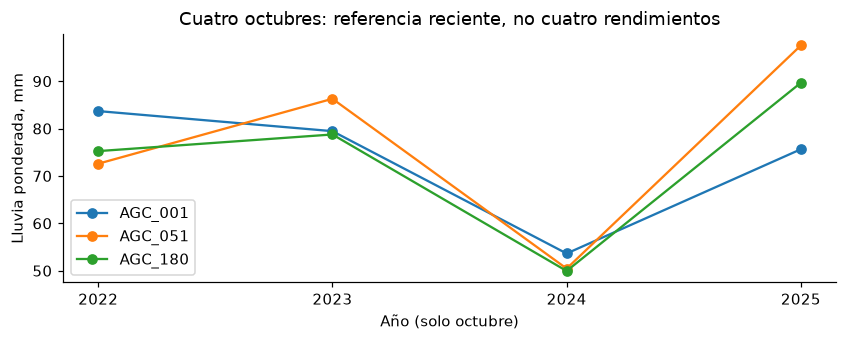

In [8]:
def variables_octubre(lluvia):
    cols = {"ID_POLIGONO","anio","P_mm","estado"}
    if not cols <= set(lluvia) or lluvia.empty or lluvia.duplicated(["ID_POLIGONO","anio"]).any():
        raise ValueError("Lluvia vacía, incompleta o duplicada")
    if not lluvia.estado.eq("ok").all() or set(lluvia.anio) != {2022,2023,2024,2025}:
        raise ValueError("Año ausente o cobertura detenida")
    P = lluvia.pivot(index="ID_POLIGONO",columns="anio",values="P_mm").reindex(columns=[2022,2023,2024,2025])
    if not np.isfinite(P.to_numpy(float)).all():
        raise ValueError("Falta lluvia de uno o más años; no se imputa")
    H = (P[2022]+P[2023]+P[2024])/3
    if H.lt(1).any():
        raise ValueError("Referencia histórica menor de 1 mm")
    V = P.rename(columns={a:f"P_{a}_mm" for a in P.columns}).copy()
    V["H_mm"], V["A_mm"] = H, P[2025]-H
    V["A_pct"], V["P_actual_mm"] = 100*V.A_mm/H, P[2025]
    return V

variables = variables_octubre(lluvia)
control_var = leer_csv("variables_control","control_posterior").set_index("ID_POLIGONO").sort_index()
assert variables.index.equals(control_var.index) and len(variables) == 197
np.testing.assert_allclose(variables,control_var[variables.columns],atol=1e-9,rtol=0)
display(variables.loc[["AGC_001","AGC_051","AGC_180"]])
display(pd.DataFrame({"H_mm":[50.,100.],"A_mm":[20.,20.],"A_pct":[40.,20.]}))
print("Ejemplo inventado de denominador, separado de las parcelas reales.")
fig,ax = plt.subplots(figsize=(7.8,3.2))
for pid in ["AGC_001","AGC_051","AGC_180"]:
    ax.plot([2022,2023,2024,2025],variables.loc[pid,[f"P_{a}_mm" for a in (2022,2023,2024,2025)]],"o-",label=pid)
ax.set(xlabel="Año (solo octubre)",ylabel="Lluvia ponderada, mm",title="Cuatro octubres: referencia reciente, no cuatro rendimientos")
ax.set_xticks([2022,2023,2024,2025]); ax.legend(); fig.tight_layout(); plt.show()

## 4. Cinco recetas: qué cambia y qué se conserva

| Código | Región | Numérica | Ajuste histórico |
| --- | --- | --- | --- |
| J5_PCT | Cinco grupos de Jared | A_pct | OLS |
| J9_PCT | Nueve municipios | A_pct | OLS |
| R9_PCT | Municipio | A_pct | Ridge |
| R9_MM | Municipio | A_mm | Ridge |
| R9_RAW | Municipio | P_actual_mm | Ridge |

GLOBAL, MUN y MIX conservan sus recetas; G5 es la media del grupo; R_B/E2 es
control histórico, no un sexto candidato. **J5−J9 cambia una agrupación completa**:
medias, residuos, escala y respaldo cuando el grupo no está en entrenamiento.
No aísla un mecanismo causal. Ningún contraste suma H manteniendo todo lo demás fijo.

In [9]:
J5 = {"Chignahuapan":"Chignahuapan","Singuilucan":"Singuilucan","Almoloya":"Almoloya",
      "Calpulalpan":"Tlaxcala","Nanacamilpa de Mariano Arista":"Tlaxcala",
      "Cuautepec de Hinojosa":"Otros_Hidalgo","Emiliano Zapata":"Otros_Hidalgo",
      "Apan":"Otros_Hidalgo","Tepeapulco":"Otros_Hidalgo"}
np.testing.assert_array_equal(grupos.Municipio.map(J5),grupos.grupo_J5)
assert grupos.Municipio.nunique() == 9 and grupos.grupo_J5.nunique() == 5
display(grupos.groupby(["grupo_J5","Municipio","CONJUNTO"]).size().rename("parcelas").to_frame())
CANDIDATOS = ["J5_PCT","J9_PCT","R9_PCT","R9_MM","R9_RAW"]
MODELOS = ["GLOBAL","MUN","MIX","G5","R_B"]+CANDIDATOS
ESPEC = {"J5_PCT":("grupo_J5","A_pct"),"J9_PCT":("Municipio","A_pct"),
         "R9_PCT":("Municipio","A_pct"),"R9_MM":("Municipio","A_mm"),"R9_RAW":("Municipio","P_actual_mm")}

parcelas
grupo_J5      Municipio                     CONJUNTO               
Almoloya      Almoloya                      ENTRENAMIENTO        10
                                            PREDICCION            4
Chignahuapan  Chignahuapan                  ENTRENAMIENTO        71
                                            PREDICCION           29
Otros_Hidalgo Apan                          ENTRENAMIENTO         1
              Cuautepec de Hinojosa         ENTRENAMIENTO         5
                                            PREDICCION            4
              Emiliano Zapata               ENTRENAMIENTO         3
              Tepeapulco                    ENTRENAMIENTO         1
Singuilucan   Singuilucan                   ENTRENAMIENTO        16
                                            PREDICCION            7
Tlaxcala      Calpulalpan                   ENTRENAMIENTO        30
                                            PREDICCION           14
              Nanacamilpa de Mariano Arista ENTRENAMIENTO         1
                                            PREDICCION            1

En cada entrenamiento original se calcularon medias del grupo, luego
$u=X-\bar X_g$, $v=y-\bar y_g$, escala $s=\sqrt{\mathrm{media}(u^2)}$,
$z=u/s$. OLS: $\beta=\sum zv/\sum z^2$; Ridge: $\beta=\sum zv/(\sum z^2+\alpha)$.
Predicción: $\bar y_g+\beta(X-\bar X_g)/s$.

Todas las medias y escalas pertenecen al entrenamiento del pliegue; los singleton
aportan u=0 y se incluyen en la escala. Si s≤1e−12·max(1,max|X_train|), pendiente
cero. Grupo no visto → media global sin corrección. «Baseline» también pone β=0.
La pendiente en unidades originales es **β/s**, no β.

Mostramos parámetros históricos, sin volver a estimarlos. A_pct se mide en puntos
porcentuales; A_mm, en milímetros. Comparar β directamente confunde escalas.

In [10]:
parametros = leer_csv("parametros","parametros_guardados")
assert len(parametros) == 250 and set(parametros.modelo) == set(CANDIDATOS)
assert not parametros.duplicated(["modelo","repeticion","pliegue"]).any()
assert np.isfinite(parametros[["beta","escala"]]).all().all() and parametros.escala.gt(0).all()
assert not parametros.degenerada.any()
for m,(region,num) in ESPEC.items():
    q = parametros.loc[parametros.modelo.eq(m)]
    assert len(q) == 50 and q.region.eq(region).all() and q.numerica.eq(num).all()
parametros["pendiente_unidad_original"] = parametros.beta/parametros.escala
display(parametros.groupby("modelo").agg(beta_mediana=("beta","median"),escala_mediana=("escala","median"),
          pendiente_unidad_original_mediana=("pendiente_unidad_original","median"),
          beta_cero=("beta",lambda s:int(s.eq(0).sum())),no_vistos=("n_validacion_grupo_no_visto","sum")))
display(parametros.loc[parametros.repeticion.eq(0)&parametros.pliegue.eq(0),
                      ["modelo","beta","escala","pendiente_unidad_original","alpha_elegido"]])

,beta_mediana,escala_mediana,pendiente_unidad_original_mediana,beta_cero,no_vistos
modelo,,,,,
J5_PCT,0.194675,11.490918,0.016790,0,0
J9_PCT,0.113086,7.468228,0.014853,0,30
R9_MM,0.028856,4.034496,0.006960,15,30
R9_PCT,0.096095,7.468228,0.012935,1,30
R9_RAW,0.000000,9.256042,0.000000,32,30


,modelo,beta,escala,pendiente_unidad_original,alpha_elegido
0,J5_PCT,0.185178,12.089420,0.015317,ols
50,J9_PCT,0.087162,7.465353,0.011675,ols
100,R9_PCT,0.045656,7.465353,0.006116,100.0
150,R9_MM,0.035383,4.035240,0.008768,100.0
200,R9_RAW,0.000000,9.366879,0.000000,baseline


## 5. Misma validación, selección interior y presupuesto explícito

Parcela es la unidad. Se conservan los CSV de 5 pliegues × 10 repeticiones,
con cuatro pliegues interiores contenidos en cada entrenamiento exterior.
Más OOF no son más etiquetas. No regeneramos semillas ni escogemos particiones favorables.

In [11]:
ids = set(etiquetas.ID_POLIGONO)
assert len(externas) == 6900 and len(internas) == 22080
assert not externas.duplicated(["repeticion", "pliegue", "ID_POLIGONO"]).any()
assert not internas.duplicated(["repeticion", "pliegue", "pliegue_interno", "ID_POLIGONO"]).any()
assert set(externas.rol) == set(internas.rol) == {"entrenamiento", "validacion"}
assert set(externas.repeticion) == set(range(10)) and set(externas.pliegue) == set(range(5))
assert set(internas.pliegue_interno) == set(range(4))
assert set(internas.groupby(["repeticion", "pliegue"]).groups) == set(externas.groupby(["repeticion", "pliegue"]).groups)
for (r, f), parte in externas.groupby(["repeticion", "pliegue"]):
    train_ids = set(parte.loc[parte.rol.eq("entrenamiento"), "ID_POLIGONO"])
    val_ids = set(parte.loc[parte.rol.eq("validacion"), "ID_POLIGONO"])
    assert train_ids.isdisjoint(val_ids) and train_ids | val_ids == ids
    dentro = internas.loc[internas.repeticion.eq(r) & internas.pliegue.eq(f)]
    assert set(dentro.ID_POLIGONO) == train_ids
    for _, iparte in dentro.groupby("pliegue_interno"):
        assert set(iparte.ID_POLIGONO) == train_ids
    frecuencia = dentro.loc[dentro.rol.eq("validacion")].groupby("ID_POLIGONO").size()
    assert set(frecuencia.index) == train_ids and frecuencia.eq(1).all()
claves = ["repeticion", "pliegue", "ID_POLIGONO"]
validaciones = externas.loc[externas.rol.eq("validacion"), claves].copy()
frecuencia = validaciones.groupby(["repeticion", "ID_POLIGONO"]).size()
assert len(validaciones) == len(frecuencia) == 1380 and frecuencia.eq(1).all()
ejemplo_roles = externas.loc[externas.repeticion.eq(0) & externas.pliegue.eq(0)]
display(ejemplo_roles.groupby("rol").size().rename("parcelas").to_frame())
display(internas.loc[internas.repeticion.eq(0) & internas.pliegue.eq(0)]
        .groupby(["pliegue_interno", "rol"]).size().rename("parcelas").to_frame())

,parcelas
rol,
entrenamiento,110
validacion,28


parcelas
pliegue_interno rol                    
0               entrenamiento        82
                validacion           28
1               entrenamiento        82
                validacion           28
2               entrenamiento        83
                validacion           27
3               entrenamiento        83
                validacion           27

Ridge seleccionó entre `baseline, 0.01, 0.1, 1, 10, 100` por **RMSE de todos los
errores interiores concatenados**, no promedio de cuatro RMSE. Empate a 1e−12:
baseline, luego alpha mayor. OLS no tiene selección de alpha.

Aquí comprobamos 150 decisiones desde 900 scores guardados; además 50 decisiones
R_B desde 250 scores. No recalculamos los errores interiores que originaron esos
scores. Candidatos históricos: 3,600 evaluaciones interiores (600 baseline sin
ajuste, 3,000 Ridge) y 250 reajustes exteriores. Controles originales aparte.
**Presupuesto actual de entrenamiento: cero.**

In [12]:
GRID = ["baseline",.01,.1,1.,10.,100.]

def seleccionar_alpha_guardado(scores):
    v = np.asarray(scores,dtype=float)
    if v.shape != (6,) or not np.isfinite(v).all() or (v < 0).any():
        raise ValueError("Seis RMSE guardados finitos y no negativos requeridos")
    empatados = [GRID[i] for i in range(6) if v[i] <= v.min()+1e-12]
    return "baseline" if "baseline" in empatados else max(empatados)

seleccion = leer_csv("seleccion","scores_guardados")
assert len(seleccion) == 900 and set(seleccion.modelo) == {"R9_PCT","R9_MM","R9_RAW"}
assert not seleccion.duplicated(["modelo","repeticion","pliegue","alpha"]).any()
decisiones = []
for (m,r,f),q in seleccion.groupby(["modelo","repeticion","pliegue"]):
    q = q.copy(); q["clave"] = q.alpha.map(lambda a:"baseline" if a == "baseline" else float(a))
    assert set(q.clave) == set(GRID) and len(q) == 6
    valores = q.set_index("clave").loc[GRID,"rmse_interior"].to_numpy()
    elegido = seleccionar_alpha_guardado(valores)
    filas = q.loc[q.elegido]
    assert len(filas) == 1 and filas.clave.iloc[0] == elegido
    param = parametros.loc[parametros.modelo.eq(m)&parametros.repeticion.eq(r)&parametros.pliegue.eq(f)]
    assert len(param) == 1
    almacenado = param.alpha_elegido.iloc[0]
    assert elegido == ("baseline" if almacenado == "baseline" else float(almacenado))
    decisiones.append({"modelo":m,"repeticion":r,"pliegue":f,"elegido":str(elegido)})
decisiones = pd.DataFrame(decisiones)
assert len(decisiones) == 150
rb = leer_csv("rb_seleccion","scores_guardados")
v1sel = leer_csv("v1_seleccion","scores_guardados").query("modelo == 'R_B'")
ctrl_rb = rb.merge(v1sel,on=["repeticion","pliegue"],validate="one_to_one")
assert len(ctrl_rb) == 50
for _,q in ctrl_rb.iterrows():
    vals = json.loads(q.scores_internos_x); antes = json.loads(q.scores_internos_y)
    assert len(vals) == len(antes) == 5
    np.testing.assert_allclose(vals,antes,atol=1e-8,rtol=0)
    ix = next(i for i,s in enumerate(vals) if s <= min(vals)+1e-12)
    assert [100.,10.,1.,.1,.01][ix] == q.alpha == json.loads(q.parametros)["alpha"]
assert REG["presupuesto"] == {"evaluaciones_internas":3600,"evaluaciones_baseline":600,
                              "ajustes_ridge_internos":3000,"reajustes_exteriores":250}
display(decisiones.groupby(["modelo","elegido"]).size().rename("pliegues").to_frame())
print("200 decisiones verificadas desde 1,150 scores guardados; cero selección nueva.")

pliegues
modelo elegido           
R9_MM  0.01             2
       10.0             8
       100.0           25
       baseline        15
R9_PCT 0.01             5
       1.0              4
       10.0            23
       100.0           17
       baseline         1
R9_RAW 0.01             1
       10.0             4
       100.0           13
       baseline        32

200 decisiones verificadas desde 1,150 scores guardados; cero selección nueva.


## 6. Resultado registrado: cada error conserva su parcela y pliegue

Se abren las OOF después de construir variables. Verificamos claves, etiquetas,
región y pertenencia a validación; comparamos las tres referencias y R_B con V1.
Este lector puntúa predicciones **guardadas**: no las vuelve a producir ni vuelve
a aprender pendientes. Igualdad de métricas no demuestra paridad del entrenamiento
entre Python histórico 3.12.3 y el lector 3.13.

In [13]:
oof = leer_csv("oof","resultados_guardados")
assert len(oof) == 13800 and set(oof.modelo) == set(MODELOS)
assert not oof.duplicated(["modelo"]+claves).any()
esperado = set(map(tuple,validaciones[claves].to_numpy()))
y = etiquetas.set_index("ID_POLIGONO").RENDIMIENTO_T_HA
for m,q in oof.groupby("modelo"):
    assert len(q) == 1380 and q.ID_POLIGONO.nunique() == 138
    assert set(map(tuple,q[claves].to_numpy())) == esperado
    np.testing.assert_array_equal(q.observado,q.ID_POLIGONO.map(y))
    np.testing.assert_array_equal(q.Municipio,q.ID_POLIGONO.map(grupos.Municipio))
    np.testing.assert_array_equal(q.grupo_J5,q.ID_POLIGONO.map(grupos.grupo_J5))
    np.testing.assert_array_equal(q.celda,q.ID_POLIGONO.map(grupos.celda_centroide))
    assert np.isfinite(q.predicho).all()
v1oof = leer_csv("v1_oof","resultados_guardados")
for m in ["GLOBAL","MUN","MIX","R_B"]:
    a = oof.loc[oof.modelo.eq(m)].set_index(claves).sort_index()
    b = v1oof.loc[v1oof.modelo.eq(m)].set_index(claves).sort_index()
    assert a.index.equals(b.index)
    np.testing.assert_allclose(a.predicho,b.predicho,atol=1e-8,rtol=0)
    np.testing.assert_array_equal(a.observado,b.observado)
print("13,800 OOF conciliadas. R_B y tres referencias conservan sus predicciones a tolerancia 1e-8.")

def metricas(df):
    y,p = df.observado.to_numpy(float),df.predicho.to_numpy(float)
    if len(y) == 0 or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError("Métricas vacías o no finitas")
    error = p-y; den = np.sum((y-y.mean())**2)
    return pd.Series({"RMSE":np.sqrt(np.mean(error**2)),"MAE":np.mean(np.abs(error)),
                      "R2":1-np.sum(error**2)/den if den > 1e-12 else np.nan})

def tabla_metricas(df):
    return pd.DataFrame({m:metricas(q) for m,q in df.groupby("modelo")}).T.reindex(MODELOS)

globales = tabla_metricas(oof)
control_m = leer_csv("metricas_control","control_posterior").set_index("modelo").loc[MODELOS]
np.testing.assert_allclose(globales,control_m[["RMSE","MAE","R2"]],atol=1e-12,rtol=0)
por_rep = pd.DataFrame([{"modelo":m,"repeticion":r,**metricas(q).to_dict()}
                       for (m,r),q in oof.groupby(["modelo","repeticion"])])
display(globales)
print("Errores individuales agrupados; no promedio de predicciones por parcela ni de RMSE por pliegue.")

13,800 OOF conciliadas. R_B y tres referencias conservan sus predicciones a tolerancia 1e-8.


,RMSE,MAE,R2
GLOBAL,0.854426,0.753994,-0.015043
MUN,0.511757,0.335394,0.635865
MIX,0.493845,0.341711,0.660908
G5,0.523554,0.360176,0.618884
R_B,0.519202,0.359676,0.625193
J5_PCT,0.479661,0.329113,0.680107
J9_PCT,0.502395,0.342058,0.649065
R9_PCT,0.503924,0.338743,0.646926
R9_MM,0.511768,0.335660,0.635849
R9_RAW,0.513305,0.338042,0.633658


Errores individuales agrupados; no promedio de predicciones por parcela ni de RMSE por pliegue.


## 7. ¿Supera la regla original?

Regla interna, no criterio oficial del jurado: RMSE < MIX y MAE ≤ MUN globalmente,
cada condición en al menos 8/10 repeticiones. Repeticiones comparten etiquetas:
son estabilidad descriptiva, no diez estudios ni p-valores independientes.

,reps_RMSE_menor_MIX,reps_MAE_menor_o_igual_MUN,cumple
modelo,,,
J5_PCT,10,10,True
J9_PCT,2,0,False
R9_PCT,1,2,False
R9_MM,0,6,False
R9_RAW,0,1,False


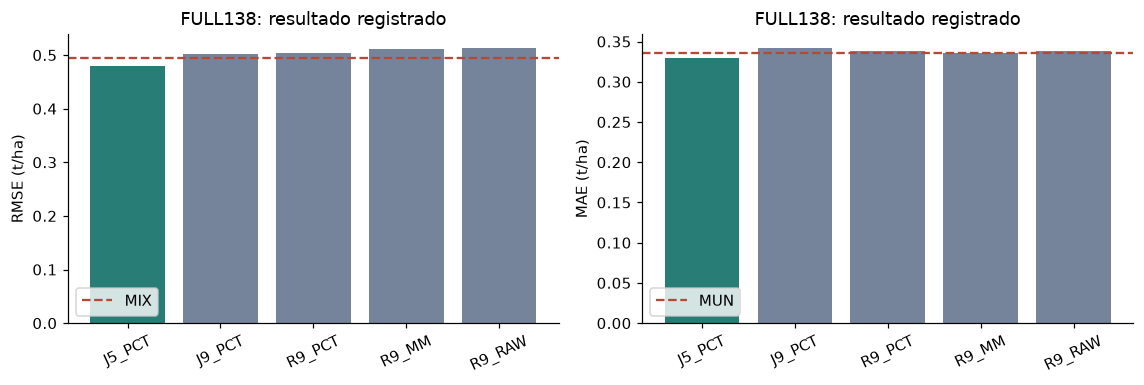

In [14]:
def regla_avance(df):
    g = tabla_metricas(df)
    reps = pd.DataFrame([{"modelo":m,"repeticion":r,**metricas(q).to_dict()}
                         for (m,r),q in df.groupby(["modelo","repeticion"])])
    R = reps.pivot(index="repeticion",columns="modelo",values="RMSE")
    A = reps.pivot(index="repeticion",columns="modelo",values="MAE")
    if set(R.index) != set(range(10)) or R.isna().any().any() or A.isna().any().any():
        raise ValueError("Repeticiones/modelos incompletos")
    filas = []
    for m in CANDIDATOS:
        nr,na = int((R[m]<R.MIX).sum()),int((A[m]<=A.MUN).sum())
        cumple = bool(g.loc[m,"RMSE"]<g.loc["MIX","RMSE"] and g.loc[m,"MAE"]<=g.loc["MUN","MAE"] and nr>=8 and na>=8)
        filas.append({"modelo":m,"reps_RMSE_menor_MIX":nr,"reps_MAE_menor_o_igual_MUN":na,"cumple":cumple})
    return pd.DataFrame(filas).set_index("modelo")

regla_full = regla_avance(oof)
ctrl_regla = leer_csv("regla_control","control_posterior").set_index("modelo").loc[CANDIDATOS]
np.testing.assert_array_equal(regla_full.iloc[:,:2],ctrl_regla[regla_full.columns[:2]])
np.testing.assert_array_equal(regla_full.cumple,ctrl_regla.avance_candidato)
assert regla_full.index[regla_full.cumple].tolist() == ["J5_PCT"]
display(regla_full)
fig,axes = plt.subplots(1,2,figsize=(10.5,3.6))
for ax,c,ref in zip(axes,["RMSE","MAE"],["MIX","MUN"]):
    ax.bar(CANDIDATOS,globales.loc[CANDIDATOS,c],color=["#287d77"]+["#75849b"]*4)
    ax.axhline(globales.loc[ref,c],color="#b64834",ls="--",label=ref)
    ax.set(ylabel=f"{c} (t/ha)",title="FULL138: resultado registrado")
    ax.tick_params(axis="x",rotation=25); ax.legend()
fig.tight_layout(); plt.show()

**J5_PCT cumple la regla original.** No borramos ese resultado porque un diagnóstico
posterior sea menos favorable. Para interpretar el avance hay que revisar el intercambio
RMSE/MAE, el cambio conjunto de agrupación y dónde se concentran los errores.

In [15]:
# Etiquetas corregidas; no se altera el CSV histórico del contraste.
PARES = [("J9_PCT","J5_PCT","Cambio conjunto de agrupación"),
         ("R9_PCT","J9_PCT","Regularización + selección"),
         ("R9_MM","R9_PCT","Cambio de representación, con intercambio RMSE/MAE"),
         ("R9_RAW","R9_MM","Reemplazar desviación por lluvia actual")]
ctrl_c = leer_csv("contrastes_control","control_posterior").set_index(["modelo","base"])
contrastes = []
for m,b,descripcion in PARES:
    delta = globales.loc[m]-globales.loc[b]
    np.testing.assert_allclose(delta[["RMSE","MAE"]],ctrl_c.loc[(m,b),["delta_RMSE","delta_MAE"]].to_numpy(float),atol=1e-12,rtol=0)
    contrastes.append({"nuevo":m,"base":b,"lectura":descripcion,"delta_RMSE":delta.RMSE,"delta_MAE":delta.MAE})
display(pd.DataFrame(contrastes))
assert globales.loc["R9_PCT","RMSE"]<globales.loc["R9_MM","RMSE"]
assert globales.loc["R9_PCT","MAE"]>globales.loc["R9_MM","MAE"]
print("Porcentual reduce RMSE frente a mm, pero empeora MAE; no prueba aporte independiente de H.")

,nuevo,base,lectura,delta_RMSE,delta_MAE
0,J9_PCT,J5_PCT,Cambio conjunto de agrupación,0.022734,0.012946
1,R9_PCT,J9_PCT,Regularización + selección,0.001529,-0.003315
2,R9_MM,R9_PCT,"Cambio de representación, con intercambio RMSE...",0.007844,-0.003083
3,R9_RAW,R9_MM,Reemplazar desviación por lluvia actual,0.001538,0.002383


Porcentual reduce RMSE frente a mm, pero empeora MAE; no prueba aporte independiente de H.


## 8. Diagnóstico posterior: municipio presente en entrenamiento

Apan, Nanacamilpa y Tepeapulco tienen una etiqueta cada uno. Cuando esa parcela
se valida, su municipio desaparece de entrenamiento: 30 OOF por procedimiento.
La máscara se deriva de **IDs, municipio y roles**, no de los errores. Su aplicación
como análisis se decidió después de ver V2: es **diagnóstico posterior**, no reemplazo
retrospectivo de la evaluación registrada.

SEEN135 conserva las OOF con municipio visto; no retira etiquetas de entrenamiento
ni reentrena. Es una aproximación parcial, **no equivale a las 59 ocultas**. AGC_120
pertenece a Nanacamilpa, con solo AGC_048 conocida y otra celda. No existe una OOF
equivalente para evaluar ese caso entrenando con la única etiqueta municipal.

In [16]:
vistos = []
for (r,f),q in externas.groupby(["repeticion","pliegue"]):
    mun_train = set(q.loc[q.rol.eq("entrenamiento"),"ID_POLIGONO"].map(grupos.Municipio))
    v = q.loc[q.rol.eq("validacion"),claves].copy()
    v["municipio_visto"] = v.ID_POLIGONO.map(grupos.Municipio).isin(mun_train)
    vistos.append(v)
mascara = pd.concat(vistos,ignore_index=True)
assert not mascara.duplicated(claves).any() and len(mascara) == 1380
assert mascara.municipio_visto.sum() == 1350
oof_esc = oof.merge(mascara,on=claves,validate="many_to_one")
seen = oof_esc.loc[oof_esc.municipio_visto].copy()
assert len(seen) == 13500 and seen.ID_POLIGONO.nunique() == 135
regla_seen = regla_avance(seen)
metricas_seen = tabla_metricas(seen)
ctrl_post = leer_csv("metricas_escenarios_control","control_posterior_diagnostico")
q = ctrl_post.loc[ctrl_post.escenario.eq("solo municipio visto (posterior)")].set_index("modelo").loc[MODELOS]
np.testing.assert_allclose(metricas_seen,q[["RMSE","MAE","R2"]],atol=1e-12,rtol=0)
ctrl_post_r = leer_csv("regla_escenarios_control","control_posterior_diagnostico")
q = ctrl_post_r.loc[ctrl_post_r.escenario.eq("solo municipio visto (posterior)")].set_index("modelo").loc[CANDIDATOS]
np.testing.assert_array_equal(regla_seen.iloc[:,:2],q[regla_seen.columns[:2]])
np.testing.assert_array_equal(regla_seen.cumple,q.cumpliria_regla)
assert not regla_seen.cumple.any()
display(pd.concat({"FULL138 registrado":globales.loc[["J5_PCT","MIX","MUN"]],
                   "SEEN135 posterior":metricas_seen.loc[["J5_PCT","MIX","MUN"]]},names=["escenario"]))
display(regla_seen)
display(grupos.loc[["AGC_048","AGC_120"],["Municipio","CONJUNTO","celda_centroide"]])
print("Sin reentrenar: J5 conserva RMSE menor, pero su MAE es peor que MUN en 10/10 repeticiones.")

RMSE       MAE        R2
escenario                                              
FULL138 registrado J5_PCT  0.479661  0.329113  0.680107
                   MIX     0.493845  0.341711  0.660908
                   MUN     0.511757  0.335394  0.635865
SEEN135 posterior  J5_PCT  0.481145  0.328772  0.674283
                   MIX     0.487197  0.334215  0.666039
                   MUN     0.493404  0.321274  0.657475

,reps_RMSE_menor_MIX,reps_MAE_menor_o_igual_MUN,cumple
modelo,,,
J5_PCT,8,0,False
J9_PCT,6,0,False
R9_PCT,6,2,False
R9_MM,2,6,False
R9_RAW,1,1,False


,Municipio,CONJUNTO,celda_centroide
ID_POLIGONO,,,
AGC_048,Nanacamilpa de Mariano Arista,ENTRENAMIENTO,R36_C28
AGC_120,Nanacamilpa de Mariano Arista,PREDICCION,R37_C28


Sin reentrenar: J5 conserva RMSE menor, pero su MAE es peor que MUN en 10/10 repeticiones.


## 9. ¿La mejora está distribuida?

Comparamos J5 con MIX en las mismas claves. Sumar cambios de error cuadrático
permite localizar el beneficio; no es rendimiento explicado ni causalidad.
El porcentaje de los singleton usa la mejora **neta**. El de las mejores parcelas
o celdas usa la mejora **bruta** entre casos que mejoran: denominadores distintos.
Quitar los cinco más favorecidos es diagnóstico posterior, solo de evaluación.

In [17]:
a = oof.query("modelo == 'J5_PCT'").set_index(claves).sort_index()
b = oof.query("modelo == 'MIX'").set_index(claves).sort_index()
assert a.index.equals(b.index)
d = a[["observado","predicho","celda","Municipio"]].copy()
d["delta_se"] = (a.predicho-a.observado)**2-(b.predicho-b.observado)**2
por_parcela = d.reset_index().groupby("ID_POLIGONO").agg(delta_se=("delta_se","sum"),celda=("celda","first"))
neto = float(por_parcela.delta_se.sum())
singletons = ["AGC_164","AGC_048","AGC_047"]
contrib_singletons = float(por_parcela.loc[singletons,"delta_se"].sum())
top5 = por_parcela.nsmallest(5,"delta_se")
bruta = -float(por_parcela.loc[por_parcela.delta_se.lt(0),"delta_se"].sum())
celdas = por_parcela.groupby("celda").delta_se.sum()
bruta_celdas = -float(celdas.loc[celdas.lt(0)].sum())
fraccion_top2_celdas_bruta = -float(celdas.nsmallest(2).sum())/bruta_celdas
assert neto < 0 and neto-top5.delta_se.sum() > 0
assert por_parcela.loc["AGC_164","delta_se"] > 0
display(por_parcela.loc[singletons])
display(top5)
display(pd.DataFrame([{"delta_SE_neto":neto,"singleton_fraccion_neta":contrib_singletons/neto,
                       "top5_fraccion_bruta":-top5.delta_se.sum()/bruta,
                       "top2_celdas_fraccion_bruta":fraccion_top2_celdas_bruta,
                       "neto_sin_top5_solo_evaluacion":neto-top5.delta_se.sum(),
                       "parcelas_mejoran":int(por_parcela.delta_se.lt(0).sum()),
                       "parcelas_empeoran":int(por_parcela.delta_se.gt(0).sum())}]))
train_ids = set(etiquetas.ID_POLIGONO)
celdas_inter_train = pesos.loc[pesos.ID_POLIGONO.isin(train_ids),["fila","col"]].drop_duplicates()
assert len(celdas_inter_train) == 27 and grupos.loc[list(train_ids),"celda_centroide"].nunique() == 23
display(pd.DataFrame({"conteo":["Centroides, 138 etiquetas","Píxeles de intersección, 138 etiquetas",
                               "Píxeles de intersección, 197 parcelas"],"celdas":[23,27,29]}))

,delta_se,celda
ID_POLIGONO,,
AGC_164,0.146873,R35_C28
AGC_048,-8.848225,R36_C28
AGC_047,-2.443981,R31_C31


,delta_se,celda
ID_POLIGONO,,
AGC_048,-8.848225,R36_C28
AGC_069,-2.792599,R30_C34
AGC_123,-2.764683,R36_C27
AGC_172,-2.748958,R30_C34
AGC_047,-2.443981,R31_C31


,delta_SE_neto,singleton_fraccion_neta,top5_fraccion_bruta,top2_celdas_fraccion_bruta,neto_sin_top5_solo_evaluacion,parcelas_mejoran,parcelas_empeoran
0,-19.055698,0.584882,0.324258,0.5397,0.542748,68,70


,conteo,celdas
0,"Centroides, 138 etiquetas",23
1,"Píxeles de intersección, 138 etiquetas",27
2,"Píxeles de intersección, 197 parcelas",29


Las tres parcelas singleton aportan **58.49 % del beneficio neto**; una de ellas
(AGC_164) empeora. Sin los cinco casos más favorables, J5 pierde frente a MIX en
suma de errores cuadrados. No se eliminan esos casos para entrenar ni se redefine
la regla. **23 celdas de centroide no son un tamaño muestral efectivo de 23.**
La extracción utiliza 27 píxeles para las etiquetas y 29 para todas las parcelas;
también puede haber dependencia entre píxeles.

La sensibilidad sin AGC_127/171 sí estaba prevista: conserva las mismas OOF,
retirando esas dos parcelas **solo al evaluar**. No sustituye el resultado principal.

In [18]:
sensibilidad = tabla_metricas(oof.loc[~oof.ID_POLIGONO.isin(["AGC_127","AGC_171"])])
ctrl_sens = leer_csv("sensibilidad_control","control_posterior").set_index("modelo").loc[MODELOS]
np.testing.assert_allclose(sensibilidad,ctrl_sens[["RMSE","MAE","R2"]],atol=1e-12,rtol=0)
zonas = pd.DataFrame([{"modelo":m,"zona":z,**metricas(q).to_dict()}
                      for (m,z),q in oof.groupby(["modelo","zona"])])
display(sensibilidad.loc[["J5_PCT","MIX","MUN"]])
display(zonas.loc[zonas.modelo.isin(["J5_PCT","MIX","MUN"])].set_index(["modelo","zona"]))

,RMSE,MAE,R2
J5_PCT,0.430526,0.308383,0.730068
MIX,0.452476,0.322915,0.701841
MUN,0.464585,0.314856,0.685670


RMSE       MAE        R2
modelo zona                                      
J5_PCT Chignahuapan  0.574432  0.384969  0.020001
       Resto         0.352438  0.269922  0.765603
MIX    Chignahuapan  0.573628  0.389104  0.022745
       Resto         0.391961  0.291488  0.710085
MUN    Chignahuapan  0.590198  0.381019 -0.034531
       Resto         0.412669  0.287046  0.678641

## 10. Decisión y límites

**J5_PCT cumple la regla histórica y permanece como candidato exploratorio con
reservas; no es modelo final.** El diagnóstico posterior no revoca su resultado:
limita qué podemos creer sobre su aplicación a las parcelas sin etiqueta.

- PCT mejora RMSE frente a mm, pero empeora MAE; H no fue probado aquí como aporte separado.
- Cambiar de agrupación cambia medias, residuos, escala y respaldos; no aísla causalidad.
- Beneficio concentrado y soporte climático compartido reducen la fuerza de la evidencia.
- Una temporada, tres años de referencia y selección adaptativa: no extrapolar a otras campañas o territorios.
- La política para municipios con una etiqueta requiere decisión explícita antes de predicciones finales.

Igualdad aritmética y hashes prueban reconstrucción e integridad, no medición sin error,
fecha externa ni validez crediticia. No descarta el clima, octubre ni toda familia lineal.
La continuación estudia H con una pregunta nueva; no se ejecuta ni selecciona aquí.

In [19]:
resumen = {"id":"EXP_04","modo":"lector_retrospectivo_sin_ajustes","parcelas":197,"etiquetas":138,
           "piezas_guardadas":230,"pixeles_derivados":116,"lluvias_recalculadas":788,
           "procedimientos":10,"oof_por_procedimiento":1380,"oof_total":13800,
           "particiones_externas":50,"particiones_internas":200,
           "decisiones_verificadas":200,"scores_guardados_verificados":1150,
           "ajustes_actuales":0,"predicciones_finales_generadas":0,"poblacion":"FULL138",
           "scores_interiores_recalculados":False,"predicciones_recalculadas":False,
           "intersecciones_recalculadas":False,"variables_recalculadas":True,"metricas_recalculadas":True,
           "candidato_con_reservas":["J5_PCT"],"variantes_adoptadas":[],
           "diagnostico_posterior":"SEEN135","oof_seen_por_procedimiento":1350,
           "regla_full_cumplen":regla_full.index[regla_full.cumple].tolist(),
           "regla_seen_cumplen":regla_seen.index[regla_seen.cumple].tolist(),
           "fecha_original":"2026-10-01","fecha_adaptacion":"2026-10-08",
           "metricas":globales.to_dict(orient="index"),"metricas_seen":metricas_seen.to_dict(orient="index"),
           "fecha_ejecucion_utc":datetime.now(timezone.utc).isoformat()}
print("RESUMEN_EXP_04_JSON="+json.dumps(resumen,sort_keys=True,ensure_ascii=False,allow_nan=False))

RESUMEN_EXP_04_JSON={"ajustes_actuales": 0, "candidato_con_reservas": ["J5_PCT"], "decisiones_verificadas": 200, "diagnostico_posterior": "SEEN135", "etiquetas": 138, "fecha_adaptacion": "2026-10-08", "fecha_ejecucion_utc": "2026-10-08T15:05:00.895103+00:00", "fecha_original": "2026-10-01", "id": "EXP_04", "intersecciones_recalculadas": false, "lluvias_recalculadas": 788, "metricas": {"G5": {"MAE": 0.36017564187137113, "R2": 0.6188837578860665, "RMSE": 0.523553511308425}, "GLOBAL": {"MAE": 0.7539942301985781, "R2": -0.015042909859176223, "RMSE": 0.854426183817986}, "J5_PCT": {"MAE": 0.3291128347821879, "R2": 0.6801074895039918, "RMSE": 0.47966097284188197}, "J9_PCT": {"MAE": 0.34205846628808206, "R2": 0.6490653140910159, "RMSE": 0.5023952163426304}, "MIX": {"MAE": 0.34171071524358665, "R2": 0.6609083799141192, "RMSE": 0.49384524493208876}, "MUN": {"MAE": 0.3353941346346938, "R2": 0.6358645937936154, "RMSE": 0.5117570123866723}, "R9_MM": {"MAE": 0.3356596069143956, "R2": 0.6358493646809

## Referencias y conceptos para profundizar (APA 7)

Equipo AgroCebada. (2026, 1 de octubre). *Protocolo definitivo V2: señal climática
de octubre* [Registro interno exploratorio]. Registro, hashes y resultados
identificados en los insumos de este cuaderno; no es necesario otro documento.

Equipo AgroCebada. (2026, 1 de octubre). *V2: fe de erratas y cierre de revisión*
[Nota interna]. Sus precisiones sobre métricas, agrupación, escenarios y soporte
espacial están incorporadas aquí; los archivos registrados no se reescriben.

NumPy Developers. (s. f.). *numpy.average*. https://numpy.org/doc/stable/reference/generated/numpy.average.html

NumPy Developers. (s. f.). *numpy.std*. https://numpy.org/doc/stable/reference/generated/numpy.std.html

Rasterio Developers. (s. f.). *Reading datasets*. https://rasterio.readthedocs.io/en/stable/topics/reading.html

**Glosario breve:** OOF = predicción para una parcela fuera del entrenamiento;
singleton = grupo con una etiqueta; OLS = mínimos cuadrados; Ridge = penalización
de pendiente; baseline = pendiente cero; beneficio neto = mejora menos empeoramiento;
beneficio bruto = solo casos que mejoran. FULL138 es la evaluación registrada;
SEEN135, un diagnóstico posterior. No son dos conjuntos ocultos independientes.